# KIPS Statistical Analysis

**Author:** Benjamin Stickland  
**Affiliation:** UNC Chapel Hill
**Date:** 2026

In [1]:
import os
import json
import textwrap
from pathlib import Path
import warnings
from collections import defaultdict

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import matplotlib
import seaborn as sns

import numpy as np
import pandas as pd
import umap
from itertools import combinations
from scipy.stats import fisher_exact, gaussian_kde, mannwhitneyu, spearmanr, pearsonr
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from statsmodels.stats.multitest import multipletests
from kneed import KneeLocator
from upsetplot import UpSet, from_contents

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs, Descriptors, Lipinski, BRICS
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.Chem import Draw

from tqdm import tqdm
tqdm.pandas()

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore', category=FutureWarning)

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Input Path

In [2]:
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'Data').is_dir() else Path.cwd().parent
DATA_DIR = str(PROJECT_DIR / 'Data')

KIPS_FILE = os.path.join(DATA_DIR, 'KIPS_Dataset.csv')
PKIS_FILE = os.path.join(DATA_DIR, 'PKIS.csv')
PKIS2_FILE = os.path.join(DATA_DIR, 'PKIS2.csv')
KCGS2_FILE = os.path.join(DATA_DIR, 'KCGS2.csv')
KINOBEADS_FILE = os.path.join(DATA_DIR, 'KinoBeads.csv')

# True uses the files behind the paper in Data/. False uses files regenerated by notebooks 01 and 02.
USE_PAPER_INPUTS = True

DERIVED_INPUT_DIR = DATA_DIR if USE_PAPER_INPUTS else str(PROJECT_DIR / 'Output' / 'Intermediate' / 'Regenerated_Inputs')
KINASE_INHIBITORS_FILE = os.path.join(DERIVED_INPUT_DIR, 'BindingDB_Kinase_Inhibitors.csv')
NON_KINASE_INHIBITORS_FILE = os.path.join(DERIVED_INPUT_DIR, 'BindingDB_Non_Kinase_Inhibitors.csv')
SMARTS_FILE = os.path.join(DATA_DIR, 'KCGS_SMARTS.csv')
BINDING_TYPE_FILE = os.path.join(DERIVED_INPUT_DIR, 'Binding_Type.csv')
CHEMBL_STATUS_FILE = os.path.join(DATA_DIR, 'ChEMBL-9_13_2026_Phase1-4.csv')
PROBES_PORTAL_FILE = os.path.join(DATA_DIR, 'ChemicalProbesPortal-9_13_2026.csv')

# Output Path

In [3]:
OUTPUT_ROOT = str(PROJECT_DIR / 'Output')
INTERMEDIATE_DIR = os.path.join(OUTPUT_ROOT, 'Intermediate')
KIPS_DIR = os.path.join(INTERMEDIATE_DIR, 'KIPS_Curated')
PANELS_DIR = os.path.join(INTERMEDIATE_DIR, 'Figure_Panels')
SUPPORTING_DIR = os.path.join(OUTPUT_ROOT, 'Supporting', 'Statistical_Analysis')
MAIN_FIGURES_DIR = os.path.join(OUTPUT_ROOT, 'Figures', 'Main')
SUPPLEMENTARY_FIGURES_DIR = os.path.join(OUTPUT_ROOT, 'Figures', 'Supplementary')
INFORMATION_TABLES_DIR = os.path.join(OUTPUT_ROOT, 'Tables', 'Supplementary_Information')
DATA_TABLES_DIR = os.path.join(OUTPUT_ROOT, 'Tables', 'Supplementary_Data')

for d in [KIPS_DIR, PANELS_DIR, SUPPORTING_DIR, MAIN_FIGURES_DIR, SUPPLEMENTARY_FIGURES_DIR, INFORMATION_TABLES_DIR, DATA_TABLES_DIR]:
    os.makedirs(d, exist_ok=True)

# Parameters

In [4]:
RANDOM_SEED         = 2026
FP_RADIUS           = 2
FP_NBITS            = 1024
P_VALUE_THRESHOLD   = 0.05
SI65_KNEE_SENSITIVITY = 5.0

NOISE_RESAMPLES = 1000
NOISE_SD        = 10.0
TOP_N           = 100
PROMISCUITY_METRICS = ['SI50', 'SI65', 'SI90', 'GINI']

# Plotting

In [5]:
MAIN_COLORS = {
    'black': '#000000',
    'orange': '#E69F00',
    'skyblue': '#56B4E9',
    'bluishgreen': '#009E73',
    'yellow': '#F0E442',
    'blue': '#0072B2', 
    'vermillion': '#D55E00', 
    'reddishpurple': '#CC79A7'
}

plt.rcParams.update({
    'font.size': 7,
    'font.family': 'Arial',
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'axes.titlesize': 7,
    'figure.dpi': 450,
    'savefig.dpi': 450,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

def create_cmap(hex_color):
    r, g, b = mcolors.to_rgb(hex_color)
    colors = [(1,1,1), ((1+r)/2, (1+g)/2, (1+b)/2), (r,g,b)]
    return LinearSegmentedColormap.from_list(f"kips_{hex_color.strip('#')}", colors, N=256)

# Load KIPS data

In [6]:
kips_raw_df = pd.read_csv(KIPS_FILE)
kips_raw_df.head()

,Compound ID,SMILES,AAK1,ABL1-E255K-phosphorylated,ABL1-F317I-nonphosphorylated,ABL1-F317I-phosphorylated,ABL1-F317L-nonphosphorylated,ABL1-F317L-phosphorylated,ABL1-H396P-nonphosphorylated,ABL1-H396P-phosphorylated,...,STK32C,YES1,STK25,MAP3K19,MAP3K20,ZAP70,MAPK14,MAPK11,MAPK13,MAPK12
0,(R)-9s,C[C@@H](c1cccc(CN)c1)[n]1cc(Cl)cc(c1=N)C(N)=O,0.0,13.0,15.0,11.0,25.0,17.0,45.0,21.0,...,0.0,12.0,0.0,24.0,14.0,8.0,0.0,0.0,0.0,0.0
1,(S)-9s,C[C@H](c1cccc(CN)c1)[n]1cc(Cl)cc(c1=N)C(N)=O,0.0,18.0,24.0,0.0,15.0,100.0,46.0,24.0,...,0.0,7.0,0.0,6.0,29.0,16.0,0.0,7.0,2.0,27.0
2,1-NA-PP1,CC(C)(C)[n]1[n]c(c2c(N)[n]c[n]c12)-c1cccc2ccccc21,22.0,25.0,10.0,0.0,23.0,23.0,23.0,38.0,...,22.0,12.0,0.0,34.0,4.0,0.0,19.0,2.0,40.0,10.0
3,1093222-27-5,N#Cc1ccc(cc1)-c1cc2c([nH]cc2NC(=O)c2c[n]ccc2)[...,10.0,22.0,0.0,0.0,0.0,0.0,15.0,0.0,...,0.0,10.0,11.0,0.0,22.0,0.0,9.0,18.0,0.0,23.0
4,31139,CN1CCN(CC1)c1cc(OC)c(cc1)Nc1[n]c(cc[n]1)-c1c[n...,33.0,17.0,10.0,0.0,0.0,1.0,22.0,0.0,...,28.0,31.0,0.0,15.0,0.0,0.0,2.0,0.0,0.0,0.0


# Data curation

Standardize charges (`ChargeParent`) then neutralize salts (`Uncharger`), 
deduplicate on InChIKey

In [7]:
_uncharger = rdMolStandardize.Uncharger()

def _standardize_mol(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None, None, None
    mol = rdMolStandardize.ChargeParent(mol)
    mol = _uncharger.uncharge(mol)
    return mol, Chem.MolToSmiles(mol, canonical=True), Chem.MolToInchiKey(mol)

kips_df = kips_raw_df.copy()
results = kips_df['SMILES'].progress_apply(_standardize_mol)
kips_df[['mol_std', 'SMILES_standardized', 'InChI_Key']] = pd.DataFrame(
    results.tolist(), index=kips_df.index)
kips_df.drop(columns=['SMILES'], inplace=True)
kips_df.dropna(subset=['mol_std', 'SMILES_standardized', 'InChI_Key'], inplace=True)
kips_df.drop_duplicates(subset='InChI_Key', keep='first', inplace=True)

100%|██████████| 1553/1553 [00:05<00:00, 282.12it/s]


# Export the full KIPS dataset


In [8]:
kips_full_export = kips_raw_df.copy()
kips_full_export['SMILES'] = results.map(lambda standardized: standardized[1])
kips_full_export.to_csv(os.path.join(KIPS_DIR, 'KIPS_Full.csv'), index=False)


# Kinase column filtering

The KIPS panel includes mutant and phospho-variant entries (e.g. `ABL1-E255K-phosphorylated`) identifiable by a `-` in the column name. We only retain wild-type entries for the primary analysis

In [9]:
META_COLS = ['Compound ID', 'SMILES_standardized', 'mol_std', 'InChI_Key']

all_kinase_cols = [c for c in kips_df.columns if c not in META_COLS]
kinase_cols     = [c for c in all_kinase_cols if '-' not in c]
dropped_cols    = [c for c in all_kinase_cols if '-' in c]

print(f"Retained: {len(kinase_cols)} kinases | Dropped: {len(dropped_cols)}")

pd.DataFrame({'dropped_kinase_column': dropped_cols}).to_csv(os.path.join(SUPPORTING_DIR, 'Dropped_Kinase_Columns.csv'), index=False)

activity_matrix = kips_df[kinase_cols].apply(pd.to_numeric, errors='coerce')
activity_array  = np.clip(np.nan_to_num(activity_matrix.to_numpy(dtype=float), nan=0.0), 0.0, 100.0)

Retained: 380 kinases | Dropped: 88


# Exclude allosteric and covalent inhibitors

Remove allosteric, covalent, and allosteric + covalent structures

In [10]:
if not Path(BINDING_TYPE_FILE).is_file():
    raise FileNotFoundError(
        f"Run 01_KIPS_Covalent.ipynb first to create {BINDING_TYPE_FILE}"
    )
binding_types = pd.read_csv(BINDING_TYPE_FILE, dtype={'Compound ID': 'string'})
required = {'Compound ID', 'SMILES', 'Type'}
if not required.issubset(binding_types.columns):
    raise ValueError(f"Binding annotations missing columns: {sorted(required - set(binding_types.columns))}")
binding_types['Compound ID'] = binding_types['Compound ID'].str.strip()
binding_types['Type'] = binding_types['Type'].astype('string').str.strip()
allowed_types = {'Unknown', 'Allosteric', 'Covalent', 'Allosteric + Covalent'}
if binding_types[['Compound ID', 'Type']].isna().any().any() or not binding_types['Type'].isin(allowed_types).all():
    raise ValueError('Binding annotations contain missing IDs or unrecognized binding types.')
raw_ids = set(kips_raw_df['Compound ID'].astype('string').str.strip())
missing_ids = raw_ids - set(binding_types['Compound ID'])
if missing_ids:
    raise ValueError(f"Binding annotations are incomplete; rerun notebook 01. Missing IDs: {sorted(missing_ids)}")

binding_types['_curation_key'] = binding_types['SMILES'].progress_apply(
    lambda smi: _standardize_mol(smi)[2]
)
if binding_types['_curation_key'].isna().any():
    raise ValueError('Binding annotations contain invalid SMILES; rerun notebook 01.')
known_key_by_id = binding_types.groupby('Compound ID')['_curation_key'].agg(set)
for compound_id, key in zip(kips_df['Compound ID'].astype('string').str.strip(), kips_df['InChI_Key']):
    if key not in known_key_by_id[compound_id]:
        raise ValueError(f"Stale binding annotation for {compound_id}; rerun notebook 01.")

excluded_annotations = binding_types[binding_types['Type'].ne('Unknown')].copy()
excluded_key_types = excluded_annotations.groupby('_curation_key')['Type'].agg(
    lambda values: '; '.join(sorted(set(values)))
)
excluded_mask = kips_df['InChI_Key'].isin(excluded_key_types.index)
excluded_compounds = kips_df.loc[excluded_mask, ['Compound ID', 'SMILES_standardized', 'InChI_Key']].copy()
excluded_compounds['Binding_Type'] = excluded_compounds['InChI_Key'].map(excluded_key_types)
excluded_compounds.to_csv(os.path.join(SUPPORTING_DIR, 'Excluded_Binding_Mechanism_Compounds.csv'), index=False)

kips_unfiltered_df = kips_df.copy()
n_before_exclusion = len(kips_df)
kips_df = kips_df.loc[~excluded_mask].reset_index(drop=True).copy()
if kips_df.empty:
    raise ValueError('No compounds remain after binding-mechanism exclusions.')

activity_matrix = kips_df[kinase_cols].apply(pd.to_numeric, errors='coerce')
activity_array = np.clip(np.nan_to_num(activity_matrix.to_numpy(dtype=float), nan=0.0), 0.0, 100.0)
assert activity_matrix.index.equals(kips_df.index)
assert len(activity_array) == len(kips_df)
assert not kips_df['InChI_Key'].isin(excluded_key_types.index).any()
assert set(kips_unfiltered_df['InChI_Key']) == (
    set(kips_df['InChI_Key']) | set(excluded_compounds['InChI_Key'])
)
print(f"Binding-mechanism exclusions: {n_before_exclusion - len(kips_df)}; retained: {len(kips_df)}")
print(excluded_compounds['Binding_Type'].value_counts().to_string())

100%|██████████| 1553/1553 [00:05<00:00, 275.13it/s]


Binding-mechanism exclusions: 15; retained: 1538
Binding_Type
Allosteric               10
Covalent                  4
Allosteric + Covalent     1


# Export the 380-kinase analysis dataset


In [11]:
kips_df.drop(columns=dropped_cols, inplace=True)
kips_export_cols = ['Compound ID', 'SMILES_standardized', *kinase_cols]
kips_df[kips_export_cols].rename(columns={'SMILES_standardized': 'SMILES'}).to_csv(os.path.join(KIPS_DIR, 'KIPS_380_Kinases.csv'), index=False)

# Drug and chemical-probe annotations after filtering

Apply the same `ChargeParent`/`Uncharger`
standardization and match full InChIKeys (including stereochemistry); Collapse duplicate reference records by standardized key. Use the highest reported ChEMBL `Max Phase`

In [12]:
chembl_status = pd.read_csv(CHEMBL_STATUS_FILE, sep=';', usecols=['Compound ChEMBL ID', 'Name', 'Max Phase', 'Smiles', 'Inchi Key', 'Withdrawn Flag'])
portal_status = pd.read_csv(PROBES_PORTAL_FILE, skiprows=[1])
chembl_status['Max Phase'] = pd.to_numeric(chembl_status['Max Phase'], errors='raise')

def reference_structure_keys(frame, smiles_column, source_name):
    cache = {}
    for smi in tqdm(frame[smiles_column].dropna().unique(), desc=source_name):
        try:
            cache[smi] = _standardize_mol(smi)[2]
        except Exception:
            cache[smi] = None
    frame['InChI_Key_standardized'] = frame[smiles_column].map(cache)
    missing_smiles = frame[smiles_column].isna()
    invalid_smiles = ~missing_smiles & frame['InChI_Key_standardized'].isna()
    quality = {
        'Source': source_name, 'Rows_N': len(frame),
        'Missing_SMILES_N': int(missing_smiles.sum()),
        'Invalid_SMILES_N': int(invalid_smiles.sum()),
        'Matchable_Rows_N': int(frame['InChI_Key_standardized'].notna().sum()),
        'Unique_Standardized_Structures_N': frame['InChI_Key_standardized'].nunique(),
    }
    assert quality['Rows_N'] == sum(quality[k] for k in
        ['Missing_SMILES_N', 'Invalid_SMILES_N', 'Matchable_Rows_N'])
    return quality

annotation_source_quality = pd.DataFrame([
    reference_structure_keys(chembl_status, 'Smiles', 'ChEMBL'),
    reference_structure_keys(portal_status, 'SMILES', 'Chemical Probes Portal'),
])
key_column = 'InChI_Key_standardized'
def joined_unique(values):
    return '; '.join(sorted(set(values.dropna().astype(str))))

chembl_by_key = chembl_status.dropna(subset=[key_column]).groupby(key_column).agg(
    ChEMBL_Max_Phase=('Max Phase', 'max'),
    ChEMBL_IDs=('Compound ChEMBL ID', joined_unique),
    ChEMBL_Names=('Name', joined_unique),
    ChEMBL_Withdrawn_Flags=('Withdrawn Flag', joined_unique),
)
portal_by_key = portal_status.dropna(subset=[key_column]).groupby(key_column).agg(
    Portal_Probe_Names=('Probe name', joined_unique),
    Portal_Unsuitable_Flags=('Unsuitable', joined_unique),
    Portal_URLs=('URL', joined_unique),
)
compound_annotations = kips_df[['Compound ID', 'SMILES_standardized', 'InChI_Key']].copy()
compound_annotations = compound_annotations.merge(
    chembl_by_key, left_on='InChI_Key', right_index=True, how='left', validate='one_to_one')
compound_annotations = compound_annotations.merge(
    portal_by_key, left_on='InChI_Key', right_index=True, how='left', validate='one_to_one')
compound_annotations['Approved_Drug_Phase4'] = compound_annotations['ChEMBL_Max_Phase'].eq(4)
compound_annotations['Clinical_Candidate_Phase1_3'] = compound_annotations['ChEMBL_Max_Phase'].isin([1, 2, 3])
compound_annotations['Portal_Annotated_Tool'] = compound_annotations['InChI_Key'].isin(portal_by_key.index)
unsuitable_keys = set(portal_status.loc[
    portal_status['Unsuitable'].eq('Yes'), key_column].dropna())
suitable_keys = set(portal_status.loc[
    portal_status['Unsuitable'].eq('No'), key_column].dropna()) - unsuitable_keys
compound_annotations['Portal_Flagged_Unsuitable'] = compound_annotations['InChI_Key'].isin(unsuitable_keys)
compound_annotations['Portal_Not_Flagged_Unsuitable'] = compound_annotations['InChI_Key'].isin(suitable_keys)
assert len(compound_annotations) == len(kips_df)
assert compound_annotations['InChI_Key'].tolist() == kips_df['InChI_Key'].tolist()
assert not (compound_annotations['Approved_Drug_Phase4'] &
            compound_annotations['Clinical_Candidate_Phase1_3']).any()

summary_columns = {
    'Approved drugs (ChEMBL max phase 4)': 'Approved_Drug_Phase4',
    'Clinical candidates (ChEMBL max phase 1–3)': 'Clinical_Candidate_Phase1_3',
    'Portal-annotated tool compounds (all listed)': 'Portal_Annotated_Tool',
    'Portal subset: not flagged unsuitable': 'Portal_Not_Flagged_Unsuitable',
    'Portal subset: flagged unsuitable': 'Portal_Flagged_Unsuitable',
}
compound_status_counts = pd.DataFrame([
    {'Category': label, 'Compounds_N': int(compound_annotations[column].sum()),
     'Filtered_KIPS_N': len(kips_df),
     'Percent_Filtered_KIPS': 100 * compound_annotations[column].mean()}
    for label, column in summary_columns.items()
])
compound_annotations.to_csv(os.path.join(SUPPORTING_DIR, 'Filtered_Compound_Annotations.csv'), index=False)
compound_status_counts.to_csv(os.path.join(SUPPORTING_DIR, 'Filtered_Compound_Status_Counts.csv'), index=False)
annotation_source_quality.to_csv(os.path.join(SUPPORTING_DIR, 'Compound_Annotation_Source_Quality.csv'), index=False)
for reference, stem in [(chembl_status, 'ChEMBL'), (portal_status, 'Chemical_Probes_Portal')]:
    reference[reference[key_column].isin(kips_df['InChI_Key'])].to_csv(
        os.path.join(SUPPORTING_DIR, f'Filtered_{stem}_Matches.csv'), index=False)
print(compound_status_counts.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

Chemical Probes Portal: 100%|██████████| 1228/1228 [00:04<00:00, 247.60it/s]


                                    Category  Compounds_N  Filtered_KIPS_N  Percent_Filtered_KIPS
         Approved drugs (ChEMBL max phase 4)            8             1538                   0.52
  Clinical candidates (ChEMBL max phase 1–3)           30             1538                   1.95
Portal-annotated tool compounds (all listed)           99             1538                   6.44
       Portal subset: not flagged unsuitable           93             1538                   6.05
           Portal subset: flagged unsuitable            6             1538                   0.39


# Rationalizing the promiscuity metric
Compares `SI50`, `SI65`, `SI90`, `GINI Coefficient`  metrics through spearman rank correlation and rank stability under noise resampling of the underlying data

In [13]:
def gini_matrix(X):
    X = np.clip(np.nan_to_num(np.asarray(X, dtype=float), nan=0.0), 0.0, 100.0)
    X = np.sort(X, axis=1)
    n = X.shape[1]
    idx = np.arange(1, n + 1, dtype=float)
    numer = ((2 * idx - n - 1) * X).sum(axis=1)
    denom = n * X.sum(axis=1)
    g = np.divide(numer, denom, out=np.zeros(X.shape[0]), where=denom > 0)
    return np.clip(g, 0.0, 1.0)

def compute_metrics(X):
    X = np.clip(np.nan_to_num(np.asarray(X, dtype=float), nan=0.0), 0.0, 100.0)
    return {
        'SI50': (X >= 50).sum(axis=1) / X.shape[1],
        'SI65': (X >= 65).sum(axis=1) / X.shape[1],
        'SI90': (X >= 90).sum(axis=1) / X.shape[1],
        'GINI': 1.0 - gini_matrix(X),
    }

for key, vals in compute_metrics(activity_array).items():
    kips_df[key] = vals

kips_df[PROMISCUITY_METRICS].describe()

,SI50,SI65,SI90,GINI
count,1538.000000,1538.000000,1538.000000,1538.000000
mean,0.084539,0.060326,0.030446,0.314713
std,0.107160,0.089628,0.056255,0.108496
min,0.000000,0.000000,0.000000,0.057927
25%,0.018421,0.010526,0.002632,0.241140
50%,0.044737,0.028947,0.010526,0.305481
75%,0.100000,0.068421,0.028947,0.383219
max,0.834211,0.792105,0.586842,0.811610


In [14]:
spearman_corr = kips_df[PROMISCUITY_METRICS].corr(method='spearman')
spearman_corr.to_csv(os.path.join(SUPPORTING_DIR, 'Metric_Spearman_Correlation.csv'))

In [15]:
def top_n_set(series, n):
    return set(series.sort_values(ascending=False, kind='mergesort').index[:n])

def top_n_overlap(ref, new, n):
    return len(ref & new) / n if n > 0 else np.nan

def overlap_matrix(df, metrics, n):
    tops = {m: top_n_set(df[m], n) for m in metrics}
    frac = pd.DataFrame(index=metrics, columns=metrics, dtype=float)
    for m1 in metrics:
        for m2 in metrics:
            frac.loc[m1, m2] = len(tops[m1] & tops[m2]) / n
    return tops, frac

tops, frac = overlap_matrix(kips_df, PROMISCUITY_METRICS, TOP_N)
frac.to_csv(os.path.join(SUPPORTING_DIR, f'Metric_Top_{TOP_N}_Overlap.csv'))

In [16]:
rng = np.random.default_rng(RANDOM_SEED)
ref_tops = {m: top_n_set(kips_df[m], TOP_N)     for m in PROMISCUITY_METRICS}
ref_vals = {m: kips_df[m].to_numpy(dtype=float) for m in PROMISCUITY_METRICS}

noise_records = []
for rep in tqdm(range(NOISE_RESAMPLES), desc="Noise resampling"):
    noisy = np.clip(activity_array + rng.normal(0.0, NOISE_SD, activity_array.shape), 0.0, 100.0)
    nm    = pd.DataFrame(compute_metrics(noisy), index=kips_df.index)
    for metric in PROMISCUITY_METRICS:
        from scipy.stats import spearmanr
        rho     = spearmanr(ref_vals[metric], nm[metric].to_numpy()).statistic
        overlap = top_n_overlap(ref_tops[metric], top_n_set(nm[metric], TOP_N), TOP_N)
        noise_records.append({'replicate': rep, 'metric': metric, 'rank_spearman': float(rho), 'top100_overlap': float(overlap)})

noise_df = pd.DataFrame(noise_records)
noise_df.to_csv(os.path.join(SUPPORTING_DIR, 'Noise_Robustness.csv'), index=False)

Noise resampling: 100%|██████████| 1000/1000 [00:49<00:00, 20.31it/s]


In [17]:
def get_top_fraction_mask(series, frac=0.10):
    n_keep  = max(1, int(np.ceil(frac * len(series))))
    top_idx = series.sort_values(ascending=False, kind='mergesort').index[:n_keep]
    mask    = pd.Series(False, index=series.index)
    mask.loc[top_idx] = True
    return mask

def sorted_profile_stats(X):
    if X.shape[0] == 0:
        return None, None, None
    X = np.sort(X, axis=1)[:, ::-1]
    return np.median(X, axis=0), np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)

si65_top = get_top_fraction_mask(kips_df['SI65'])
gini_top = get_top_fraction_mask(kips_df['GINI'])

grp1_idx = kips_df.index[ si65_top & ~gini_top].to_numpy()
grp2_idx = kips_df.index[~si65_top &  gini_top].to_numpy()

med1, q1_1, q3_1 = sorted_profile_stats(activity_array[grp1_idx])
med2, q1_2, q3_2 = sorted_profile_stats(activity_array[grp2_idx])
x = np.arange(1, activity_array.shape[1] + 1)

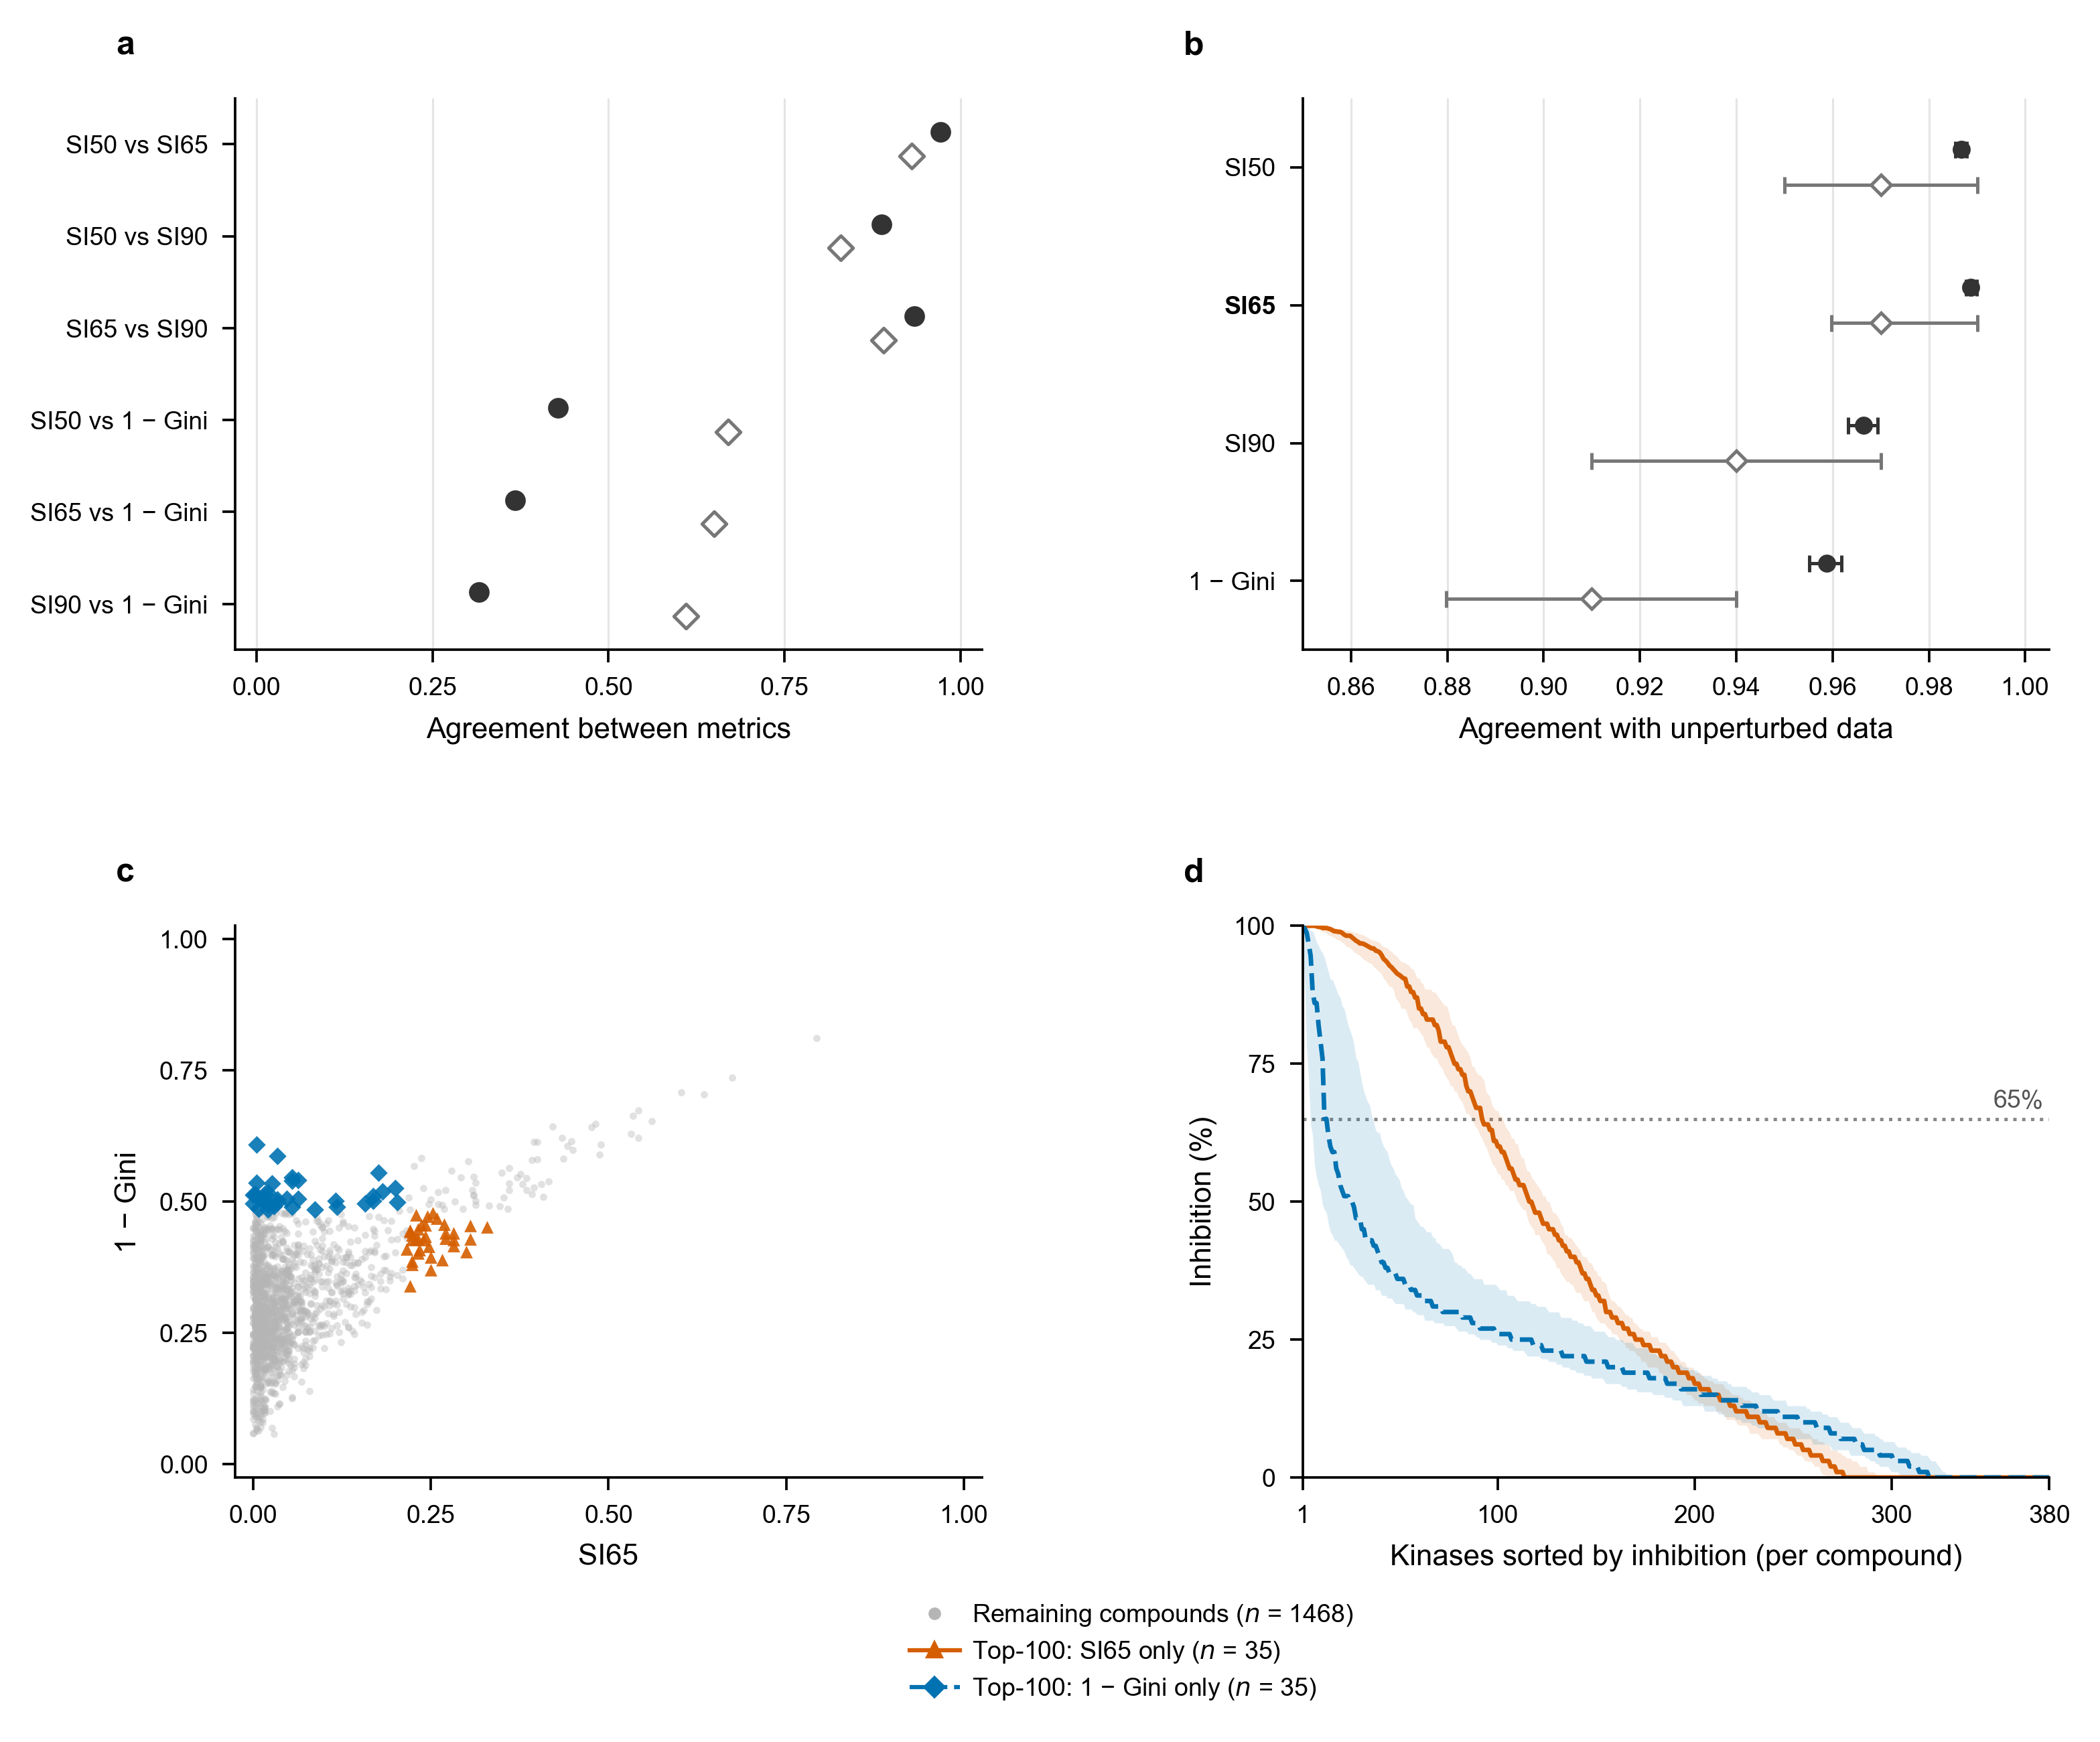

In [18]:
metrics = list(PROMISCUITY_METRICS)
metric_names = {'SI50': 'SI50', 'SI65': 'SI65', 'SI90': 'SI90', 'GINI': '1 \u2212 Gini'}
top_n = min(TOP_N, len(kips_df))
if top_n >= len(kips_df) or top_n < 1:
    raise ValueError('The top-N comparison requires 0 < TOP_N < the compound count.')
if len(activity_array) != len(kips_df):
    raise ValueError('Activity rows must match the current curated cohort.')

tops = {m: top_n_set(kips_df[m], top_n) for m in metrics}
pairs = [(a, b) for a, b in combinations(metrics, 2) if 'GINI' not in (a, b)]
pairs += [(m, 'GINI') for m in metrics if m != 'GINI']
agreement = pd.DataFrame([
    {'Metric_1': a, 'Metric_2': b, 'Pair': f'{metric_names[a]} vs {metric_names[b]}',
     'Spearman_rho': spearmanr(kips_df[a], kips_df[b]).statistic,
     'Top_N': top_n, 'Top_N_overlap': len(tops[a] & tops[b]) / top_n}
    for a, b in pairs
])

noise = noise_df.loc[noise_df['metric'].isin(metrics)].copy()
if noise.duplicated(['replicate', 'metric']).any():
    raise ValueError('Noise results contain duplicate metric/replicate pairs.')
if not noise.groupby('replicate')['metric'].nunique().eq(len(metrics)).all():
    raise ValueError('Every noise replicate must include all candidate metrics.')
replicates = noise['replicate'].nunique()
noise_rows = []
for metric in metrics:
    for field, label in [('rank_spearman', 'Rank correlation'), ('top100_overlap', 'Top-N overlap')]:
        values = noise.loc[noise['metric'].eq(metric), field].to_numpy(float)
        if len(values) != replicates or not np.isfinite(values).all():
            raise ValueError(f'Incomplete noise results for {metric}.')
        low, median, high = np.quantile(values, [.025, .5, .975])
        noise_rows.append({'Metric': metric, 'Statistic': field,
                           'Median': median, 'Simulation_2.5pct': low,
                           'Simulation_97.5pct': high, 'Simulations_N': len(values),
                           'Noise_SD_percentage_points': NOISE_SD})
noise_summary = pd.DataFrame(noise_rows)

si_only = kips_df.index.isin(tops['SI65'] - tops['GINI'])
gini_only = kips_df.index.isin(tops['GINI'] - tops['SI65'])
other = ~(si_only | gini_only)
si_count, gini_count = int(si_only.sum()), int(gini_only.sum())
kinase_ranks = np.arange(1, activity_array.shape[1] + 1)
group_specs = [
    ('SI65 only', si_only, MAIN_COLORS['vermillion'], '^', '-'),
    ('1 \u2212 Gini only', gini_only, MAIN_COLORS['blue'], 'D', '--'),
]
profile_rows = []
for group, mask, color, marker, linestyle in group_specs:
    if not mask.any():
        continue
    profile = np.sort(activity_array[mask], axis=1)[:, ::-1]
    q1, med, q3 = np.percentile(profile, [25, 50, 75], axis=0)
    profile_rows.extend(
        {'Selection': group, 'Compounds_N': int(mask.sum()), 'Kinase_Rank': int(rank),
         'Inhibition_Q1_percent': a, 'Inhibition_Median_percent': b, 'Inhibition_Q3_percent': c}
        for rank, a, b, c in zip(kinase_ranks, q1, med, q3)
    )
profiles = pd.DataFrame(profile_rows)

assignments = kips_df[['Compound ID', 'InChI_Key'] + metrics].copy()
assignments['Selection'] = np.select([si_only, gini_only],
                                     ['SI65 only', '1 \u2212 Gini only'], default='Remaining compounds')
for metric in metrics:
    assignments[f'Top_{top_n}_{metric}'] = kips_df.index.isin(tops[metric])
pd.DataFrame({
    'Metric Pair': agreement['Pair'].str.replace(' vs ', ' vs. ', regex=False).str.replace('1 − Gini', '(1-Gini)', regex=False),
    'Spearman Correlation': agreement['Spearman_rho'].map('{:.3f}'.format),
    'Top 100 Overlap Fraction': agreement['Top_N_overlap'].map('{:.2f}'.format),
}).to_csv(os.path.join(INFORMATION_TABLES_DIR, 'Supplementary_Table_1_Metric_Agreement.csv'), index=False)


def noise_range(metric, statistic, decimals):
    row = noise_summary[noise_summary['Metric'].eq(metric) & noise_summary['Statistic'].eq(statistic)].iloc[0]
    return f"{row['Median']:.{decimals}f} ({row['Simulation_2.5pct']:.{decimals}f}-{row['Simulation_97.5pct']:.{decimals}f})"


pd.DataFrame({
    'Metric': ['1 - Gini' if metric == 'GINI' else metric for metric in metrics],
    'Spearman Correlation': [noise_range(metric, 'rank_spearman', 3) for metric in metrics],
    'Top 100 Overlap Fraction': [noise_range(metric, 'top100_overlap', 2) for metric in metrics],
}).to_csv(os.path.join(INFORMATION_TABLES_DIR, 'Supplementary_Table_2_Metric_Stability.csv'), index=False)
profiles.to_csv(os.path.join(SUPPORTING_DIR, 'Metric_Rationale_Profiles.csv'), index=False)
assignments.to_csv(os.path.join(SUPPORTING_DIR, 'Metric_Rationale_Selections.csv'), index=False)

fig, axes = plt.subplots(2, 2, figsize=(7.08, 5.65))
fig.subplots_adjust(left=.13, right=.98, top=.96, bottom=.15, hspace=.50, wspace=.43)
ax_a, ax_b, ax_c, ax_d = axes.ravel()
encodings = [
    ('Spearman_rho', 'rank_spearman', -.13, 'o', '#333333', '#333333'),
    ('Top_N_overlap', 'top100_overlap', .13, 'D', 'white', '#777777'),
]
for field, noise_field, offset, marker, face, edge in encodings:
    ax_a.scatter(agreement[field], np.arange(len(agreement)) + offset,
                 marker=marker, s=17, facecolors=face, edgecolors=edge, linewidths=.8, zorder=3)
    part = noise_summary[noise_summary['Statistic'].eq(noise_field)].set_index('Metric').reindex(metrics)
    ax_b.errorbar(part['Median'], np.arange(len(metrics)) + offset,
                  xerr=[part['Median'] - part['Simulation_2.5pct'],
                        part['Simulation_97.5pct'] - part['Median']],
                  fmt=marker, markersize=3.5, markerfacecolor=face, markeredgecolor=edge,
                  markeredgewidth=.8, ecolor=edge, elinewidth=.8, capsize=2, zorder=3)
ax_a.set_yticks(range(len(agreement)), agreement['Pair'], fontsize=6)
ax_a.set_ylim(len(agreement) - .5, -.5)
ax_a.set_xlim(-.03, 1.03)
ax_a.set_xticks([0, .25, .5, .75, 1])
ax_a.set_xlabel('Agreement between metrics')
ax_b.set_yticks(range(len(metrics)), [metric_names[m] for m in metrics], fontsize=7)
ax_b.set_ylim(len(metrics) - .5, -.5)
noise_min = float(noise_summary['Simulation_2.5pct'].min())
ax_b.set_xlim(max(0, np.floor((noise_min - .02) * 20) / 20), 1.005)
ax_b.set_xlabel('Agreement with unperturbed data')
for tick, metric in zip(ax_b.get_yticklabels(), metrics):
    if metric == 'SI65':
        tick.set_fontweight('bold')
for ax in (ax_a, ax_b):
    ax.grid(axis='x', color='#e5e5e5', linewidth=.5, zorder=0)

ax_c.scatter(kips_df.loc[other, 'SI65'], kips_df.loc[other, 'GINI'],
             s=3, color='#b5b5b5', alpha=.4, linewidths=0, rasterized=True)
for group, mask, color, marker, linestyle in group_specs:
    ax_c.scatter(kips_df.loc[mask, 'SI65'], kips_df.loc[mask, 'GINI'],
                 s=9, color=color, marker=marker, alpha=.9, linewidths=0, rasterized=True)
    if not mask.any():
        continue
    profile = profiles[profiles['Selection'].eq(group)]
    ax_d.plot(profile['Kinase_Rank'], profile['Inhibition_Median_percent'],
              color=color, linestyle=linestyle, linewidth=1.1)
    ax_d.fill_between(profile['Kinase_Rank'].to_numpy(), profile['Inhibition_Q1_percent'].to_numpy(),
                      profile['Inhibition_Q3_percent'].to_numpy(), color=color, alpha=.14, linewidth=0)
ax_c.set_xlabel('SI65')
ax_c.set_ylabel('1 \u2212 Gini')
ax_c.set_xlim(-.025, 1.025)
ax_c.set_ylim(-.025, 1.025)
ax_c.set_xticks([0, .25, .5, .75, 1])
ax_c.set_yticks([0, .25, .5, .75, 1])
ax_d.set_xlabel('Kinases sorted by inhibition (per compound)')
ax_d.set_ylabel('Inhibition (%)')
ax_d.set_xlim(1, activity_array.shape[1])
ax_d.set_ylim(0, 100)
ax_d.set_xticks([1, 100, 200, 300, activity_array.shape[1]])
ax_d.set_yticks([0, 25, 50, 75, 100])
ax_d.axhline(65, color='#888888', linestyle=':', linewidth=.8, zorder=0)
ax_d.text(activity_array.shape[1] - 3, 67, '65%', ha='right', fontsize=6, color='#555555')
if profiles.empty:
    ax_d.text(.5, .5, 'Top-N selections are identical', transform=ax_d.transAxes, ha='center')

for ax, letter in zip(axes.ravel(), 'abcd'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(.6)
    ax.tick_params(length=3, width=.6, labelsize=6)
    ax.text(-.16, 1.08, letter, transform=ax.transAxes, fontweight='bold', fontsize=8)
fig.legend(handles=[
    Line2D([], [], marker='o', color='none', markerfacecolor='#b5b5b5', markeredgecolor='none',
           markersize=3, label=f'Remaining compounds ($n$ = {int(other.sum())})'),
    Line2D([], [], marker='^', color=MAIN_COLORS['vermillion'], linewidth=1, markersize=3,
           label=f'Top-{top_n}: SI65 only ($n$ = {si_count})'),
    Line2D([], [], marker='D', color=MAIN_COLORS['blue'], linestyle='--', linewidth=1, markersize=3,
           label=f'Top-{top_n}: 1 \u2212 Gini only ($n$ = {gini_count})'),
], loc='lower center', bbox_to_anchor=(.55, .005), ncol=1, frameon=False, fontsize=6, handletextpad=.5, labelspacing=.45)
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_2_Metric_Rationale.png'), bbox_inches='tight')
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_2_Metric_Rationale.pdf'), bbox_inches='tight')
plt.show()

# Binarize data with `SI65`

In [19]:
activity_matrix_binarized = (activity_matrix >= 65).astype(int)
kips_df['SI65'] = activity_matrix_binarized.sum(axis=1) / len(kinase_cols)
kips_df['SI65'].describe()

count    1538.000000
mean        0.060326
std         0.089628
min         0.000000
25%         0.010526
50%         0.028947
75%         0.068421
max         0.792105
Name: SI65, dtype: float64

# Intra-KIPS pairwise similarity

In [20]:
kips_fps = [
    AllChem.GetMorganFingerprintAsBitVect(mol, radius=FP_RADIUS, nBits=FP_NBITS, useChirality=True)
    for mol in tqdm(kips_df['mol_std'], desc="ECFP4 fingerprints")
]

ECFP4 fingerprints: 100%|██████████| 1538/1538 [00:00<00:00, 9638.10it/s]


Pairwise Tanimoto: 100%|██████████| 1538/1538 [00:03<00:00, 408.45it/s]


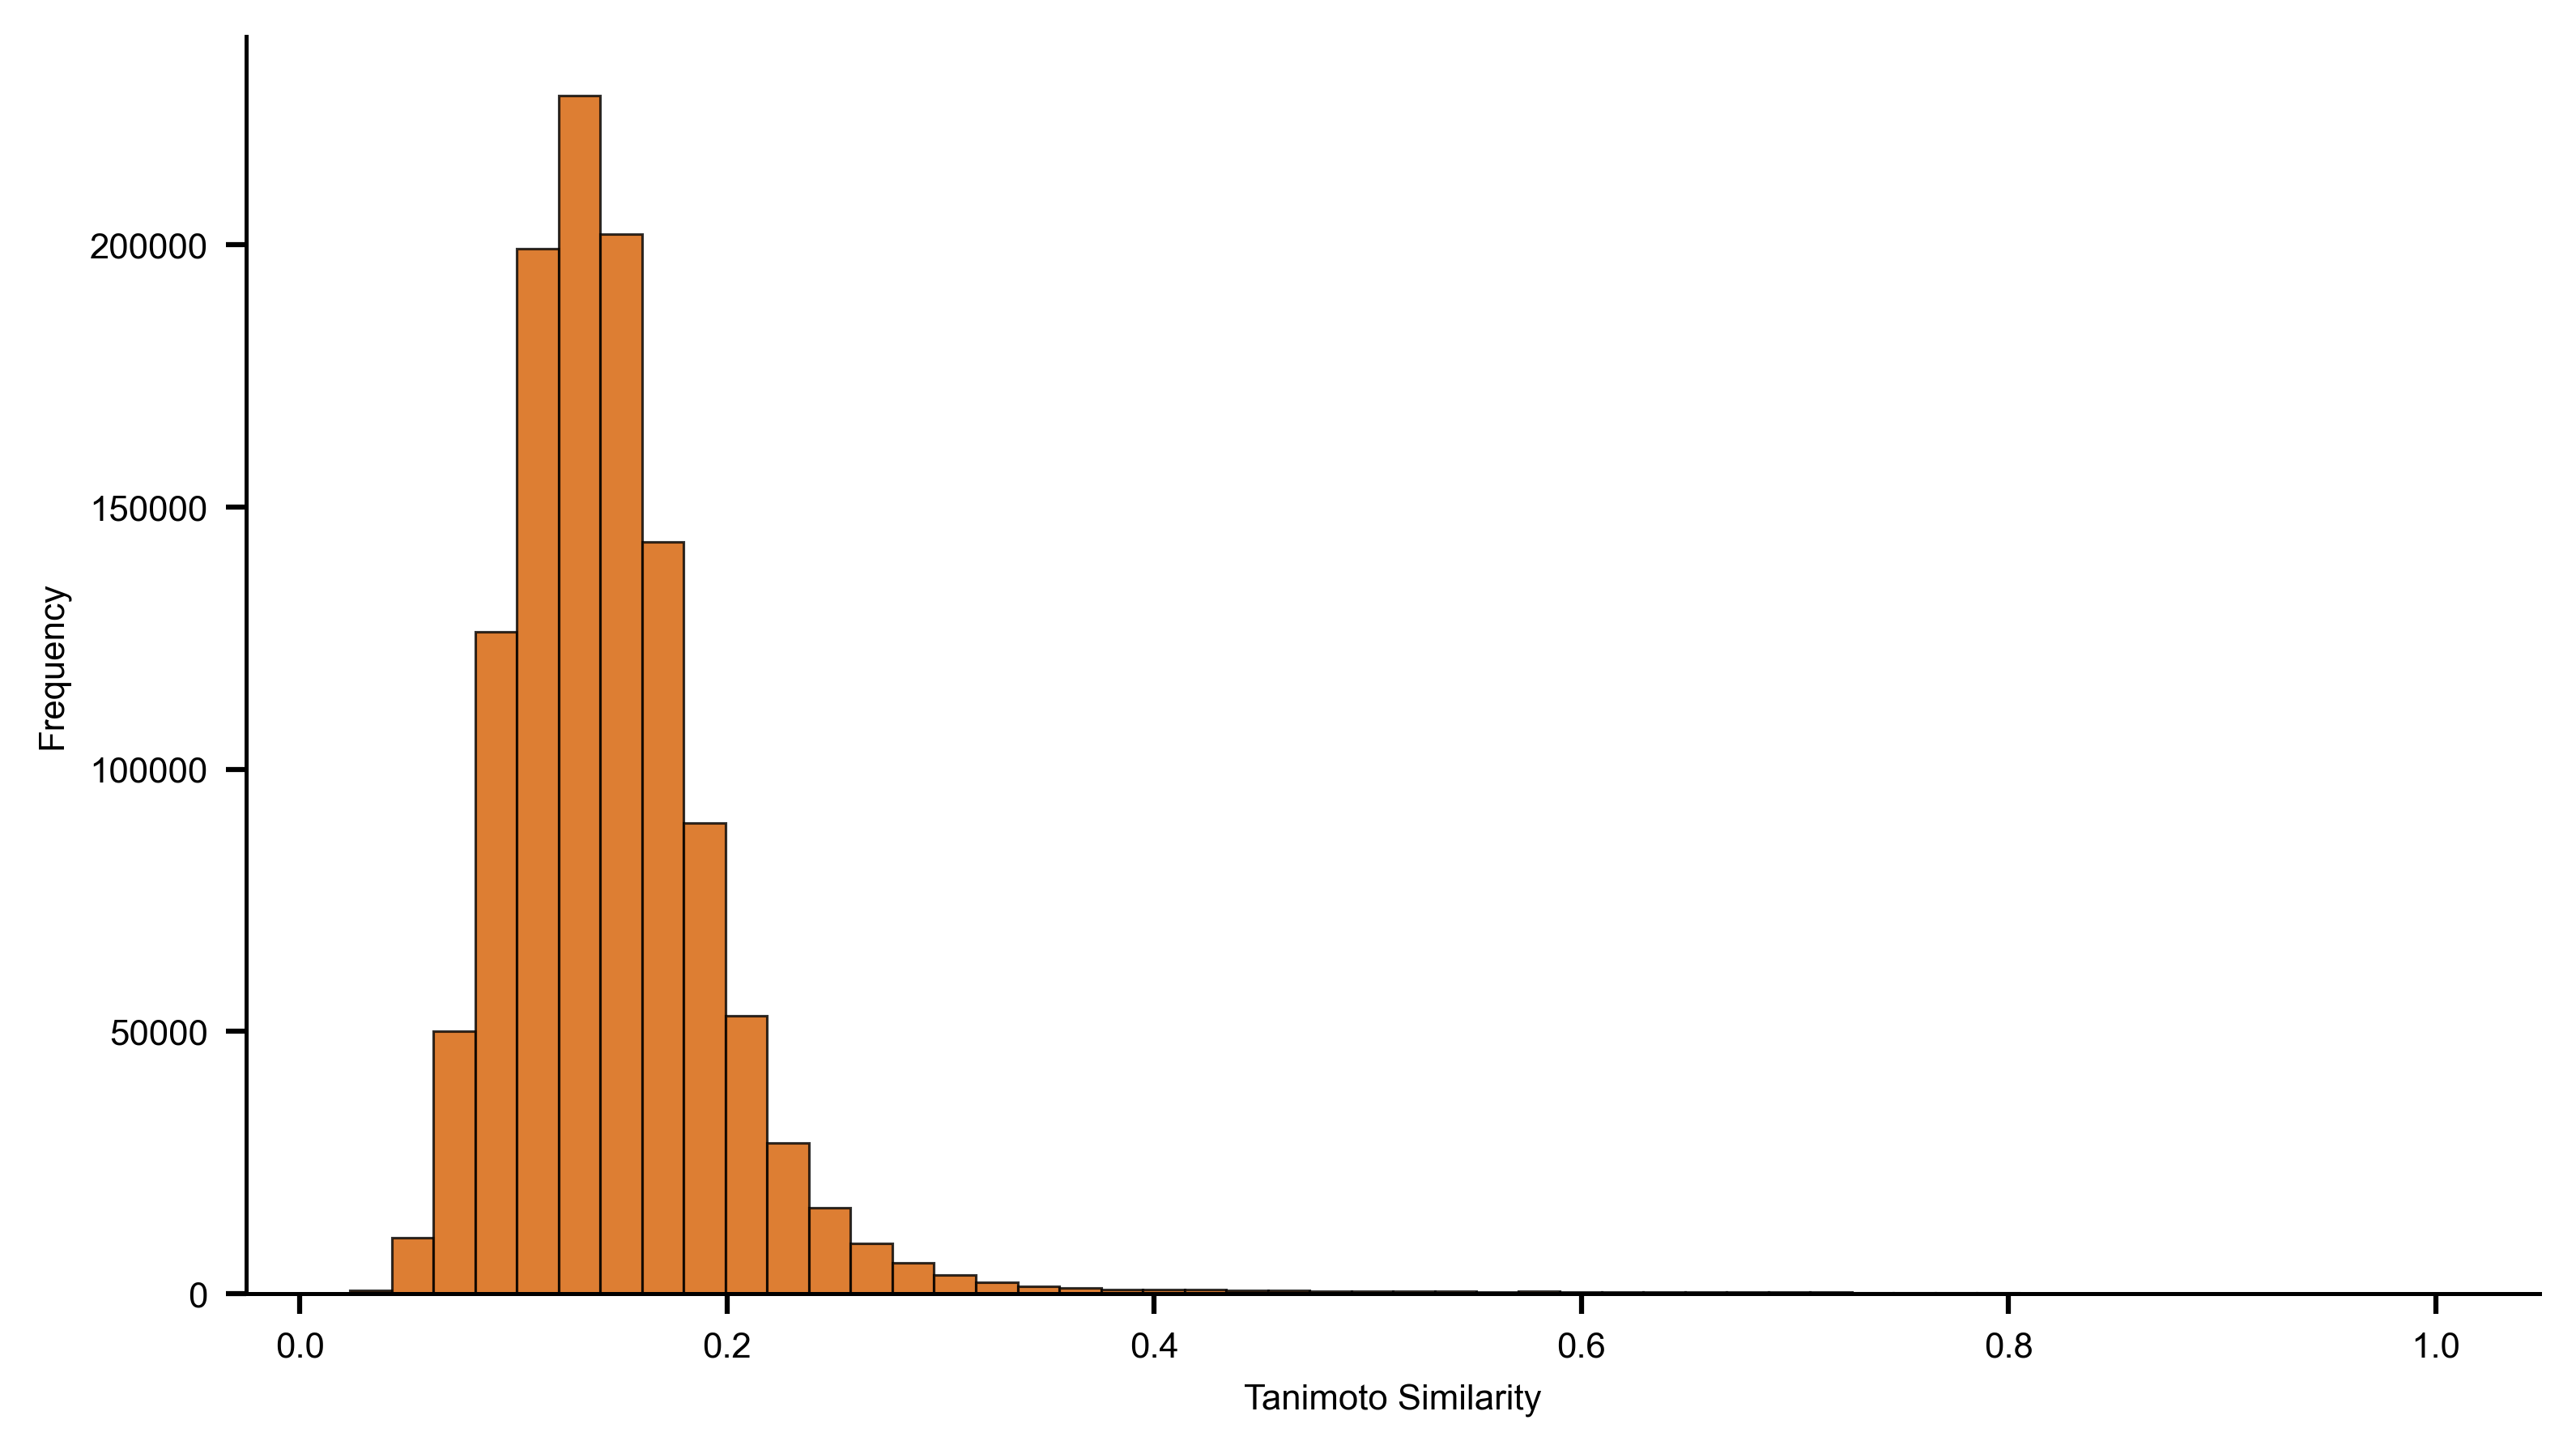

Median intra-KIPS Tanimoto = 0.138


In [21]:
n    = len(kips_fps)
sims = np.array([
    DataStructs.TanimotoSimilarity(kips_fps[i], kips_fps[j])
    for i in tqdm(range(n), desc="Pairwise Tanimoto")
    for j in range(i + 1, n)
])
fig_si_hist, ax_si_hist = plt.subplots(figsize=(7.08, 4))
ax_si_hist.hist(sims, bins=50, color=MAIN_COLORS['vermillion'], alpha=0.8, edgecolor='black', linewidth=0.5)
ax_si_hist.set_xlabel('Tanimoto Similarity')
ax_si_hist.set_ylabel('Frequency')
ax_si_hist.spines['top'].set_visible(False); ax_si_hist.spines['right'].set_visible(False)
ax_si_hist.tick_params(axis='both', which='major', length=4, width=1)
plt.tight_layout()
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, "Supplementary_Figure_1_Pairwise_Tanimoto.png"))
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, "Supplementary_Figure_1_Pairwise_Tanimoto.pdf"))
plt.show()

print(f"Median intra-KIPS Tanimoto = {np.median(sims):.3f}")

# External Library Standardization

In [22]:
def standardize_library(smiles_series, desc="Library"):
    uncharger = rdMolStandardize.Uncharger()
    seen, out = set(), {}

    mols = [Chem.MolFromSmiles(s)
            for s in tqdm(smiles_series.dropna(), desc=f"{desc} — parse", leave=False)]
    mols = [m for m in mols if m is not None]

    for mol in tqdm(mols, desc=f"{desc} — standardize", leave=False):
        try:
            mol = rdMolStandardize.ChargeParent(mol)
            mol = uncharger.uncharge(mol)
            key = Chem.MolToInchiKey(mol)
            if key and key not in seen:
                seen.add(key)
                out[key] = Chem.MolToSmiles(mol, canonical=True)
        except Exception:
            pass
    return set(out.values())

pkis_df      = pd.read_csv(PKIS_FILE,      encoding='latin-1')
pkis2_df     = pd.read_csv(PKIS2_FILE,     encoding='latin-1')
kcgs2_df     = pd.read_csv(KCGS2_FILE,     encoding='latin-1')
kinobeads_df = pd.read_csv(KINOBEADS_FILE, encoding='latin-1')

pkis_smiles      = standardize_library(pkis_df['SMILES'],      desc="PKIS")
pkis2_smiles     = standardize_library(pkis2_df['SMILES'],     desc="PKIS2")
kcgs2_smiles     = standardize_library(kcgs2_df['SMILES'],     desc="KCGS2")
kinobeads_smiles = standardize_library(kinobeads_df['SMILES'], desc="KinoBeads")

upset_contents_filtered = {
    'KIPS':      set(kips_df['SMILES_standardized']),
    'PKIS':      pkis_smiles,
    'PKIS2':     pkis2_smiles,
    'KCGS2':     kcgs2_smiles,
    'Kinobeads': kinobeads_smiles,
}
# Reference libraries retain their full membership in both comparisons.
upset_contents_unfiltered = {
    **upset_contents_filtered,
    'KIPS': set(kips_unfiltered_df['SMILES_standardized']),
}
assert len(upset_contents_filtered['KIPS']) == len(kips_df)
assert len(upset_contents_unfiltered['KIPS']) == len(kips_unfiltered_df)
assert upset_contents_filtered['KIPS'] <= upset_contents_unfiltered['KIPS']


# Figure 1a — filtered KIPS UpSet

Compare KIPS after covalent/allosteric exclusions with the complete reference
libraries. The SI plot uses KIPS before these exclusions, with the same structure
standardization and deduplication. Both use the same grayscale style, intersection
ordering, count labels, and fixed 3.45 × 2.6 inch canvas (450 dpi).


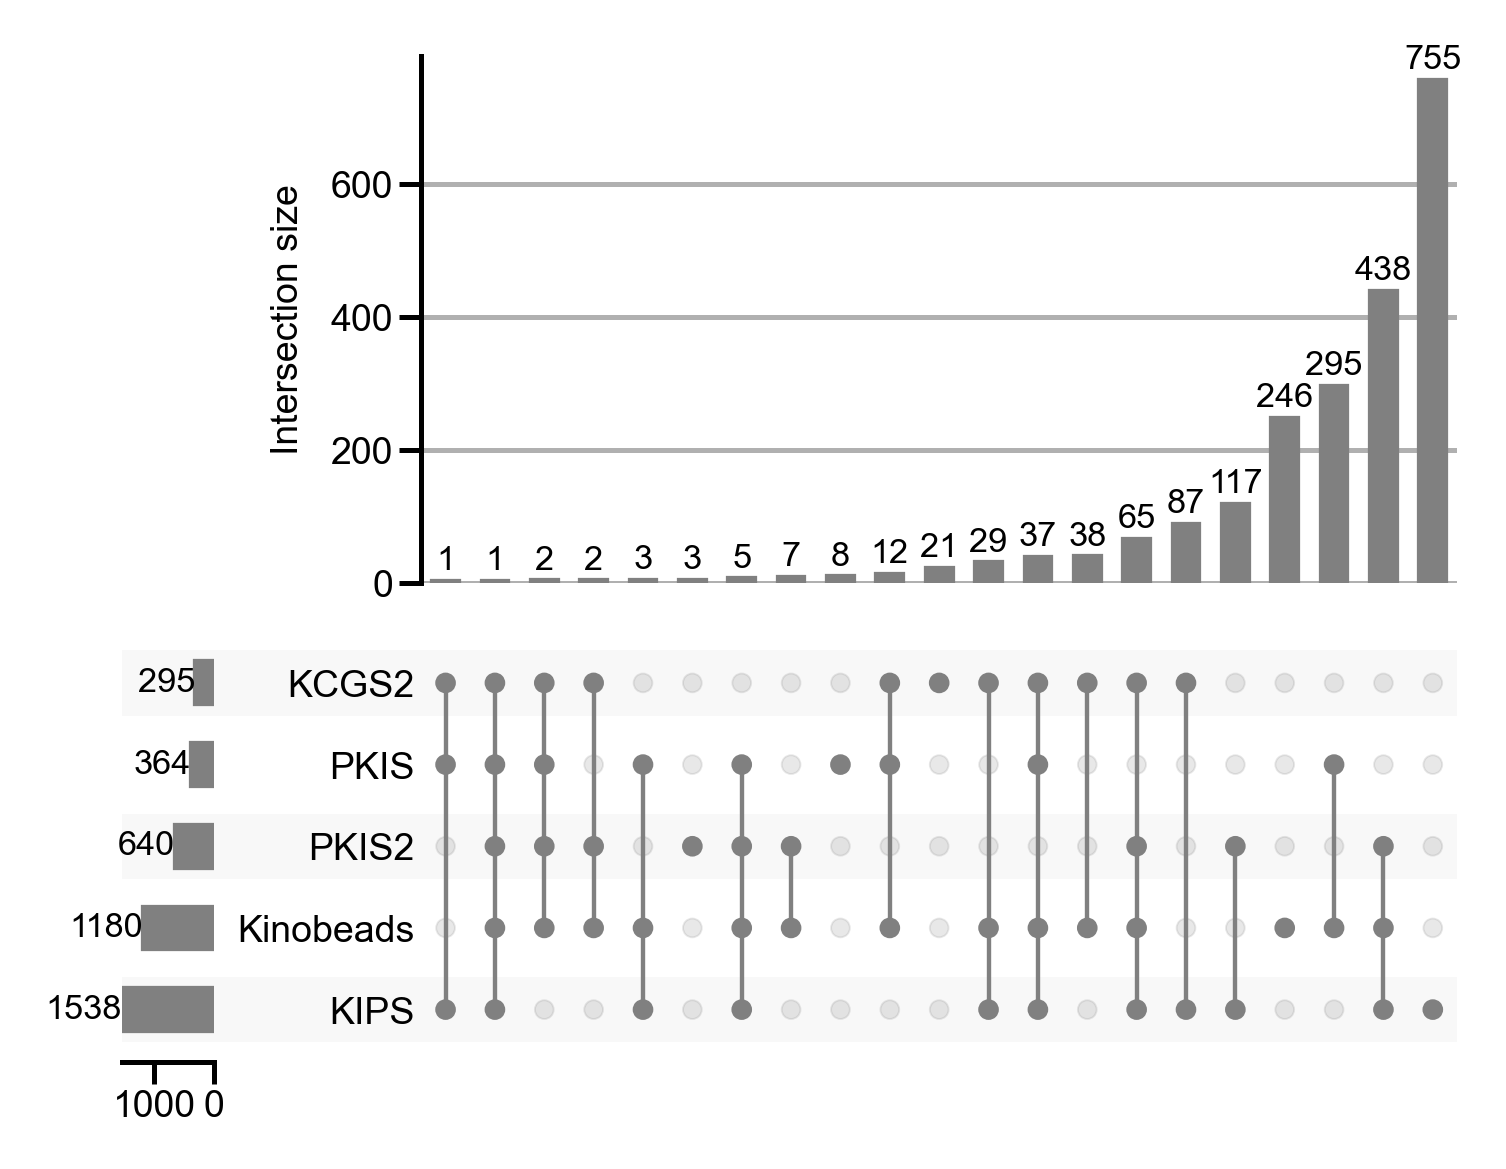

In [23]:
def plot_library_upset(contents, output_dir, stem):
    # element_size=None prevents UpSet from silently enlarging the canvas.
    with warnings.catch_warnings(), plt.rc_context({'font.size': 6, 'xtick.labelsize': 6}):
        warnings.simplefilter('ignore', FutureWarning)
        fig_upset = plt.figure(figsize=(3.45, 2.6))
        upset = UpSet(from_contents(contents), subset_size='count',
                      sort_by='-cardinality', show_counts=True, facecolor='#808080',
                      element_size=None)
        upset_axes = upset.plot(fig=fig_upset)
        # With element_size=None, UpSet defaults to 200 pt^2 dots.
        # Scale these explicitly for the single-column canvas.
        from matplotlib.collections import PathCollection, LineCollection
        for artist in upset_axes['matrix'].collections:
            if isinstance(artist, PathCollection):
                artist.set_sizes([9])
                artist.set_linewidths(.3)
            elif isinstance(artist, LineCollection):
                artist.set_linewidths(.7)
        fig_upset.subplots_adjust(left=.12, right=.98, bottom=.08, top=.94)
        for ax in fig_upset.axes:
            ax.xaxis.grid(False)
            ax.tick_params(labelsize=6, pad=1)
            ax.xaxis.label.set_fontsize(6)
            ax.yaxis.label.set_fontsize(6)
            for txt in ax.texts:
                txt.set_fontsize(5.5)
        # Override the global tight bounding box to preserve physical dimensions.
        with plt.rc_context({'savefig.bbox': None}):
            for ext in ('pdf', 'png'):
                fig_upset.savefig(os.path.join(output_dir, f'{stem}.{ext}'), dpi=450)
        upset.intersections.rename('Compounds_N').to_csv(
            os.path.join(SUPPORTING_DIR, f'{stem}_Intersections.csv'))
        upset.totals.rename('Compounds_N').to_csv(
            os.path.join(SUPPORTING_DIR, f'{stem}_Set_Sizes.csv'))
    return fig_upset

fig_a = plot_library_upset(upset_contents_filtered, PANELS_DIR, 'Figure_1_Panel_A')
plt.show()


# Full KIPS UpSet

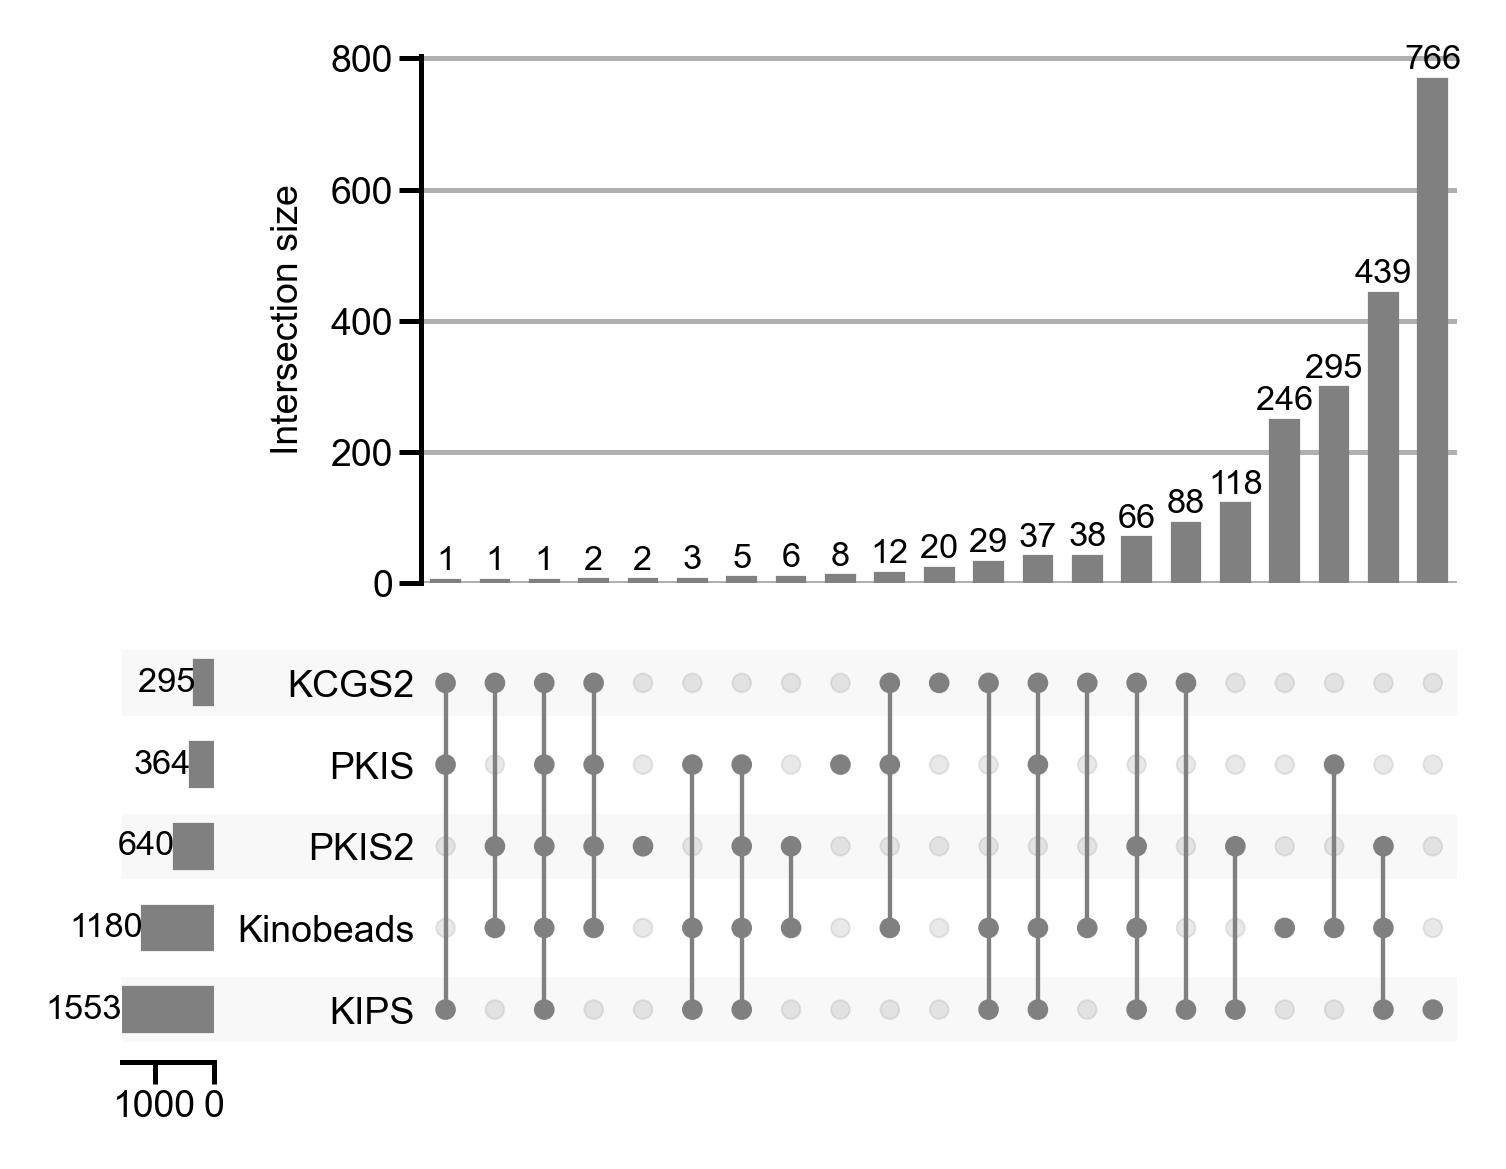

In [24]:
fig_si_upset = plot_library_upset(
    upset_contents_unfiltered, SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_2_UpSet_Full_Dataset')
plt.show()

# SI65 elbow plot

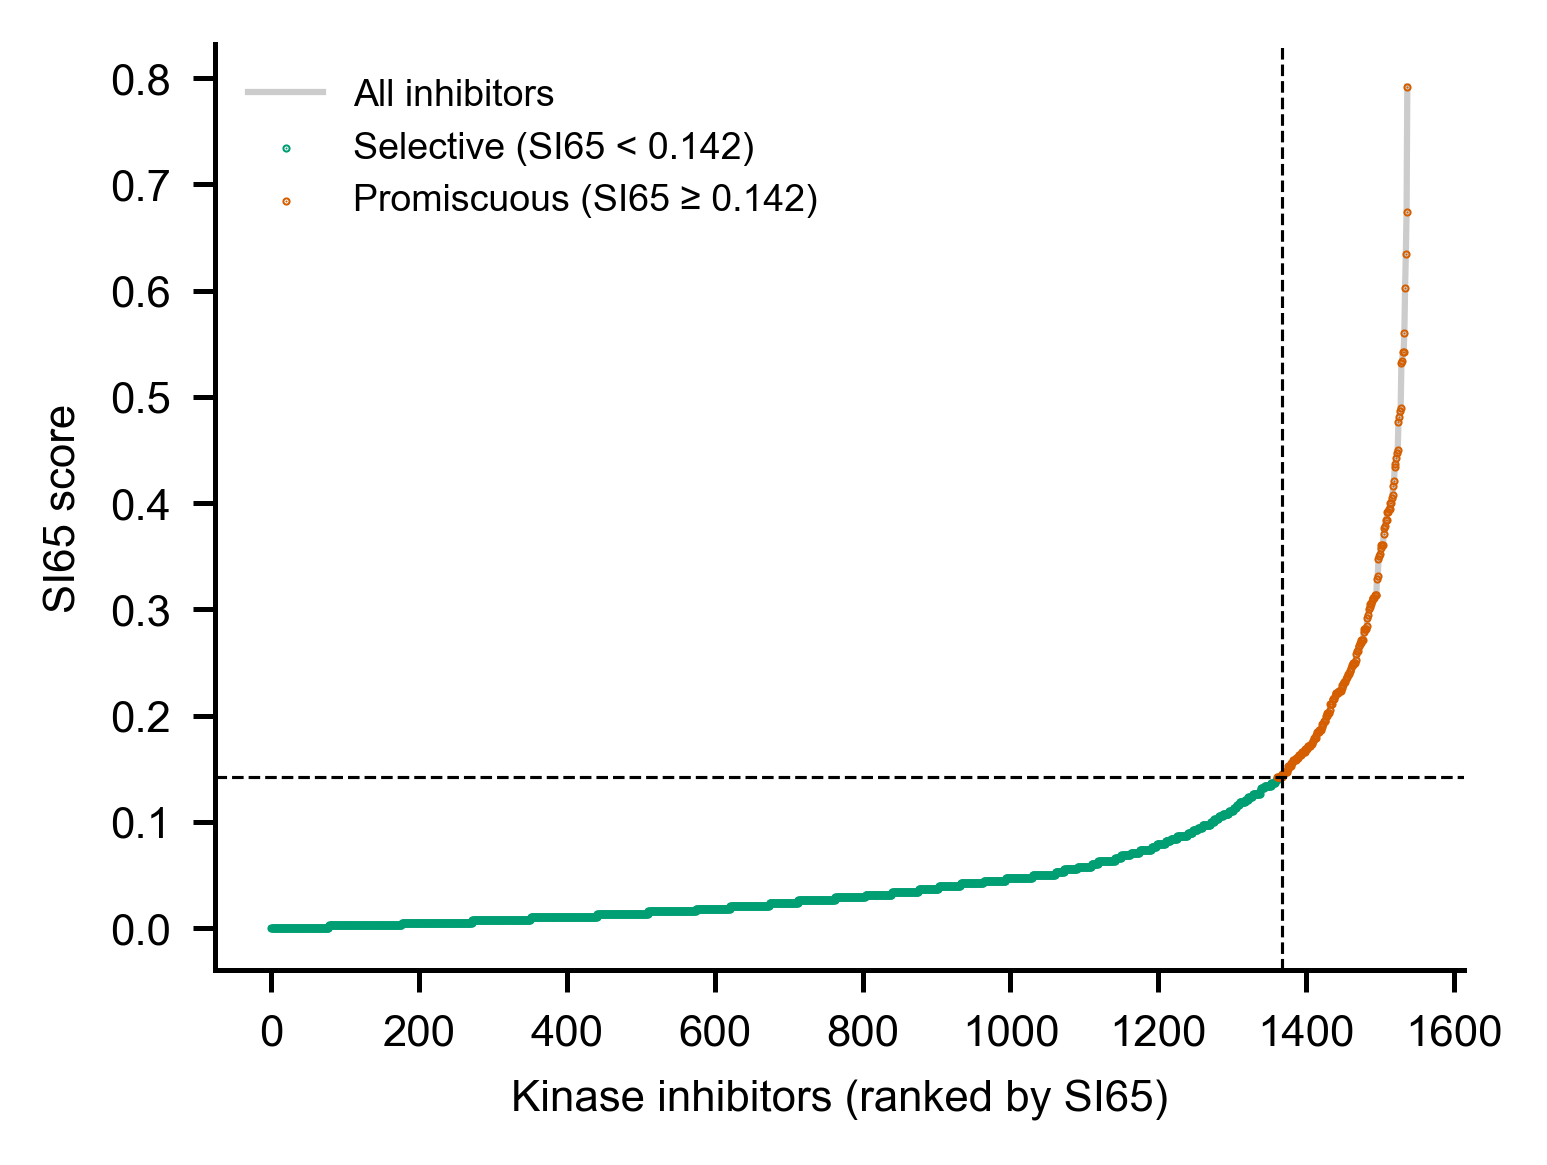

In [25]:
si65_sorted = kips_df['SI65'].sort_values().reset_index(drop=True)
si65_ranks  = np.arange(len(si65_sorted))
knee        = KneeLocator(si65_ranks, si65_sorted.values, curve='convex', direction='increasing', S=SI65_KNEE_SENSITIVITY)

elbow_index          = knee.knee
elbow_si65_threshold = knee.knee_y
if elbow_si65_threshold is None:
    raise ValueError('Kneedle found no SI65 knee; inspect the activity data before classification.')
selective_mask       = si65_sorted < elbow_si65_threshold

fig, ax = plt.subplots(figsize=(3.45, 2.6))
ax.plot(si65_ranks, si65_sorted, color='#cccccc', linewidth=1, label='All inhibitors', zorder=1)
ax.scatter(si65_ranks[selective_mask], si65_sorted[selective_mask],
           color=MAIN_COLORS['bluishgreen'], s=0.1,
           label=f'Selective (SI65 < {elbow_si65_threshold:.3f})', zorder=2)
ax.scatter(si65_ranks[~selective_mask], si65_sorted[~selective_mask],
           color=MAIN_COLORS['vermillion'], s=0.1,
           label=f'Promiscuous (SI65 ≥ {elbow_si65_threshold:.3f})', zorder=2)
ax.axhline(elbow_si65_threshold, color='black', linestyle='--', linewidth=0.5, zorder=3)
ax.axvline(elbow_index,          color='black', linestyle='--', linewidth=0.5, zorder=3)
ax.set_xlabel('Kinase inhibitors (ranked by SI65)', fontsize=7)
ax.set_ylabel('SI65 score', fontsize=7)
ax.tick_params(axis='both', labelsize=7)
ax.legend(loc='upper left', frameon=False, fontsize=6)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(PANELS_DIR, 'Figure_1_Panel_B.pdf'))
plt.savefig(os.path.join(PANELS_DIR, 'Figure_1_Panel_B.png'))

# Figure 1 composite

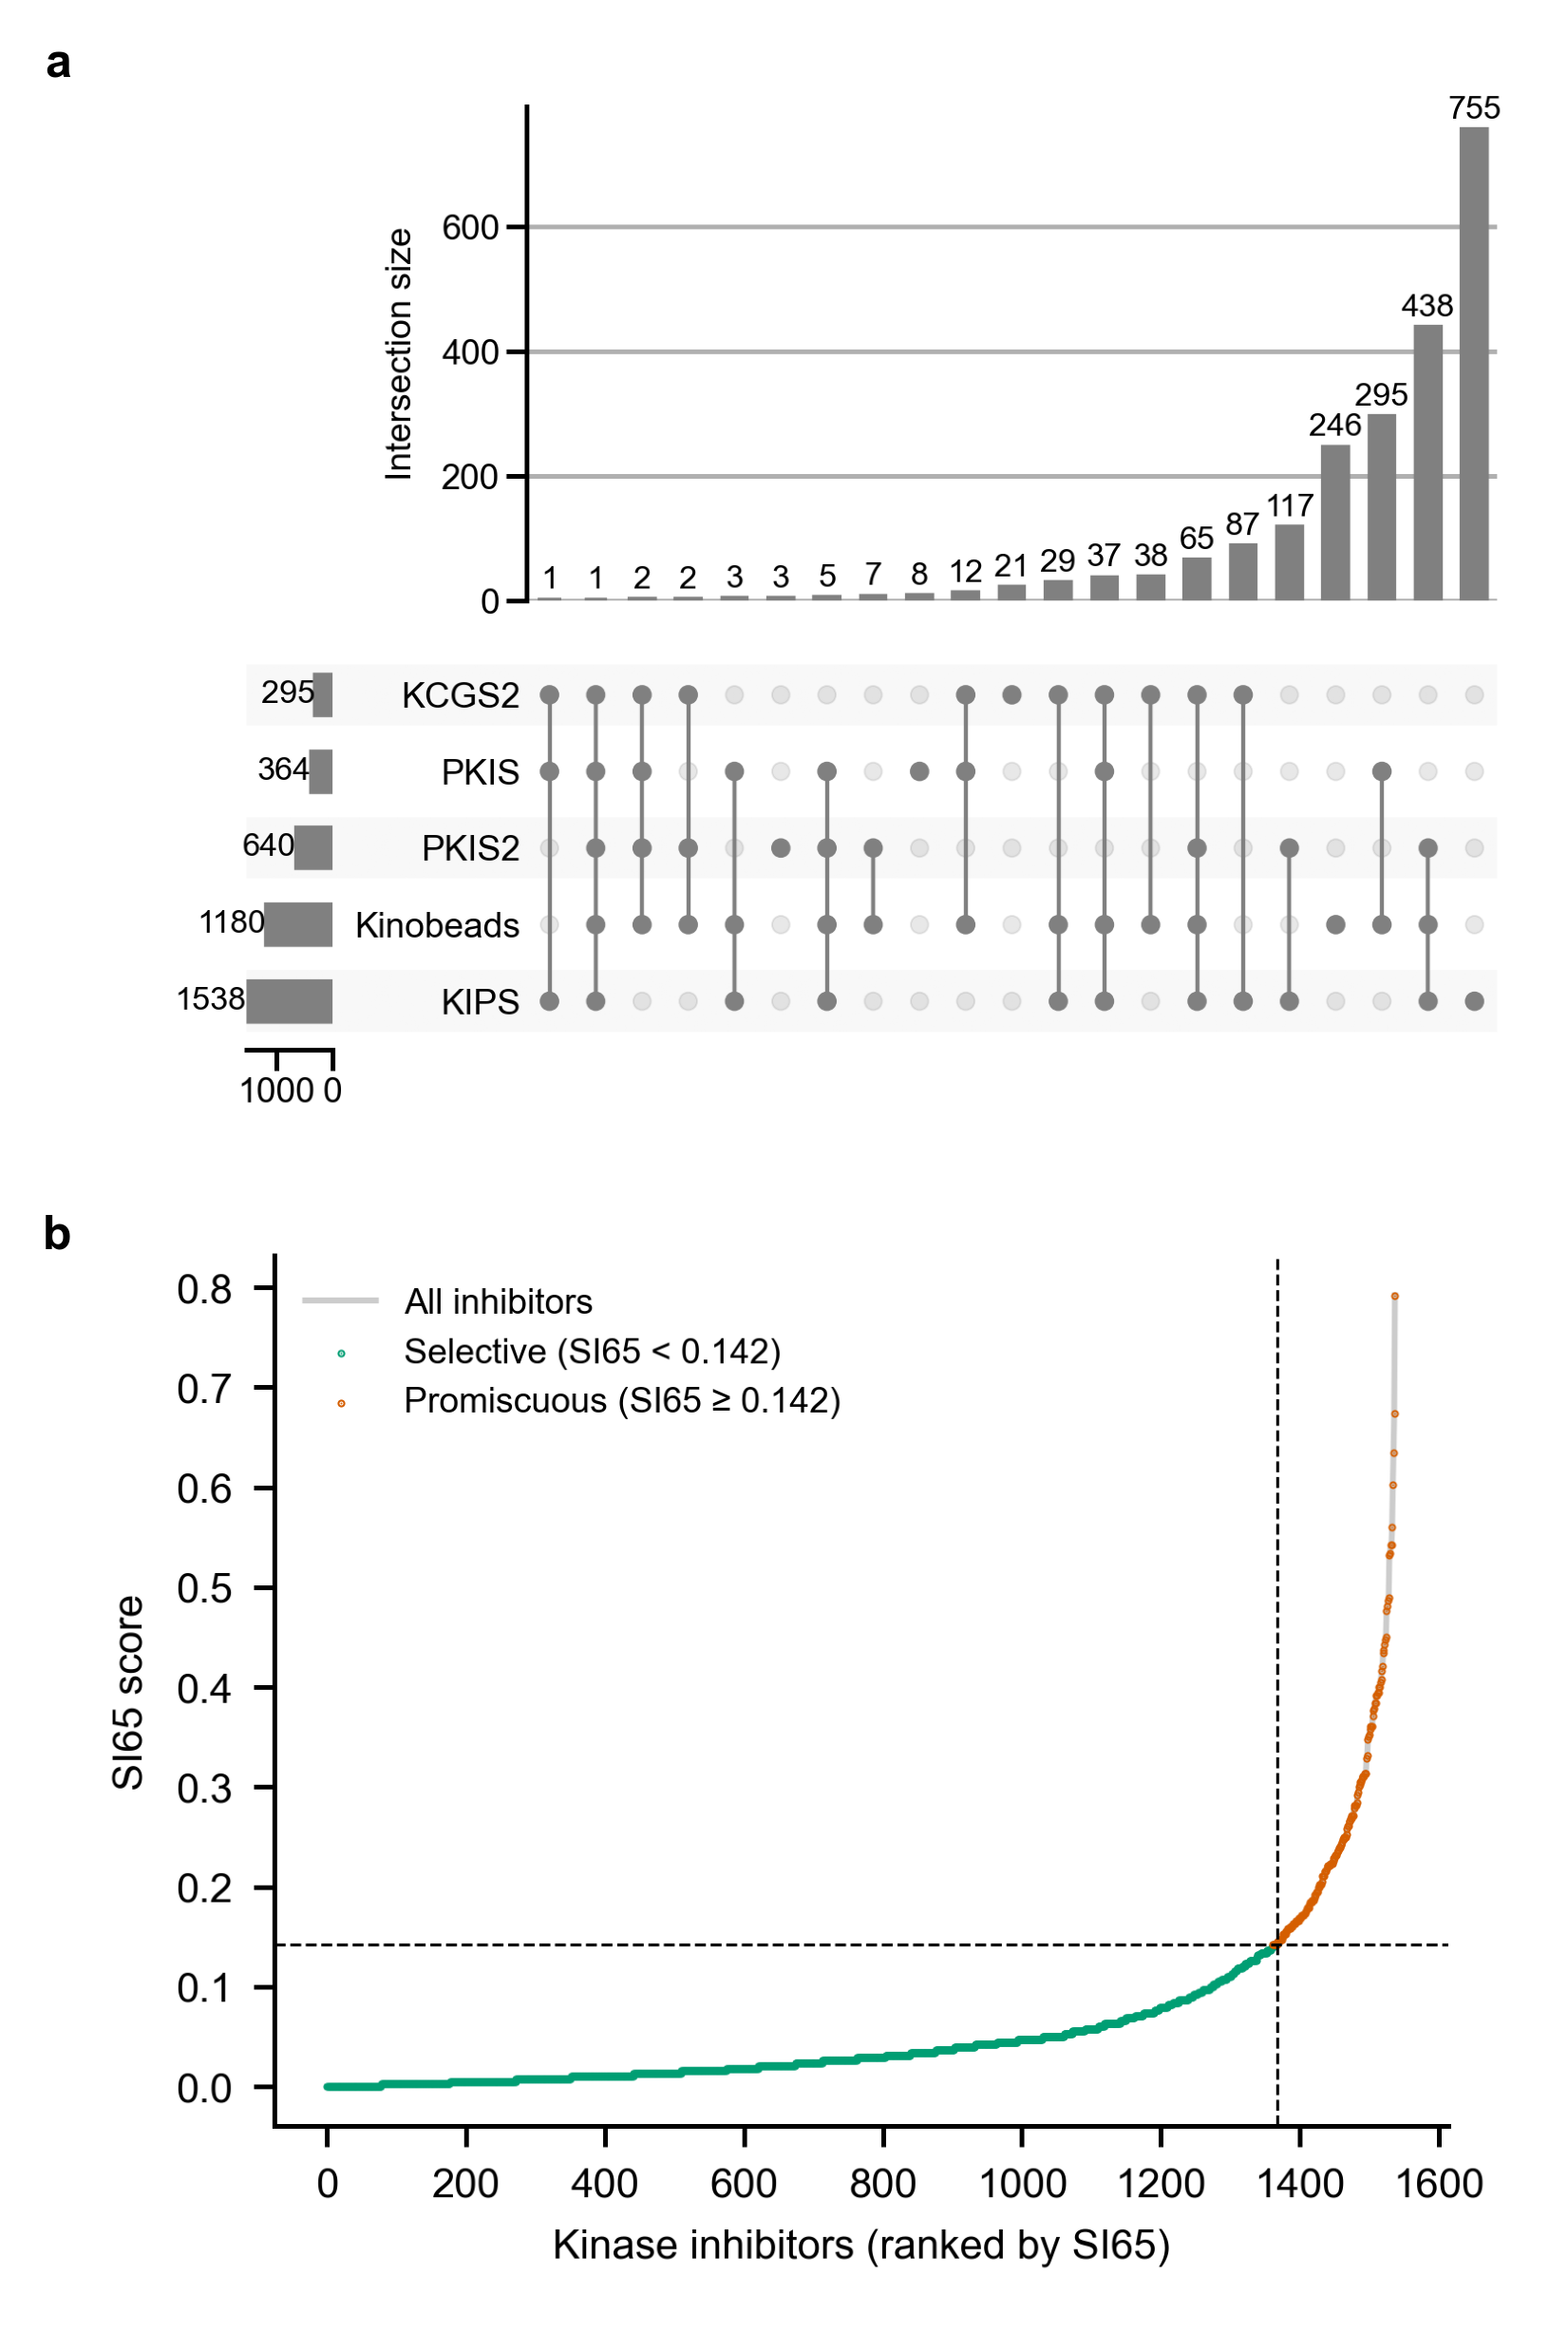

In [26]:
img_a = mpimg.imread(os.path.join(PANELS_DIR, 'Figure_1_Panel_A.png'))
img_b = mpimg.imread(os.path.join(PANELS_DIR, 'Figure_1_Panel_B.png'))

fig, axes = plt.subplots(2, 1, figsize=(3.45, 5.5))
fig.patch.set_facecolor('white')
for ax, img in zip(axes, [img_a, img_b]):
    ax.imshow(img); ax.axis('off')
for label, ax in zip('ab', axes):
    ax.text(0, 1, label, transform=ax.transAxes, fontsize=8, fontweight='bold', va='top', ha='right')
plt.tight_layout(pad=0.2, h_pad=0.2)
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_1_Dataset_Composition.pdf'))
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_1_Dataset_Composition.png'))
plt.show()

# Define promiscuity based on elbow

In [27]:
kips_df['is_promiscuous'] = kips_df['SI65'] >= elbow_si65_threshold
n_prom = kips_df['is_promiscuous'].sum()
print(f"Threshold SI65 ≥ {elbow_si65_threshold:.3f} \n{n_prom} promiscuous, {len(kips_df) - n_prom} selective")

Threshold SI65 ≥ 0.142 
177 promiscuous, 1361 selective


# Save curated data with SI65

In [28]:
curated = kips_df[['Compound ID', 'SMILES_standardized', 'InChI_Key', 'SI65', 'is_promiscuous']].copy()
curated.to_csv(os.path.join(KIPS_DIR, 'KIPS_Curated_SI65.csv'), index=False)
print(f"Saved {len(curated)} compounds")

Saved 1538 compounds


# Chemical descriptor analysis
Do promiscuous and selective inhibitors differ in their physicochemical profiles?


100%|██████████| 1538/1538 [00:01<00:00, 987.17it/s] 


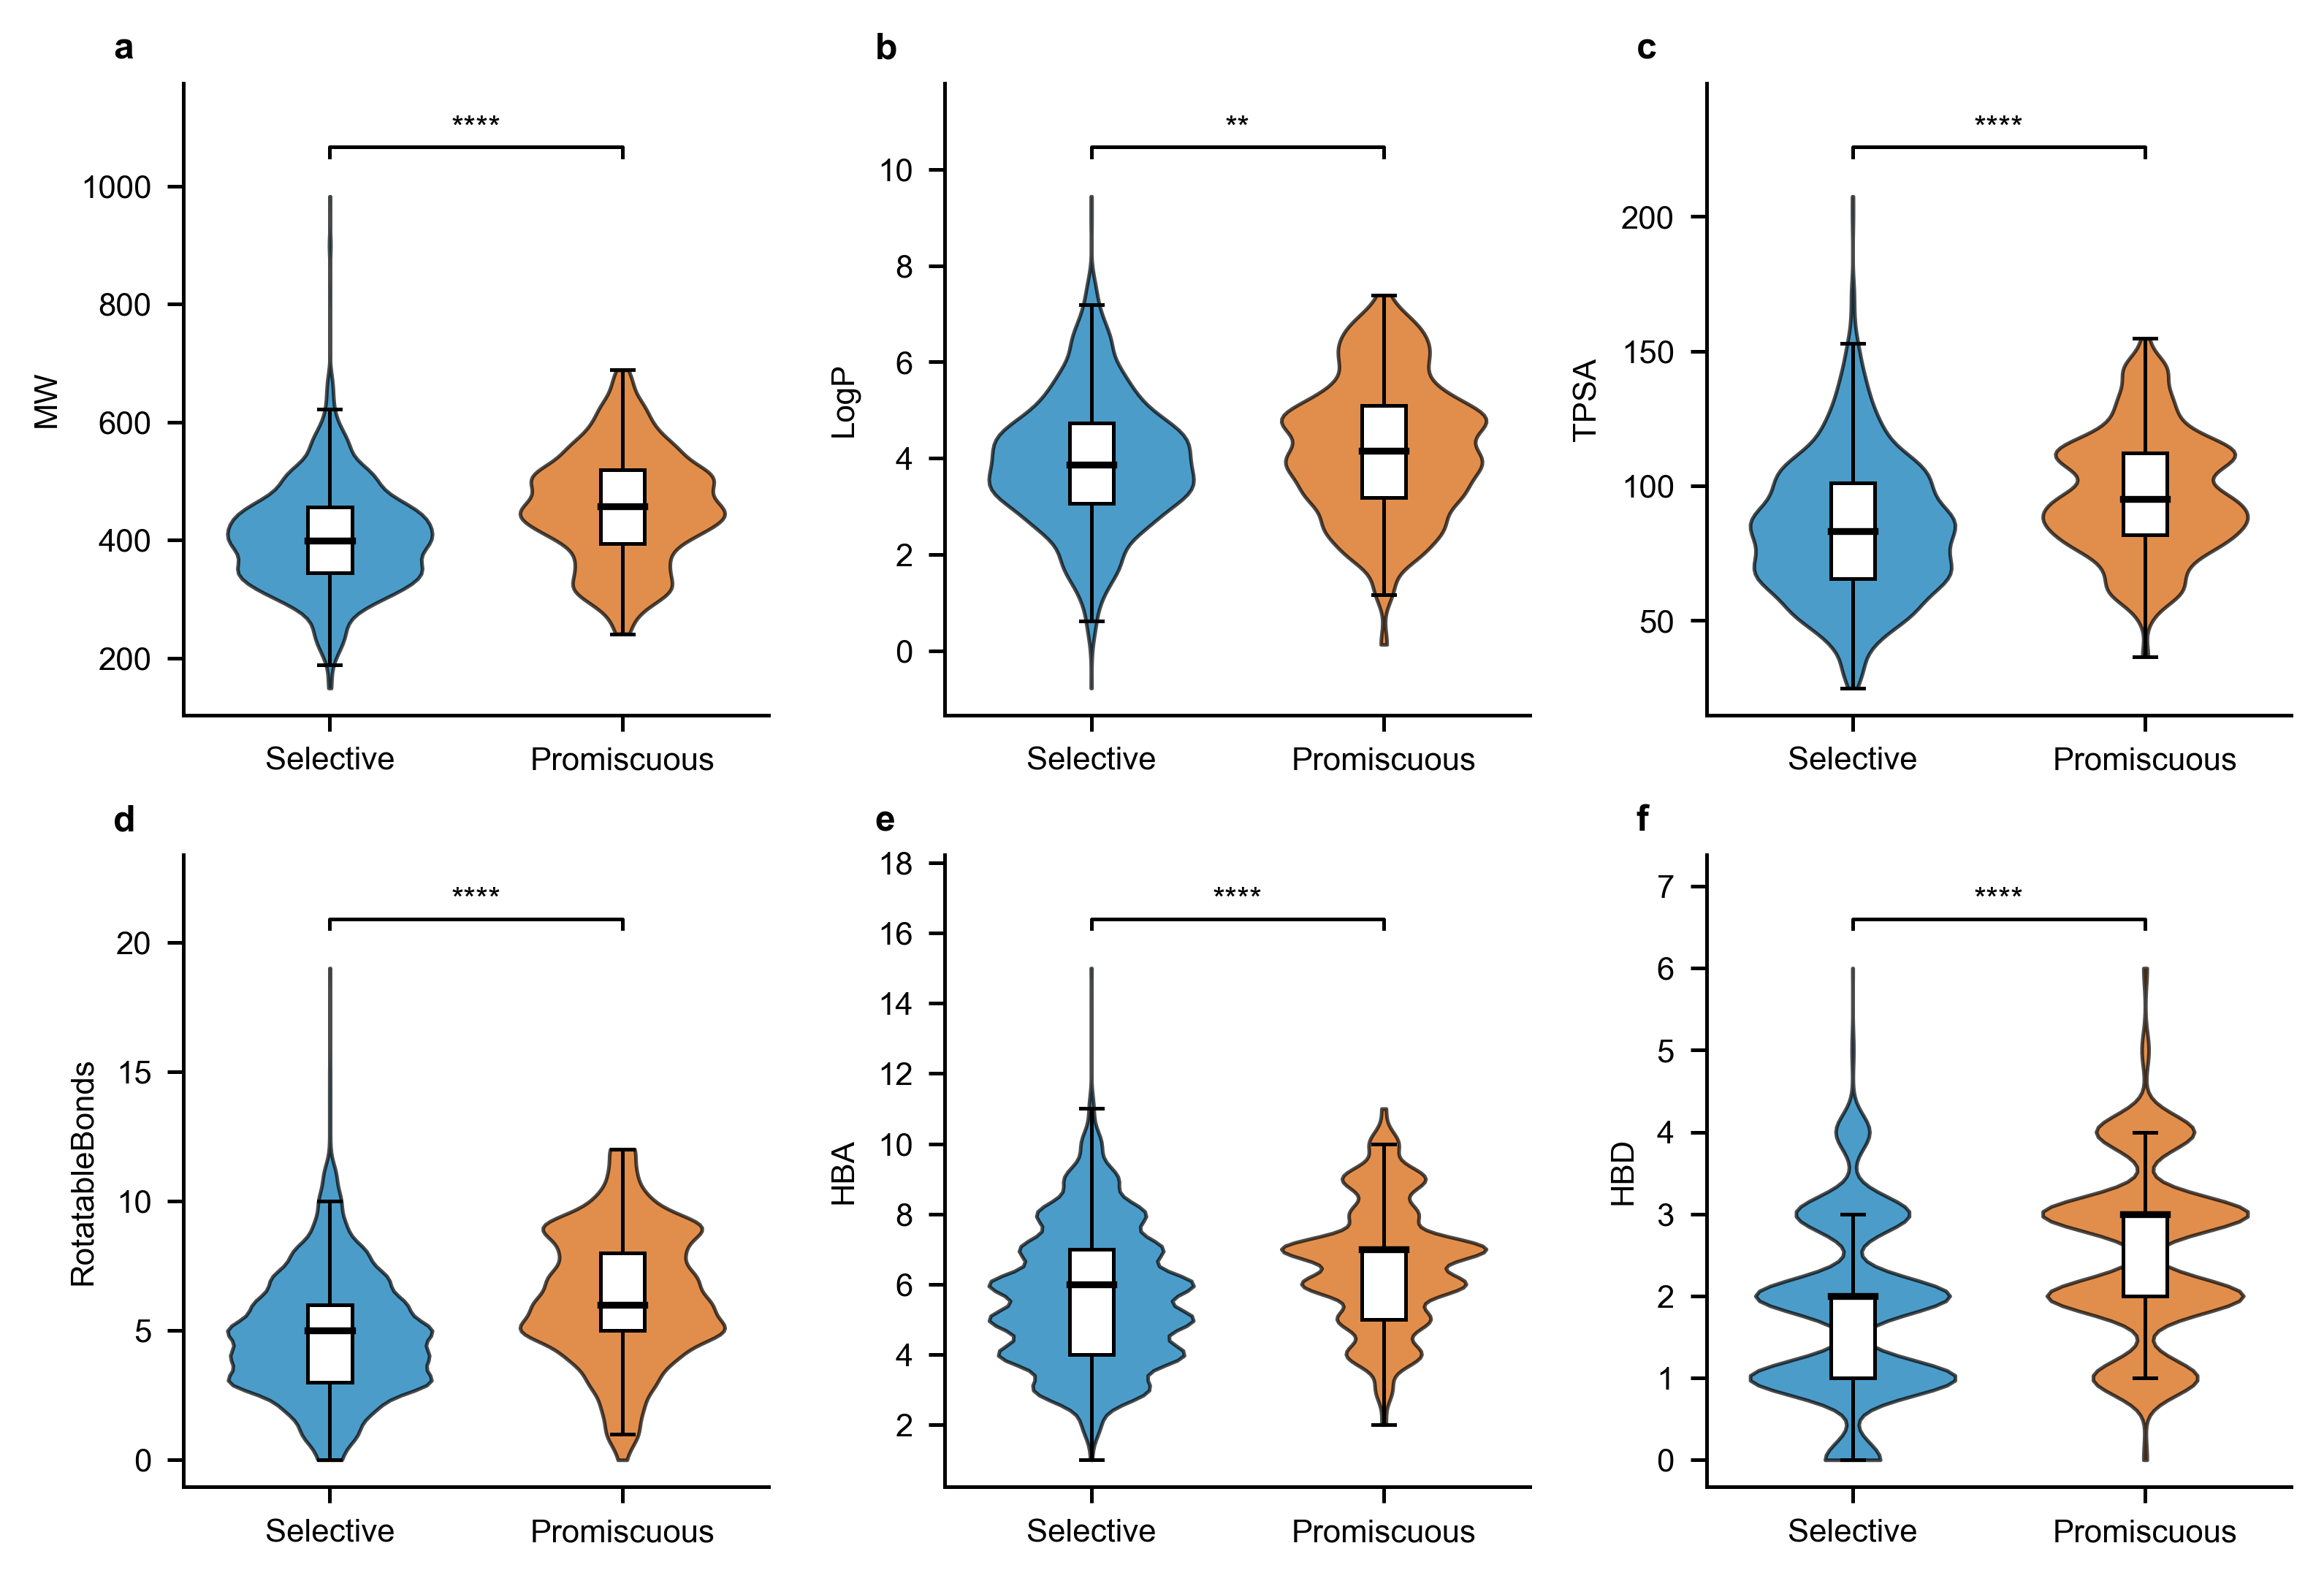

In [29]:
prop_funcs = {
    'MW':             Descriptors.ExactMolWt,
    'LogP':           Descriptors.MolLogP,
    'TPSA':           Descriptors.TPSA,
    'RotatableBonds': Descriptors.NumRotatableBonds,
    'HBA':            Lipinski.NumHAcceptors,
    'HBD':            Lipinski.NumHDonors,
}

def _calc_props(mol):
    return pd.Series({k: f(mol) for k, f in prop_funcs.items()})

prop_cols = kips_df['mol_std'].progress_apply(_calc_props)

df_props = kips_df[['Compound ID', 'SMILES_standardized', 'is_promiscuous']].copy()
df_props['Group'] = df_props['is_promiscuous'].map({True: 'Promiscuous', False: 'Selective'})
df_props = pd.concat([df_props.reset_index(drop=True), prop_cols.reset_index(drop=True)], axis=1)

PROP_NAMES  = list(prop_funcs.keys())
GROUP_ORDER = ['Selective', 'Promiscuous']
GROUP_COLORS = {'Selective': MAIN_COLORS['blue'], 'Promiscuous': MAIN_COLORS['vermillion']}

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.sign(a[:, None] - b[None, :]).sum() / (len(a) * len(b))

def sig_label(p):
    if p < 0.0001: return '****'
    if p < 0.001:  return '***'
    if p < 0.01:   return '**'
    if p < 0.05:   return '*'
    return 'ns'

stats_rows = {}
for prop in PROP_NAMES:
    sel  = df_props.loc[df_props['Group'] == 'Selective',   prop].dropna()
    prom = df_props.loc[df_props['Group'] == 'Promiscuous', prop].dropna()
    _, p = mannwhitneyu(sel, prom, alternative='two-sided')
    stats_rows[prop] = {
        'Median (Selective)':   round(sel.median(), 2),
        'IQR (Selective)':      f"{sel.quantile(0.25):.2f}-{sel.quantile(0.75):.2f}",
        'Median (Promiscuous)': round(prom.median(), 2),
        'IQR (Promiscuous)':    f"{prom.quantile(0.25):.2f}-{prom.quantile(0.75):.2f}",
        'Median Difference':    round(prom.median() - sel.median(), 2),
        'p_value':              p,
        'Cliffs Delta':         cliffs_delta(sel, prom),
    }

descriptor_table = pd.DataFrame(stats_rows).T.rename_axis('Property').reset_index()
for column in ('Median (Selective)', 'Median (Promiscuous)', 'Median Difference'):
    descriptor_table[column] = descriptor_table[column].map('{:g}'.format)
count_properties = descriptor_table['Property'].isin(['RotatableBonds', 'HBA', 'HBD'])
for column in ('IQR (Selective)', 'IQR (Promiscuous)'):
    descriptor_table.loc[count_properties, column] = descriptor_table.loc[count_properties, column].str.replace('.00', '', regex=False)
descriptor_table['p_value'] = descriptor_table['p_value'].map('{:.2E}'.format)
descriptor_table['Cliffs Delta'] = descriptor_table['Cliffs Delta'].map('{:.2f}'.format)
descriptor_table['Property'] = descriptor_table['Property'].replace({'RotatableBonds': 'Rotatable Bonds'})
descriptor_table.rename(columns={'p_value': 'p-value', 'Cliffs Delta': "Cliff's Delta"}).to_csv(
    os.path.join(INFORMATION_TABLES_DIR, 'Supplementary_Table_5_Physicochemical_Properties.csv'), index=False)

fig, axes = plt.subplots(2, 3, figsize=(7.08, 4.8))
fig.patch.set_facecolor('white')

for ax, prop, label in zip(axes.flat, PROP_NAMES, 'abcdef'):
    groups = [df_props.loc[df_props['Group'] == g, prop].dropna().values for g in GROUP_ORDER]

    parts = ax.violinplot(groups, positions=range(2), widths=0.7,
                          showmeans=False, showmedians=False,
                          showextrema=False, bw_method=0.2)
    for pc, g in zip(parts['bodies'], GROUP_ORDER):
        pc.set_facecolor(GROUP_COLORS[g]); pc.set_alpha(0.7)
        pc.set_edgecolor('black'); pc.set_linewidth(0.8)

    ax.boxplot(groups, positions=range(2), widths=0.15, patch_artist=True,
               showfliers=False,
               medianprops=dict(color='black', linewidth=1.5),
               boxprops=dict(facecolor='white', edgecolor='black', linewidth=0.8),
               whiskerprops=dict(color='black', linewidth=0.8),
               capprops=dict(color='black', linewidth=0.8))

    ax.set_xticks(range(2)); ax.set_xticklabels(GROUP_ORDER)
    ax.set_ylabel(prop); ax.spines[['top', 'right']].set_visible(False)

    y_max = df_props[prop].max(); y_min = df_props[prop].min()
    y_rng = max(1, y_max - y_min)
    y_bar = y_max + y_rng * 0.08
    ax.plot([0, 0, 1, 1], [y_bar, y_bar + y_rng*0.02, y_bar + y_rng*0.02, y_bar], lw=0.8, c='k')
    ax.text(0.5, y_bar + y_rng*0.025, sig_label(stats_rows[prop]['p_value']), ha='center', va='bottom', fontsize=7)
    ax.set_ylim(top=y_bar + y_rng * 0.15)
    ax.text(-0.12, 1.08, label, transform=ax.transAxes,fontsize=8, fontweight='bold', va='top', ha='left')

plt.tight_layout()
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_4_Descriptor_Violin.pdf'))
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_4_Descriptor_Violin.png'))
plt.show()

df_props.to_csv(os.path.join(SUPPORTING_DIR, 'Compound_Descriptors.csv'), index=False, float_format='%.2f')

# Chemical space analysis

Does KIPS occupy kinase-relevant chemical space, and do promiscuous and selective inhibitors sit in distinct regions?

In [30]:
kin_smiles_std = pd.read_csv(KINASE_INHIBITORS_FILE)['SMILES'].tolist()
nonkin_smiles_std = pd.read_csv(NON_KINASE_INHIBITORS_FILE)['SMILES'].tolist()
kips_smiles = kips_df['SMILES_standardized'].unique()

def get_fps_and_smiles(smiles_list, desc="Generating FPs"):
    fps_list, valid_smiles = [], []
    skipped = 0
    for smi in tqdm(smiles_list, desc=desc, leave=False):
        mol = Chem.MolFromSmiles(smi)
        if not mol:
            skipped += 1
            continue
        try:
            fp_arr = np.zeros(FP_NBITS, dtype=np.int8)
            DataStructs.ConvertToNumpyArray(AllChem.GetMorganFingerprintAsBitVect(mol, FP_RADIUS, FP_NBITS, useChirality=True), fp_arr)
            fps_list.append(fp_arr)
            valid_smiles.append(smi)
        except Exception:
            skipped += 1
    return np.array(fps_list), valid_smiles
    
def get_rdkit_fps(smiles_list, desc="Generating FPs"):
    fps_list, valid_smiles = [], []
    skipped = 0
    for smi in tqdm(smiles_list, desc=desc, leave=False):
        mol = Chem.MolFromSmiles(smi)
        if not mol:
            skipped += 1
            continue
        try:
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, FP_RADIUS, FP_NBITS, useChirality=True)
            fps_list.append(fp)
            valid_smiles.append(smi)
        except Exception:
            skipped += 1
    return fps_list, valid_smiles

promiscuous_smiles = kips_df[kips_df['is_promiscuous']]['SMILES_standardized'].values
selective_smiles = kips_df[~kips_df['is_promiscuous']]['SMILES_standardized'].values
promiscuous_fps, promiscuous_smiles_valid = get_rdkit_fps(promiscuous_smiles, desc="Promiscuous")
selective_fps, selective_smiles_valid = get_rdkit_fps(selective_smiles, desc="Selective")

# Compute NN: promiscuous to selective
nearest_selective_similarities = []
for fp in tqdm(promiscuous_fps, desc="Processing", leave=False):
    similarities = DataStructs.BulkTanimotoSimilarity(fp, selective_fps)
    nearest_selective_similarities.append(max(similarities))
nearest_selective_similarities = np.array(nearest_selective_similarities)

# Compute NN: selective to promiscuous
nearest_promiscuous_similarities = []
for fp in tqdm(selective_fps, desc="Processing", leave=False):
    similarities = DataStructs.BulkTanimotoSimilarity(fp, promiscuous_fps)
    nearest_promiscuous_similarities.append(max(similarities))
nearest_promiscuous_similarities = np.array(nearest_promiscuous_similarities)

# Compute 5-NN between KIPS and BindingDB
kips_fps_array, _ = get_fps_and_smiles(kips_smiles, desc="KIPS")
kinase_fps_array, _ = get_fps_and_smiles(kin_smiles_std, desc="Kinase")
nonkinase_fps_array, _ = get_fps_and_smiles(nonkin_smiles_std, desc="Non-Kinase")

kips_fps_binary = kips_fps_array.astype(bool)
kinase_fps_binary = kinase_fps_array.astype(bool)
nonkinase_fps_binary = nonkinase_fps_array.astype(bool)

nn_kinase = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_kinase.fit(kinase_fps_binary)
kinase_distances, _ = nn_kinase.kneighbors(kips_fps_binary)
kips_to_kinase_similarities = (1 - kinase_distances).mean(axis=1)

nn_nonkinase = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_nonkinase.fit(nonkinase_fps_binary)
nonkinase_distances, _ = nn_nonkinase.kneighbors(kips_fps_binary)
kips_to_nonkinase_similarities = (1 - nonkinase_distances).mean(axis=1)

# Statistics for promiscuous to selective
q1_prom = np.percentile(nearest_selective_similarities, 25)
q3_prom = np.percentile(nearest_selective_similarities, 75)
prom_to_sel_row = {
    'Direction': 'Promiscuous to Selective',
    'Mean_Tanimoto': nearest_selective_similarities.mean(),
    'Median_Tanimoto': np.median(nearest_selective_similarities),
    'Q1_Tanimoto': q1_prom,
    'Q3_Tanimoto': q3_prom,
    'Percent_Tanimoto≥0.5': 100 * (nearest_selective_similarities >= 0.5).sum() / len(nearest_selective_similarities),
    'Percent_Tanimoto≥0.7': 100 * (nearest_selective_similarities >= 0.7).sum() / len(nearest_selective_similarities),
}

# Statistics for selective to promiscuous
q1_sel = np.percentile(nearest_promiscuous_similarities, 25)
q3_sel = np.percentile(nearest_promiscuous_similarities, 75)
sel_to_prom_row = {
    'Direction': 'Selective to Promiscuous',
    'Mean_Tanimoto': nearest_promiscuous_similarities.mean(),
    'Median_Tanimoto': np.median(nearest_promiscuous_similarities),
    'Q1_Tanimoto': q1_sel,
    'Q3_Tanimoto': q3_sel,
    'Percent_Tanimoto≥0.5': 100 * (nearest_promiscuous_similarities >= 0.5).sum() / len(nearest_promiscuous_similarities),
    'Percent_Tanimoto≥0.7': 100 * (nearest_promiscuous_similarities >= 0.7).sum() / len(nearest_promiscuous_similarities),
}

kips_internal_stats = pd.DataFrame([prom_to_sel_row, sel_to_prom_row])
internal_table = pd.DataFrame({'Direction': kips_internal_stats['Direction']})
for label in ('Mean', 'Median', 'Q1', 'Q3'):
    internal_table[label] = kips_internal_stats[f'{label}_Tanimoto'].map('{:.2f}'.format)
for cutoff in ('0.5', '0.7'):
    internal_table[f'≥{cutoff} (%)'] = kips_internal_stats[f'Percent_Tanimoto≥{cutoff}'].map('{:.1f}'.format)
internal_table.to_csv(os.path.join(INFORMATION_TABLES_DIR, 'Supplementary_Table_4_Nearest_Neighbor_Similarity.csv'), index=False, encoding='utf-8-sig')

# Statistics for KIPS to BindingDB (Mann-Whitney U test)
u_statistic, p_value = mannwhitneyu(kips_to_kinase_similarities, kips_to_nonkinase_similarities, alternative='greater')

q1_kinase = np.percentile(kips_to_kinase_similarities, 25)
q3_kinase = np.percentile(kips_to_kinase_similarities, 75)
q1_nonkinase = np.percentile(kips_to_nonkinase_similarities, 25)
q3_nonkinase = np.percentile(kips_to_nonkinase_similarities, 75)

bindingdb_stats = pd.DataFrame({
    'Target_Set': ['Kinase', 'Non-Kinase'],
    'Mean_Tanimoto_5NN': [kips_to_kinase_similarities.mean(), kips_to_nonkinase_similarities.mean()],
    'Median_Tanimoto_5NN': [np.median(kips_to_kinase_similarities), np.median(kips_to_nonkinase_similarities)],
    'Q1_Tanimoto_5NN': [q1_kinase, q1_nonkinase],
    'Q3_Tanimoto_5NN': [q3_kinase, q3_nonkinase]
})

print(f'Mann-Whitney U (kinase > non-kinase): U={u_statistic:.2e}, p={p_value:.2e}')
bindingdb_table = pd.DataFrame({'Reference Set': 'BindingDB ' + bindingdb_stats['Target_Set']})
for label in ('Mean', 'Median', 'Q1', 'Q3'):
    bindingdb_table[label] = bindingdb_stats[f'{label}_Tanimoto_5NN'].map('{:.2f}'.format)
bindingdb_table.to_csv(os.path.join(INFORMATION_TABLES_DIR, 'Supplementary_Table_3_BindingDB_Similarity.csv'), index=False)

Mann-Whitney U (kinase > non-kinase): U=1.82e+06, p=7.84e-148


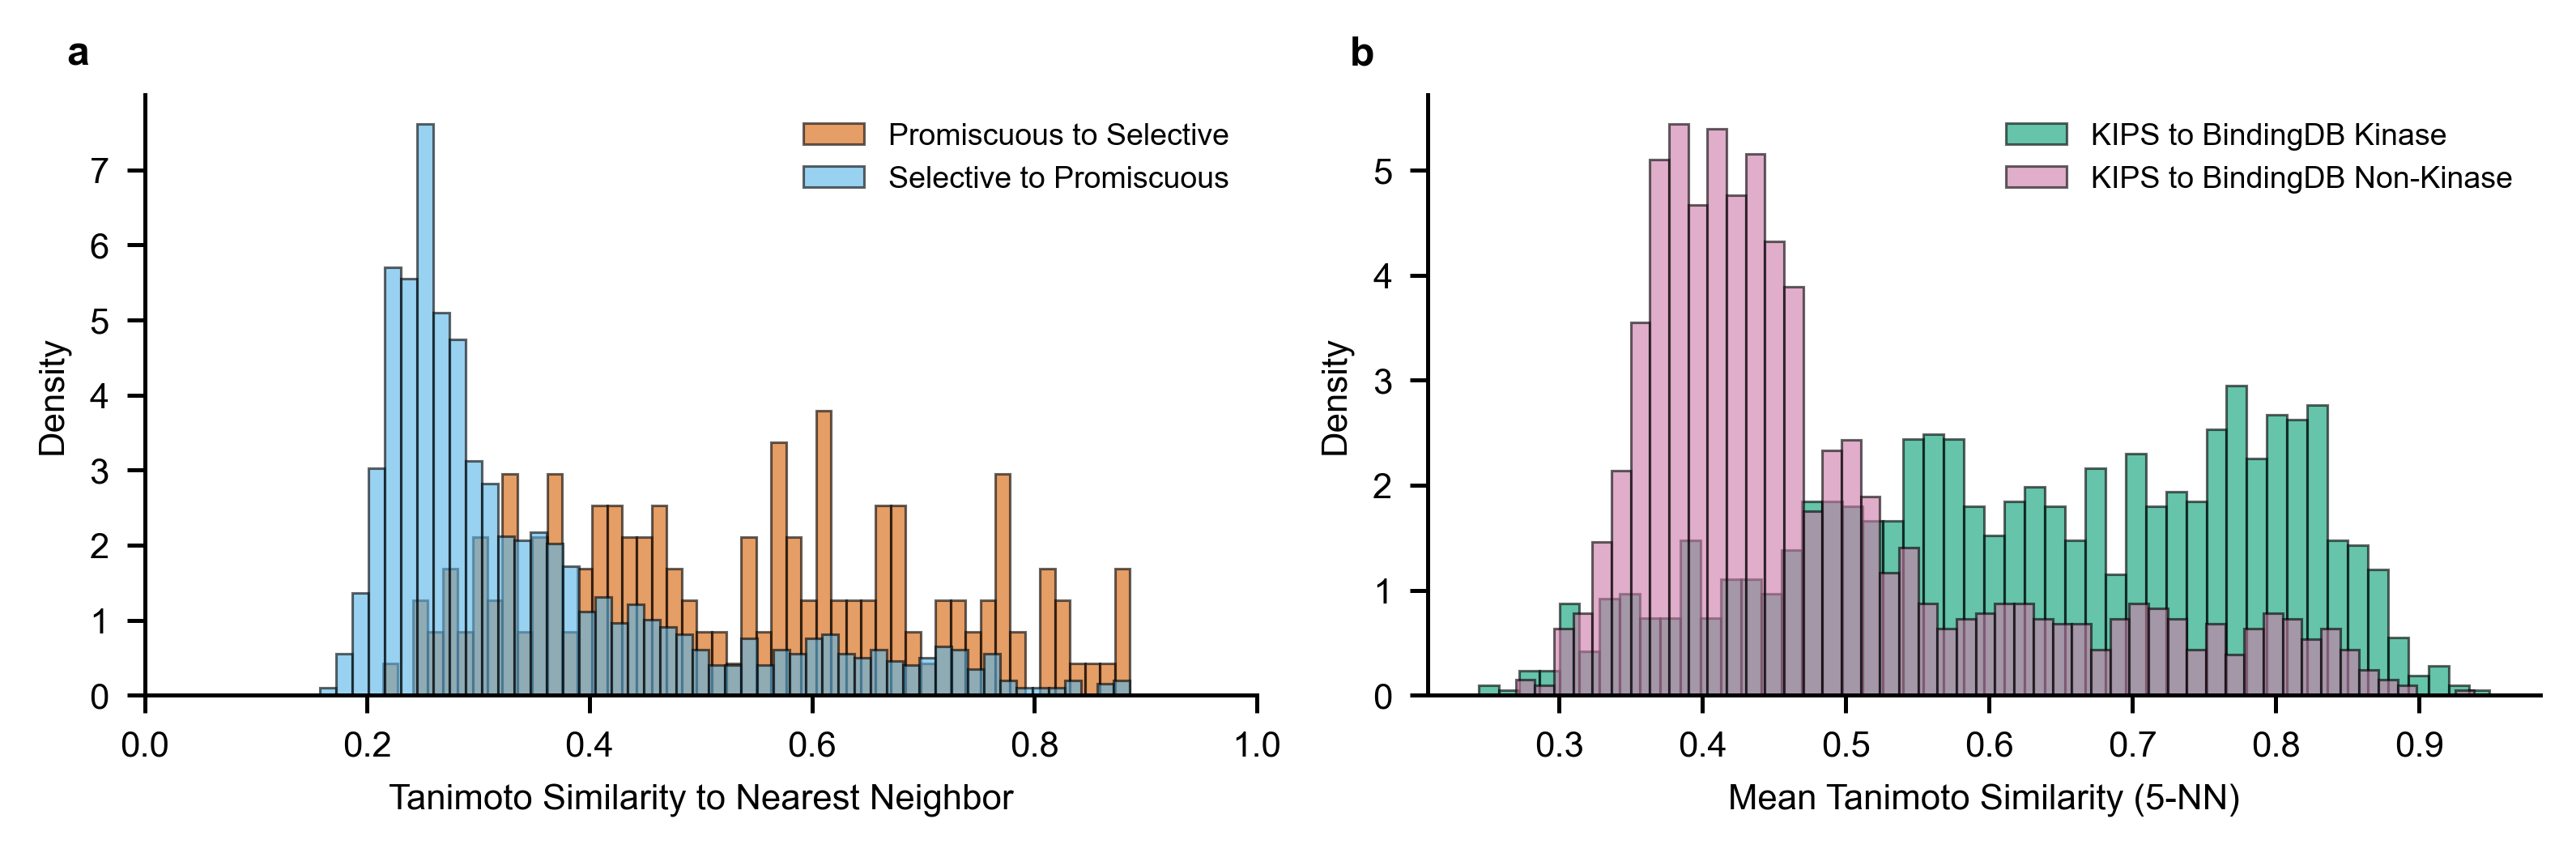

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(7.08, 2.36))

# Panel A: KIPS internal comparisons
axes[0].hist(nearest_selective_similarities, bins=50, 
             color=MAIN_COLORS['vermillion'], alpha=0.6, 
             edgecolor='black', linewidth=0.5, density=True,
             label='Promiscuous to Selective')
axes[0].hist(nearest_promiscuous_similarities, bins=50, 
             color=MAIN_COLORS['skyblue'], alpha=0.6,
             edgecolor='black', linewidth=0.5, density=True,
             label='Selective to Promiscuous')
axes[0].set_xlabel('Tanimoto Similarity to Nearest Neighbor')
axes[0].set_ylabel('Density')
axes[0].set_xlim(0, 1)
axes[0].legend(frameon=False, fontsize=6)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].text(-0.07, 1.05, 'a', transform=axes[0].transAxes, fontsize=8, fontweight='bold')

# Panel B: KIPS to BindingDB comparisons
axes[1].hist(kips_to_kinase_similarities, bins=50, 
             color=MAIN_COLORS['bluishgreen'], alpha=0.6,
             edgecolor='black', linewidth=0.5, density=True,
             label='KIPS to BindingDB Kinase')
axes[1].hist(kips_to_nonkinase_similarities, bins=50, 
             color=MAIN_COLORS['reddishpurple'], alpha=0.6,
             edgecolor='black', linewidth=0.5, density=True,
             label='KIPS to BindingDB Non-Kinase')
axes[1].set_xlabel('Mean Tanimoto Similarity (5-NN)')
axes[1].set_ylabel('Density')
axes[1].legend(frameon=False, fontsize=6)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].text(-0.07, 1.05, 'b', transform=axes[1].transAxes, fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_3_Tanimoto.pdf'))
plt.savefig(os.path.join(MAIN_FIGURES_DIR, 'Figure_3_Tanimoto.png'))
plt.show()

# SMARTS Prevalence

SMARTS Matching: 100%|██████████| 1538/1538 [00:03<00:00, 472.96it/s]


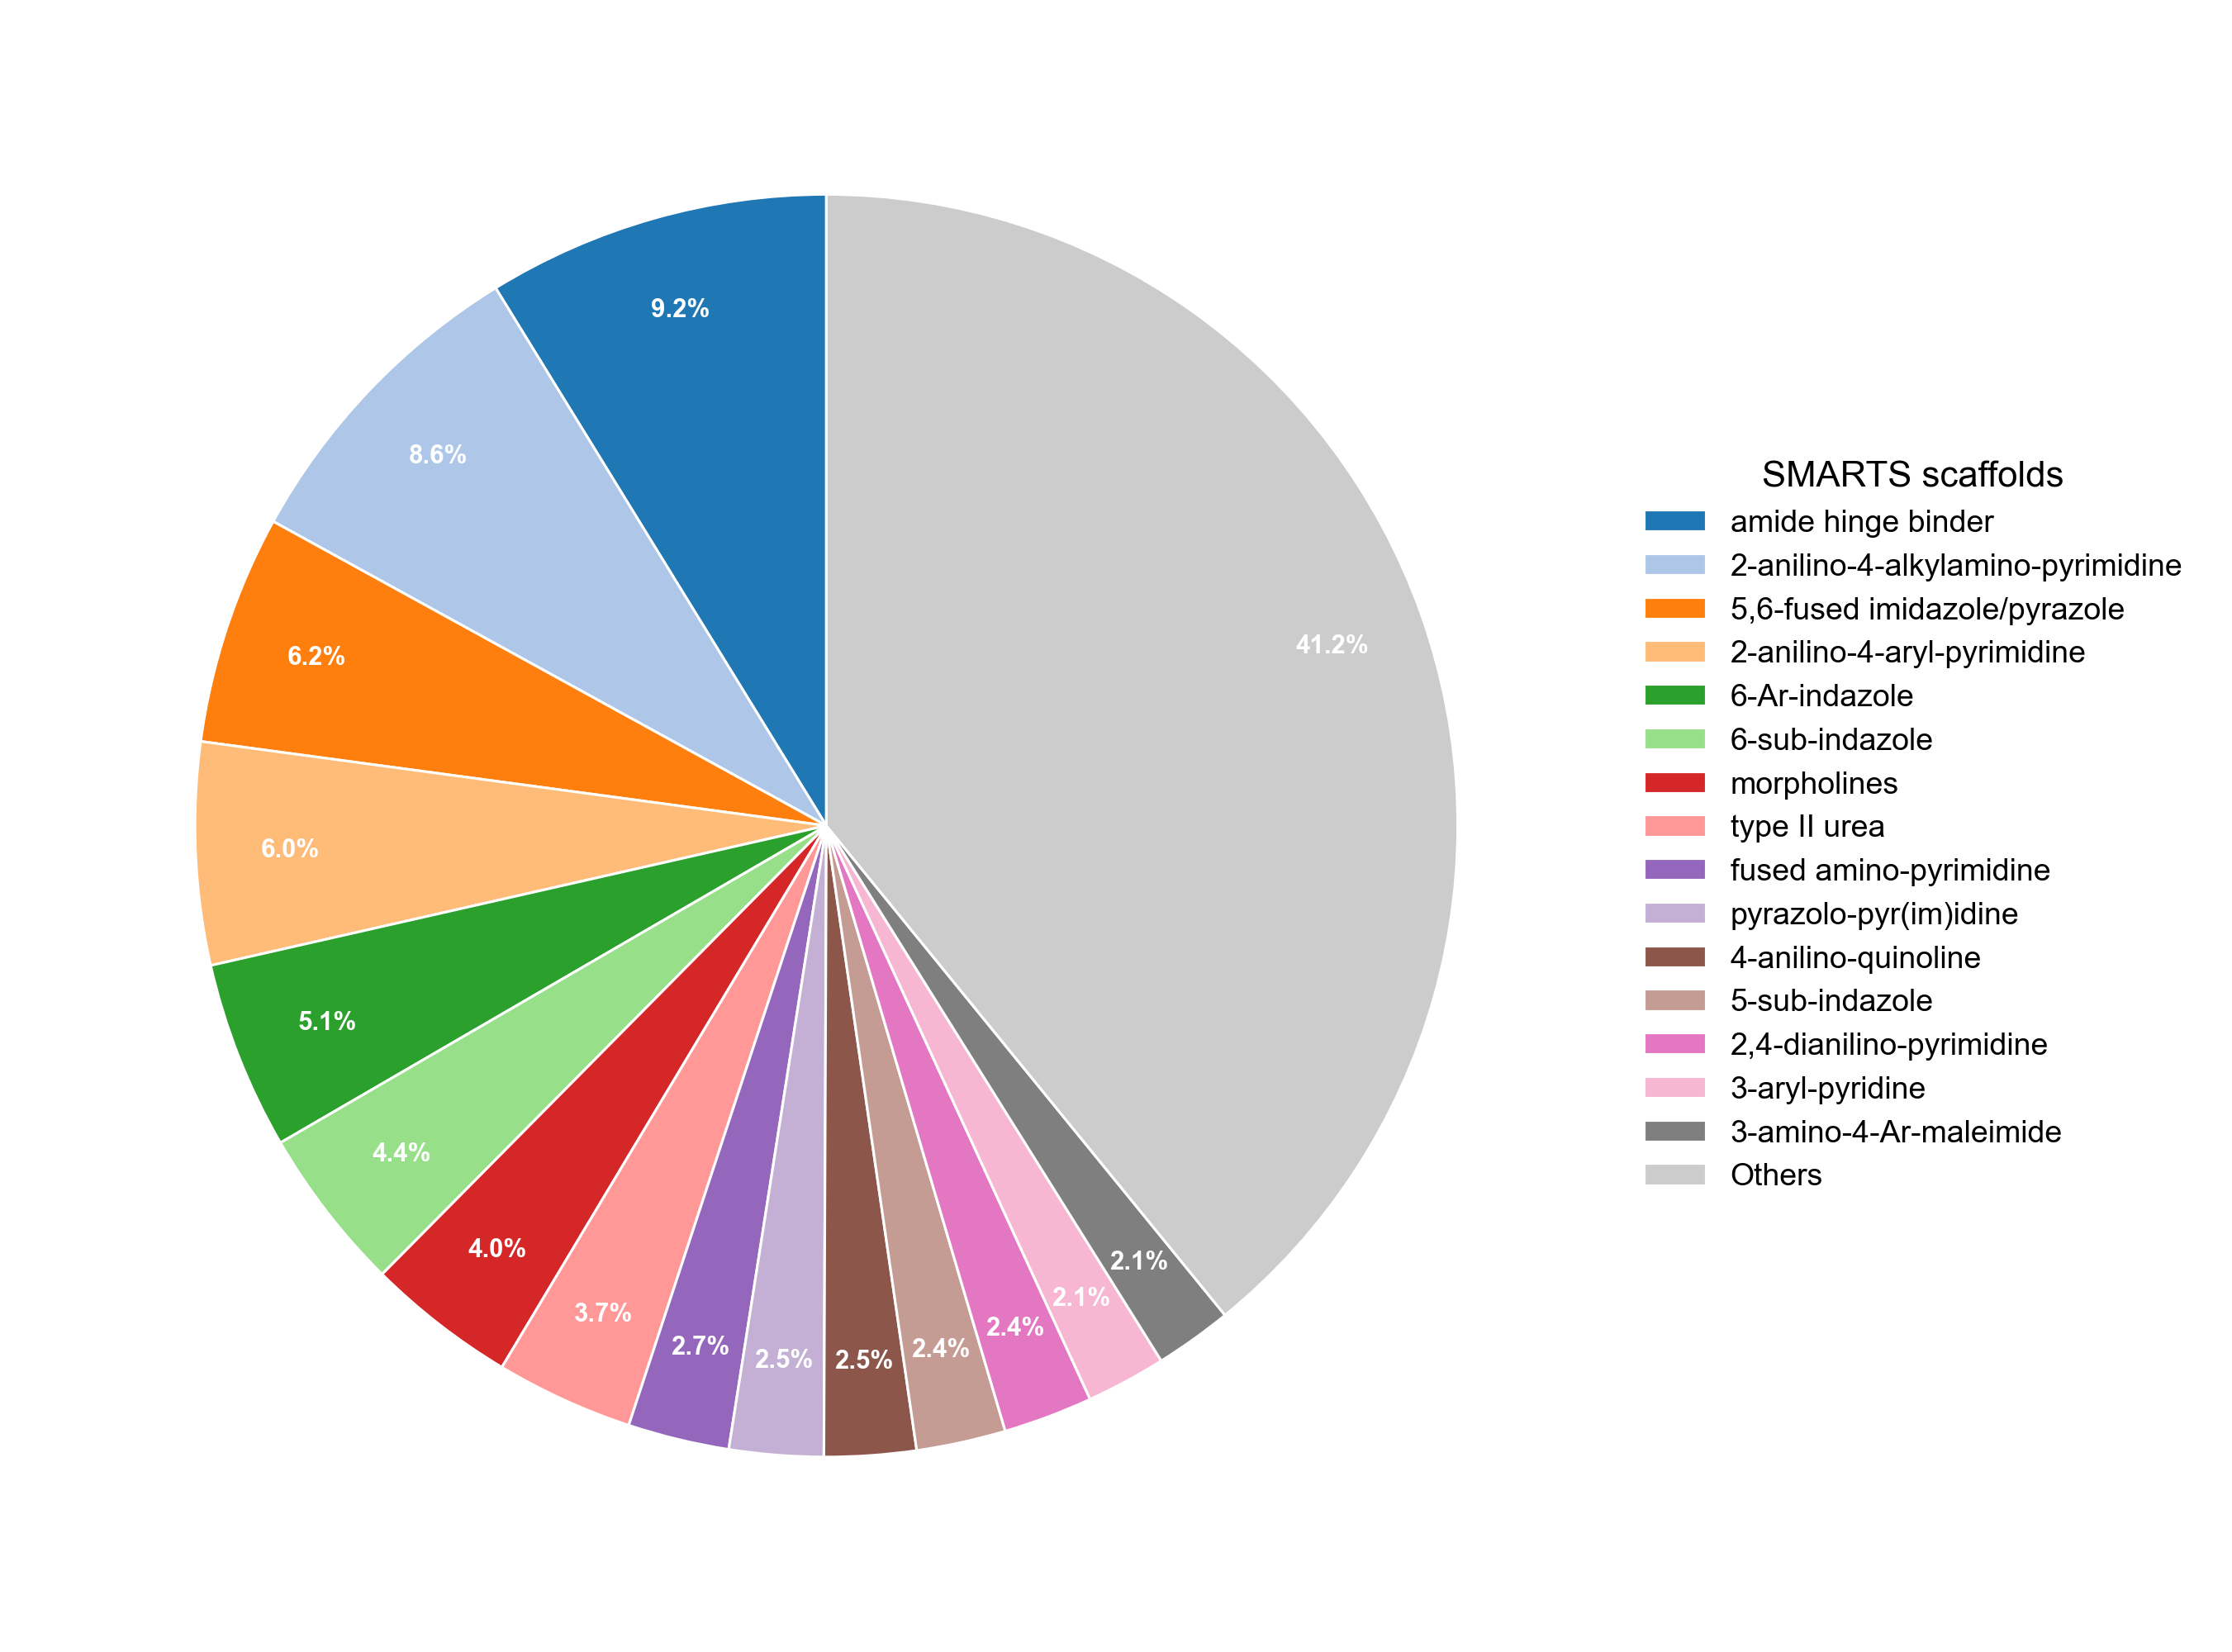

In [32]:
# Load SMARTS
smarts_patterns = {}
smarts_df = pd.read_csv(SMARTS_FILE, encoding='latin1')
for _, row in smarts_df.iterrows():
    name = str(row['Bin names'])
    smarts_str = str(row['SMARTS'])
    mol_pattern = Chem.MolFromSmarts(smarts_str)
    if mol_pattern:
        smarts_patterns[name] = Chem.MergeQueryHs(mol_pattern)

# Match SMARTS
smarts_matches = [
    {name: mol.HasSubstructMatch(patt) for name, patt in smarts_patterns.items()}
    for mol in tqdm(kips_df['mol_std'], desc="SMARTS Matching")
]
matches = pd.DataFrame(smarts_matches, index=kips_df.index)

# SMARTS Pattern Prevalence in KIPS
prevalence = []
for name in smarts_patterns.keys():
    hits = matches[name]
    total_hits = hits.sum()
    percentage = (total_hits / len(kips_df)) * 100
    prevalence.append({
        'Scaffold_Name': name,
        'Total_Hits': total_hits,
        'Percentage': percentage
    })

prevalence_df = pd.DataFrame(prevalence)
prevalence_df = prevalence_df.sort_values(by='Total_Hits', ascending=False)
prevalence_df.assign(Scaffold_Name=prevalence_df['Scaffold_Name'].str.replace('\x97', '—', regex=False)).rename(
    columns={'Scaffold_Name': 'Scaffold Name', 'Total_Hits': 'Total Hits'}).to_csv(
    os.path.join(DATA_TABLES_DIR, 'Supplementary_Data_Table_3_SMARTS_Prevalence.csv'), index=False, float_format='%.3g', encoding='utf-8-sig')

top_patterns = prevalence_df[prevalence_df['Total_Hits'] > 0].head(15).copy()
if len(prevalence_df[prevalence_df['Total_Hits'] > 0]) > 15:
    others_percentage = prevalence_df[prevalence_df['Total_Hits'] > 0].iloc[15:]['Percentage'].sum()
    others_count = prevalence_df[prevalence_df['Total_Hits'] > 0].iloc[15:]['Total_Hits'].sum()
    others_row = pd.DataFrame([{
        'Scaffold_Name': 'Others',
        'Total_Hits': others_count,
        'Percentage': others_percentage
    }])
    top_patterns = pd.concat([top_patterns, others_row], ignore_index=True)

cmap_pie = plt.colormaps.get_cmap('tab20')
colors = [cmap_pie(i) for i in range(len(top_patterns))]
if 'Others' in top_patterns['Scaffold_Name'].values:
    colors[-1] = '#cccccc'

fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor('white')

wedges, texts = ax.pie(
    top_patterns['Percentage'],
    labels=None,
    colors=colors,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 0.5}
)

for wedge, pct in zip(wedges, top_patterns['Percentage']):
    angle = (wedge.theta2 + wedge.theta1) / 2
    x = 0.85 * np.cos(np.radians(angle))
    y = 0.85 * np.sin(np.radians(angle))
    ax.text(x, y, f'{pct:.1f}%', ha='center', va='center',
            fontsize=5, fontweight='bold', color='white')

ax.legend(wedges, [str(l)[:35] for l in top_patterns['Scaffold_Name']],
          title="SMARTS scaffolds", title_fontsize=7,
          loc='center left', bbox_to_anchor=(1.0, 0.5),
          fontsize=6, frameon=False)

ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_5_SMARTS_Scaffold_Prevalence.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_5_SMARTS_Scaffold_Prevalence.png'), bbox_inches='tight')
plt.show()

# SMARTS Enrichment analysis

In [33]:
n_promiscuous = kips_df['is_promiscuous'].sum()
n_selective   = len(kips_df) - n_promiscuous
print(f"{n_promiscuous} promiscuous  |  {n_selective} selective")

# Fisher's exact test
def calculate_enrichment_stats(a, b, c, d):
    OR, p_value = fisher_exact([[a, b], [c, d]], alternative='greater')
    
    return {
        'Odds_Ratio': 999999 if np.isinf(OR) else OR,
        'P_value_raw': p_value
    }

# Promiscuous enrichment
prom_enrichment = []

for name in tqdm(smarts_patterns.keys(), desc="Enrichment (Promiscuous)", leave=False):
    hits = matches[name]
    
    a = kips_df.loc[hits & kips_df['is_promiscuous']].shape[0]
    b = kips_df.loc[hits & ~kips_df['is_promiscuous']].shape[0]
    c = n_promiscuous - a
    d = n_selective - b
    
    stats = calculate_enrichment_stats(a, b, c, d)
    
    prom_enrichment.append({
        'Scaffold_Name': name,
        'Total_Hits': hits.sum(),
        'Promiscuous_Hits_a': a,
        'Selective_Hits_b': b,
        'Promiscuous_NonHits_c': c,
        'Selective_NonHits_d': d,
        **stats
    })

prom_df = pd.DataFrame(prom_enrichment)
prom_df['P_value_BH'] = multipletests(prom_df['P_value_raw'], alpha=0.05, method='fdr_bh')[1]
prom_df['-log10_P_raw'] = -np.log10(prom_df['P_value_raw'].clip(lower=1e-100))
prom_df['-log10_P_BH'] = -np.log10(prom_df['P_value_BH'].clip(lower=1e-100))
prom_df = prom_df.sort_values(by='P_value_BH', ascending=True)

pd.DataFrame({
    'Scaffold Name': prom_df['Scaffold_Name'].str.replace('\x97', '—', regex=False),
    'Total Occurrences': prom_df['Total_Hits'],
    'Promiscuous Hits': prom_df['Promiscuous_Hits_a'],
    'Selective Hits': prom_df['Selective_Hits_b'],
    'Odds Ratio': prom_df['Odds_Ratio'].map(lambda value: f'{value:.2E}' if value >= 1e5 else f'{value:.2f}', na_action='ignore'),
    'P value (Raw)': prom_df['P_value_raw'].map('{:.2E}'.format),
    'P value (BH-corrected)': prom_df['P_value_BH'].map('{:.2E}'.format),
    'log(P value (BH-corrected))': (prom_df['-log10_P_BH'] + 0.0).map('{:.2f}'.format),
}).to_csv(os.path.join(DATA_TABLES_DIR, 'Supplementary_Data_Table_2_SMARTS_Enrichment.csv'), index=False, encoding='utf-8-sig')

n_sig_raw = (prom_df['P_value_raw'] < P_VALUE_THRESHOLD).sum()
n_sig_bh = (prom_df['P_value_BH'] < P_VALUE_THRESHOLD).sum()
print(f"Promiscuous enrichment: {n_sig_raw} significant (raw p<{P_VALUE_THRESHOLD}), "f"{n_sig_bh} significant (BH-adjusted p<{P_VALUE_THRESHOLD})")

177 promiscuous  |  1361 selective


Promiscuous enrichment: 10 significant (raw p<0.05), 6 significant (BH-adjusted p<0.05)


# SMARTS Enrichment plot

In [34]:
SI_COL = 'SI65'

def _smarts_to_mol(name):
    row = smarts_df[smarts_df['Bin names'] == name]
    if row.empty:
        return None
    rw = Chem.RWMol(Chem.MolFromSmarts(str(row.iloc[0]['SMARTS'])))
    if rw is None:
        return None

    # Remove ?-? chains
    changed = True
    while changed:
        changed = False
        for atom in rw.GetAtoms():
            if atom.GetAtomicNum() == 0 and all(
                nb.GetAtomicNum() == 0 for nb in atom.GetNeighbors()
            ):
                rw.RemoveAtom(atom.GetIdx())
                changed = True
                break

    # Surviving wildcards → R label for display
    for atom in rw.GetAtoms():
        if atom.GetAtomicNum() == 0:
            atom.SetProp('atomLabel', 'R')

    return rw.GetMol()

def generate_promiscuous_figure(sig_df, matches_df, scaffold_col, p_col, composite_name, color_scheme='viridis'):
    
    fig_dir   = MAIN_FIGURES_DIR
    plot_data = sig_df.sort_values(by=p_col, ascending=True)
    names     = plot_data[scaffold_col].tolist()
    
    if not names:
        print(f"No significant scaffolds for {composite_name}"); 
        return

    cmap      = plt.colormaps.get_cmap(color_scheme)
    color_map = {n: cmap(i / max(len(names) - 1, 1)) for i, n in enumerate(names)}

    # A
    fig_bar, ax_bar = plt.subplots(figsize=(3.54, 2.6))
    ax_bar.barh(plot_data[scaffold_col], plot_data[p_col],
                color=[color_map[n] for n in names],
                edgecolor='black', linewidth=0.5)
    ax_bar.set_xlabel('-log10(BH-adjusted p)', fontsize=7)
    ax_bar.tick_params(axis='both', labelsize=7)
    ax_bar.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(pad=0.3)
    bar_path = os.path.join(PANELS_DIR, f"{composite_name}_Panel_A.png")
    plt.savefig(bar_path, dpi=450, bbox_inches='tight'); plt.close(fig_bar)

    # B
    top     = names[::-1]
    si_rows = [{'Scaffold': n, SI_COL: s}
               for n in top
               for s in kips_df.loc[matches_df[n], SI_COL].dropna()]
    si_df   = pd.DataFrame(si_rows)
    counts  = si_df.groupby('Scaffold')[SI_COL].count().reindex(top).fillna(0).astype(int)

    fig_box, ax_box = plt.subplots(figsize=(3.54, 2.6))
    sns.boxplot(x='Scaffold', y=SI_COL, data=si_df, order=top,
                palette=color_map, hue='Scaffold', legend=False,
                showfliers=True, linewidth=1.0, ax=ax_box,
                flierprops=dict(marker='o', markersize=1.5, markeredgewidth=0.5,
                                markeredgecolor='black', markerfacecolor='black',
                                alpha=0.5))
    ax_box.set_xticks(range(len(top)))
    ax_box.set_xticklabels([f"{n}\n(n={counts[n]})" for n in top], rotation=45, ha='right', fontsize=7)
    ax_box.set_xlabel(''); ax_box.set_ylabel(SI_COL, fontsize=7)
    ax_box.tick_params(axis='y', labelsize=7)
    ax_box.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(pad=0.3)
    box_path = os.path.join(PANELS_DIR, f"{composite_name}_Panel_B.png")
    plt.savefig(box_path, dpi=450, bbox_inches='tight'); plt.close(fig_box)

    from rdkit.Chem.Draw import rdMolDraw2D
    from matplotlib import font_manager
    import io
    import textwrap

    scaffolds = [(n, _smarts_to_mol(n)) for n in names]
    scaffolds = [(n, m) for n, m in scaffolds if m is not None]
    n_cols_c = 3
    n_rows_c = max(1, (len(scaffolds) + n_cols_c - 1) // n_cols_c)
    panel_width = 7.08
    panel_height = 1.225 * n_rows_c
    atom_font = font_manager.findfont(font_manager.FontProperties(family='Arial'))
    drawings = []
    for name, molecule in scaffolds:
        display_graph = Chem.RWMol()
        for original_atom in molecule.GetAtoms():
            atom = Chem.Atom(original_atom.GetAtomicNum())
            atom.SetFormalCharge(original_atom.GetFormalCharge())
            atom.SetIsotope(original_atom.GetIsotope())
            atom.SetIsAromatic(original_atom.GetIsAromatic())
            atom.SetNumExplicitHs(original_atom.GetNumExplicitHs())
            atom.SetNoImplicit(True)
            if original_atom.HasProp('atomLabel'):
                atom.SetProp('atomLabel', original_atom.GetProp('atomLabel'))
            display_graph.AddAtom(atom)
        for bond in molecule.GetBonds():
            display_graph.AddBond(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bond.GetBondType())
            display_graph.GetBondWithIdx(display_graph.GetNumBonds() - 1).SetIsAromatic(bond.GetIsAromatic())
        molecule = display_graph.GetMol()
        molecule.UpdatePropertyCache(strict=False)
        Chem.GetSymmSSSR(molecule)
        AllChem.Compute2DCoords(molecule)
        rendered = []
        for drawer in (rdMolDraw2D.MolDraw2DCairo(1200, 500),):
            options = drawer.drawOptions()
            options.useBWAtomPalette()
            options.setQueryColour((0., 0., 0.))
            options.fontFile = atom_font
            options.fixedFontSize = 64
            options.fixedBondLength = 100
            options.bondLineWidth = 5
            options.padding = .035
            options.prepareMolsBeforeDrawing = False
            drawer.DrawMolecule(molecule)
            drawer.FinishDrawing()
            rendered.append(drawer.GetDrawingText())
        drawings.append((name, mpimg.imread(io.BytesIO(rendered[0]), format='png')))

    def add_scaffold_panel(figure, bottom_inches):
        fig_width, fig_height = figure.get_size_inches()
        cell_width, cell_height = panel_width / n_cols_c, panel_height / n_rows_c
        image_width = cell_width - 10 / 72
        image_height = image_width * 500 / 1200
        for i, (name, image_data) in enumerate(drawings):
            row, col = divmod(i, n_cols_c)
            left = col * cell_width + 5 / 72
            top = bottom_inches + panel_height - row * cell_height - 3 / 72
            ax = figure.add_axes([left / fig_width, (top - image_height) / fig_height,
                                  image_width / fig_width, image_height / fig_height])
            ax.imshow(image_data, interpolation='none')
            ax.axis('off')
            figure.text((col + .5) * cell_width / fig_width,
                         (top - image_height - 4 / 72) / fig_height,
                         textwrap.fill(str(name).replace('\x97', '-'), 35),
                         ha='center', va='top', fontsize=6.5, fontfamily='Arial')

    with plt.rc_context({'savefig.bbox': None}):
        fig_c = plt.figure(figsize=(panel_width, panel_height), facecolor='white')
        add_scaffold_panel(fig_c, 0)
        mol_path = os.path.join(PANELS_DIR, f'{composite_name}_Panel_C.png')
        fig_c.savefig(mol_path, dpi=450)
        fig_c.savefig(os.path.join(PANELS_DIR, f'{composite_name}_Panel_C.pdf'), dpi=450)
        plt.close(fig_c)

    img_a = mpimg.imread(bar_path)
    img_b = mpimg.imread(box_path)
    top_margin, bottom_margin, panel_gap = .22, .03, .20
    side_margin, column_gap = .03, .18
    top_width = (panel_width - 2 * side_margin - column_gap) / 2
    heights_ab = [top_width * image.shape[0] / image.shape[1] for image in (img_a, img_b)]
    top_height = max(heights_ab)
    composite_height = top_margin + top_height + panel_gap + panel_height + bottom_margin
    with plt.rc_context({'savefig.bbox': None}):
        fig_comp = plt.figure(figsize=(panel_width, composite_height), facecolor='white')
        for col, (image_data, image_height, letter) in enumerate(zip((img_a, img_b), heights_ab, 'ab')):
            left = side_margin + col * (top_width + column_gap)
            top = composite_height - top_margin
            ax = fig_comp.add_axes([left / panel_width, (top - image_height) / composite_height,
                                    top_width / panel_width, image_height / composite_height])
            ax.imshow(image_data, interpolation='none')
            ax.axis('off')
            fig_comp.text(left / panel_width, (top + .06) / composite_height,
                           letter, fontsize=8, fontweight='bold', va='bottom')
        add_scaffold_panel(fig_comp, bottom_margin)
        fig_comp.text(side_margin / panel_width,
                       (bottom_margin + panel_height + .035) / composite_height,
                       'c', fontsize=8, fontweight='bold', va='bottom')
        for ext in ('pdf', 'png'):
            fig_comp.savefig(os.path.join(fig_dir, f'{composite_name}.{ext}'), dpi=450)
        plt.show()

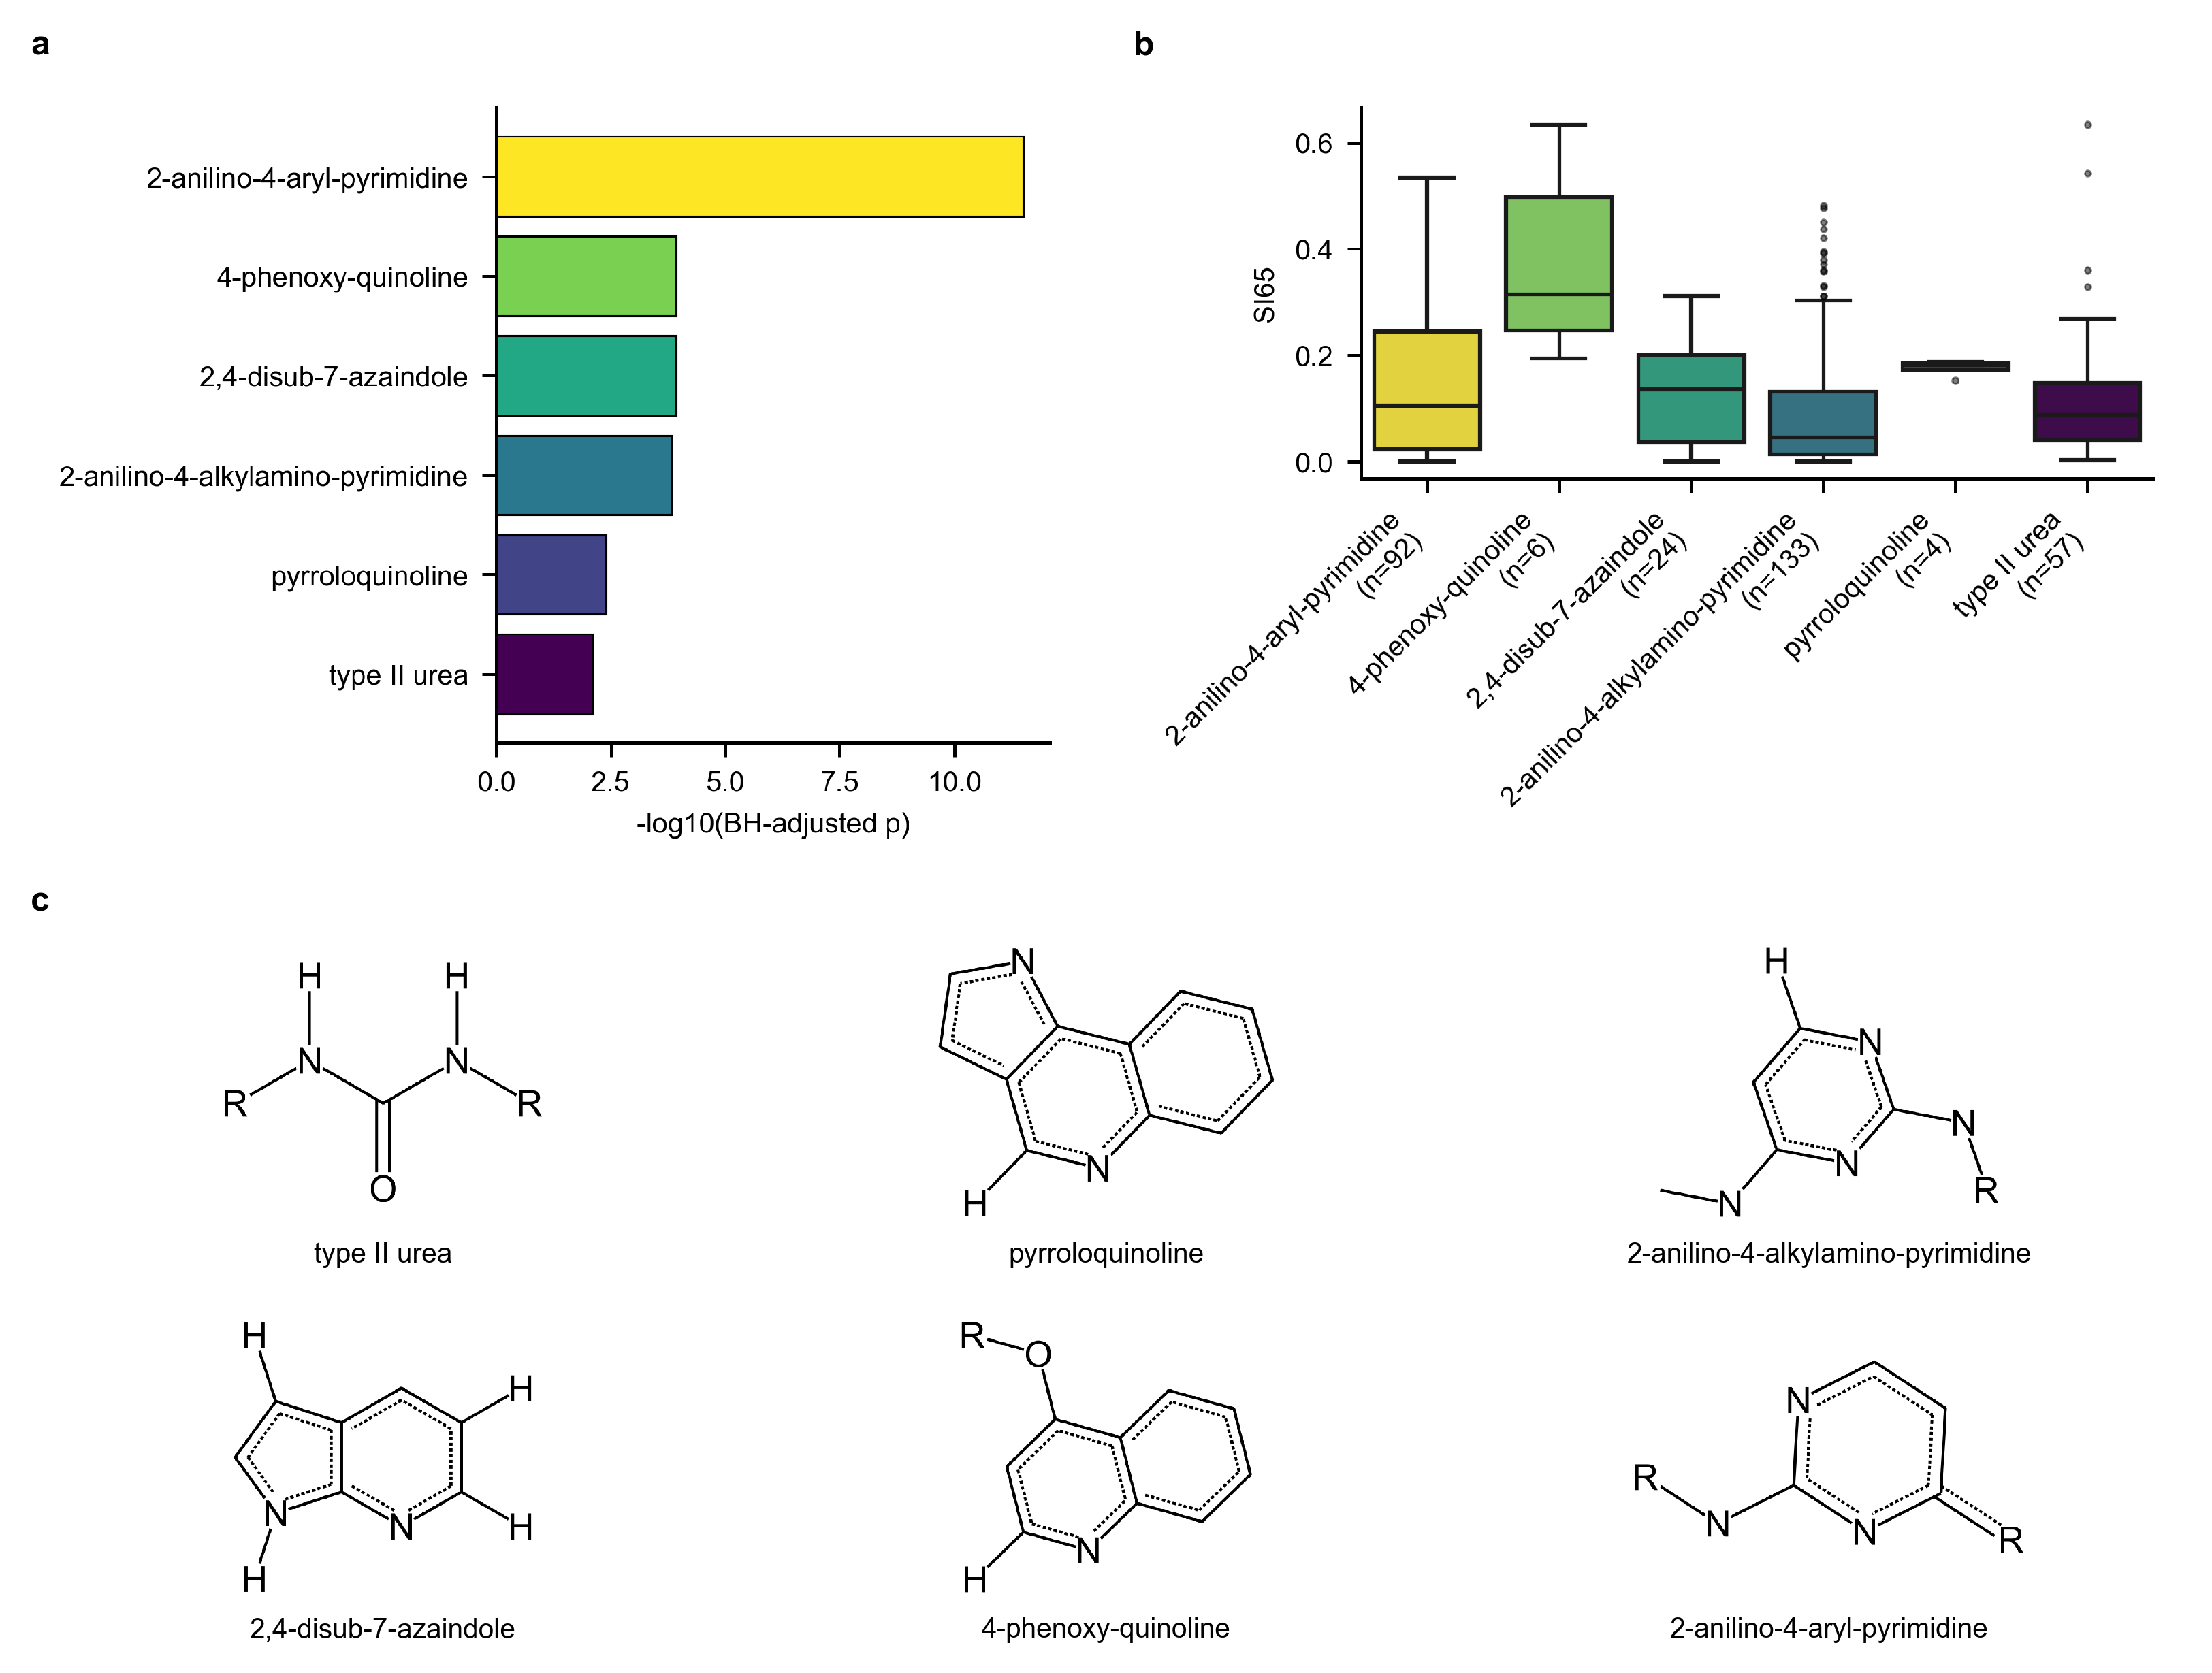

In [35]:
sig_prom = prom_df[prom_df['P_value_BH'] < P_VALUE_THRESHOLD]
generate_promiscuous_figure(sig_prom, matches, 'Scaffold_Name', '-log10_P_BH', 'Figure_5_SMARTS')

# SMARTS enrichment sensitivity across SI thresholds

Recompute SI50, SI65 and SI90 on the same retained compounds and wild-type kinase
panel. Refit Kneedle with the primary analysis settings for each response threshold

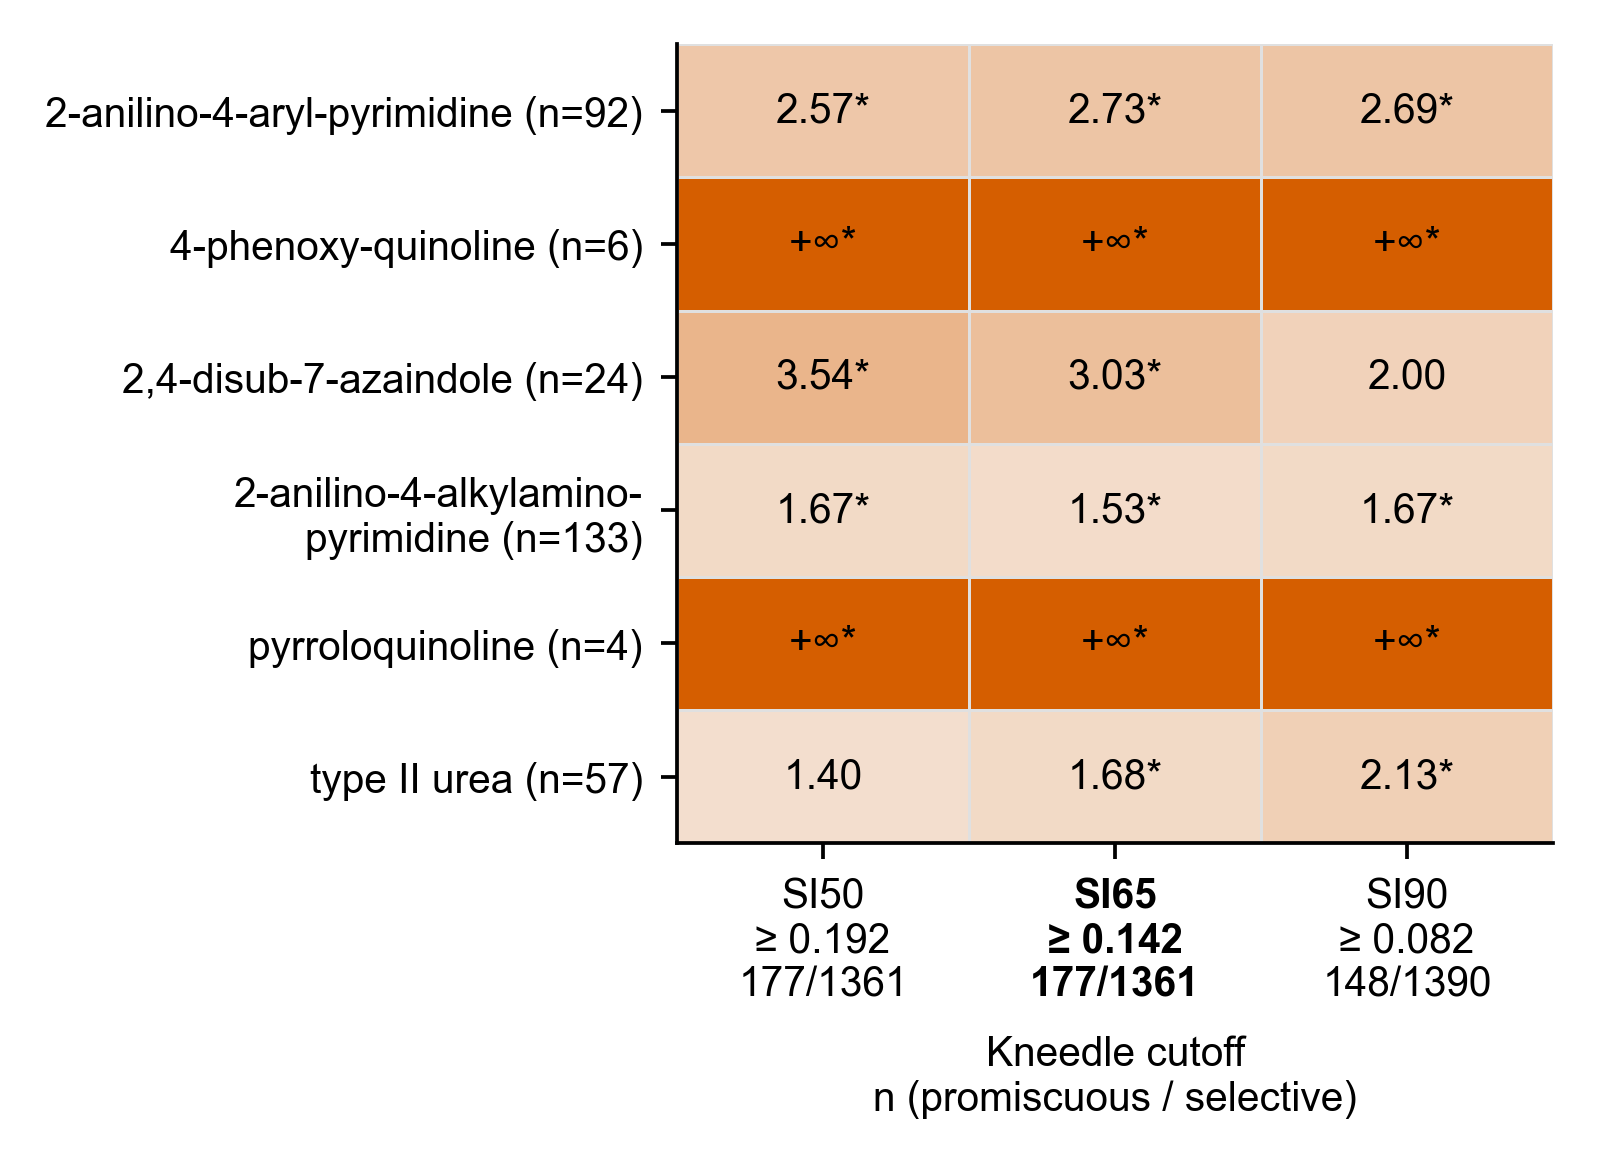

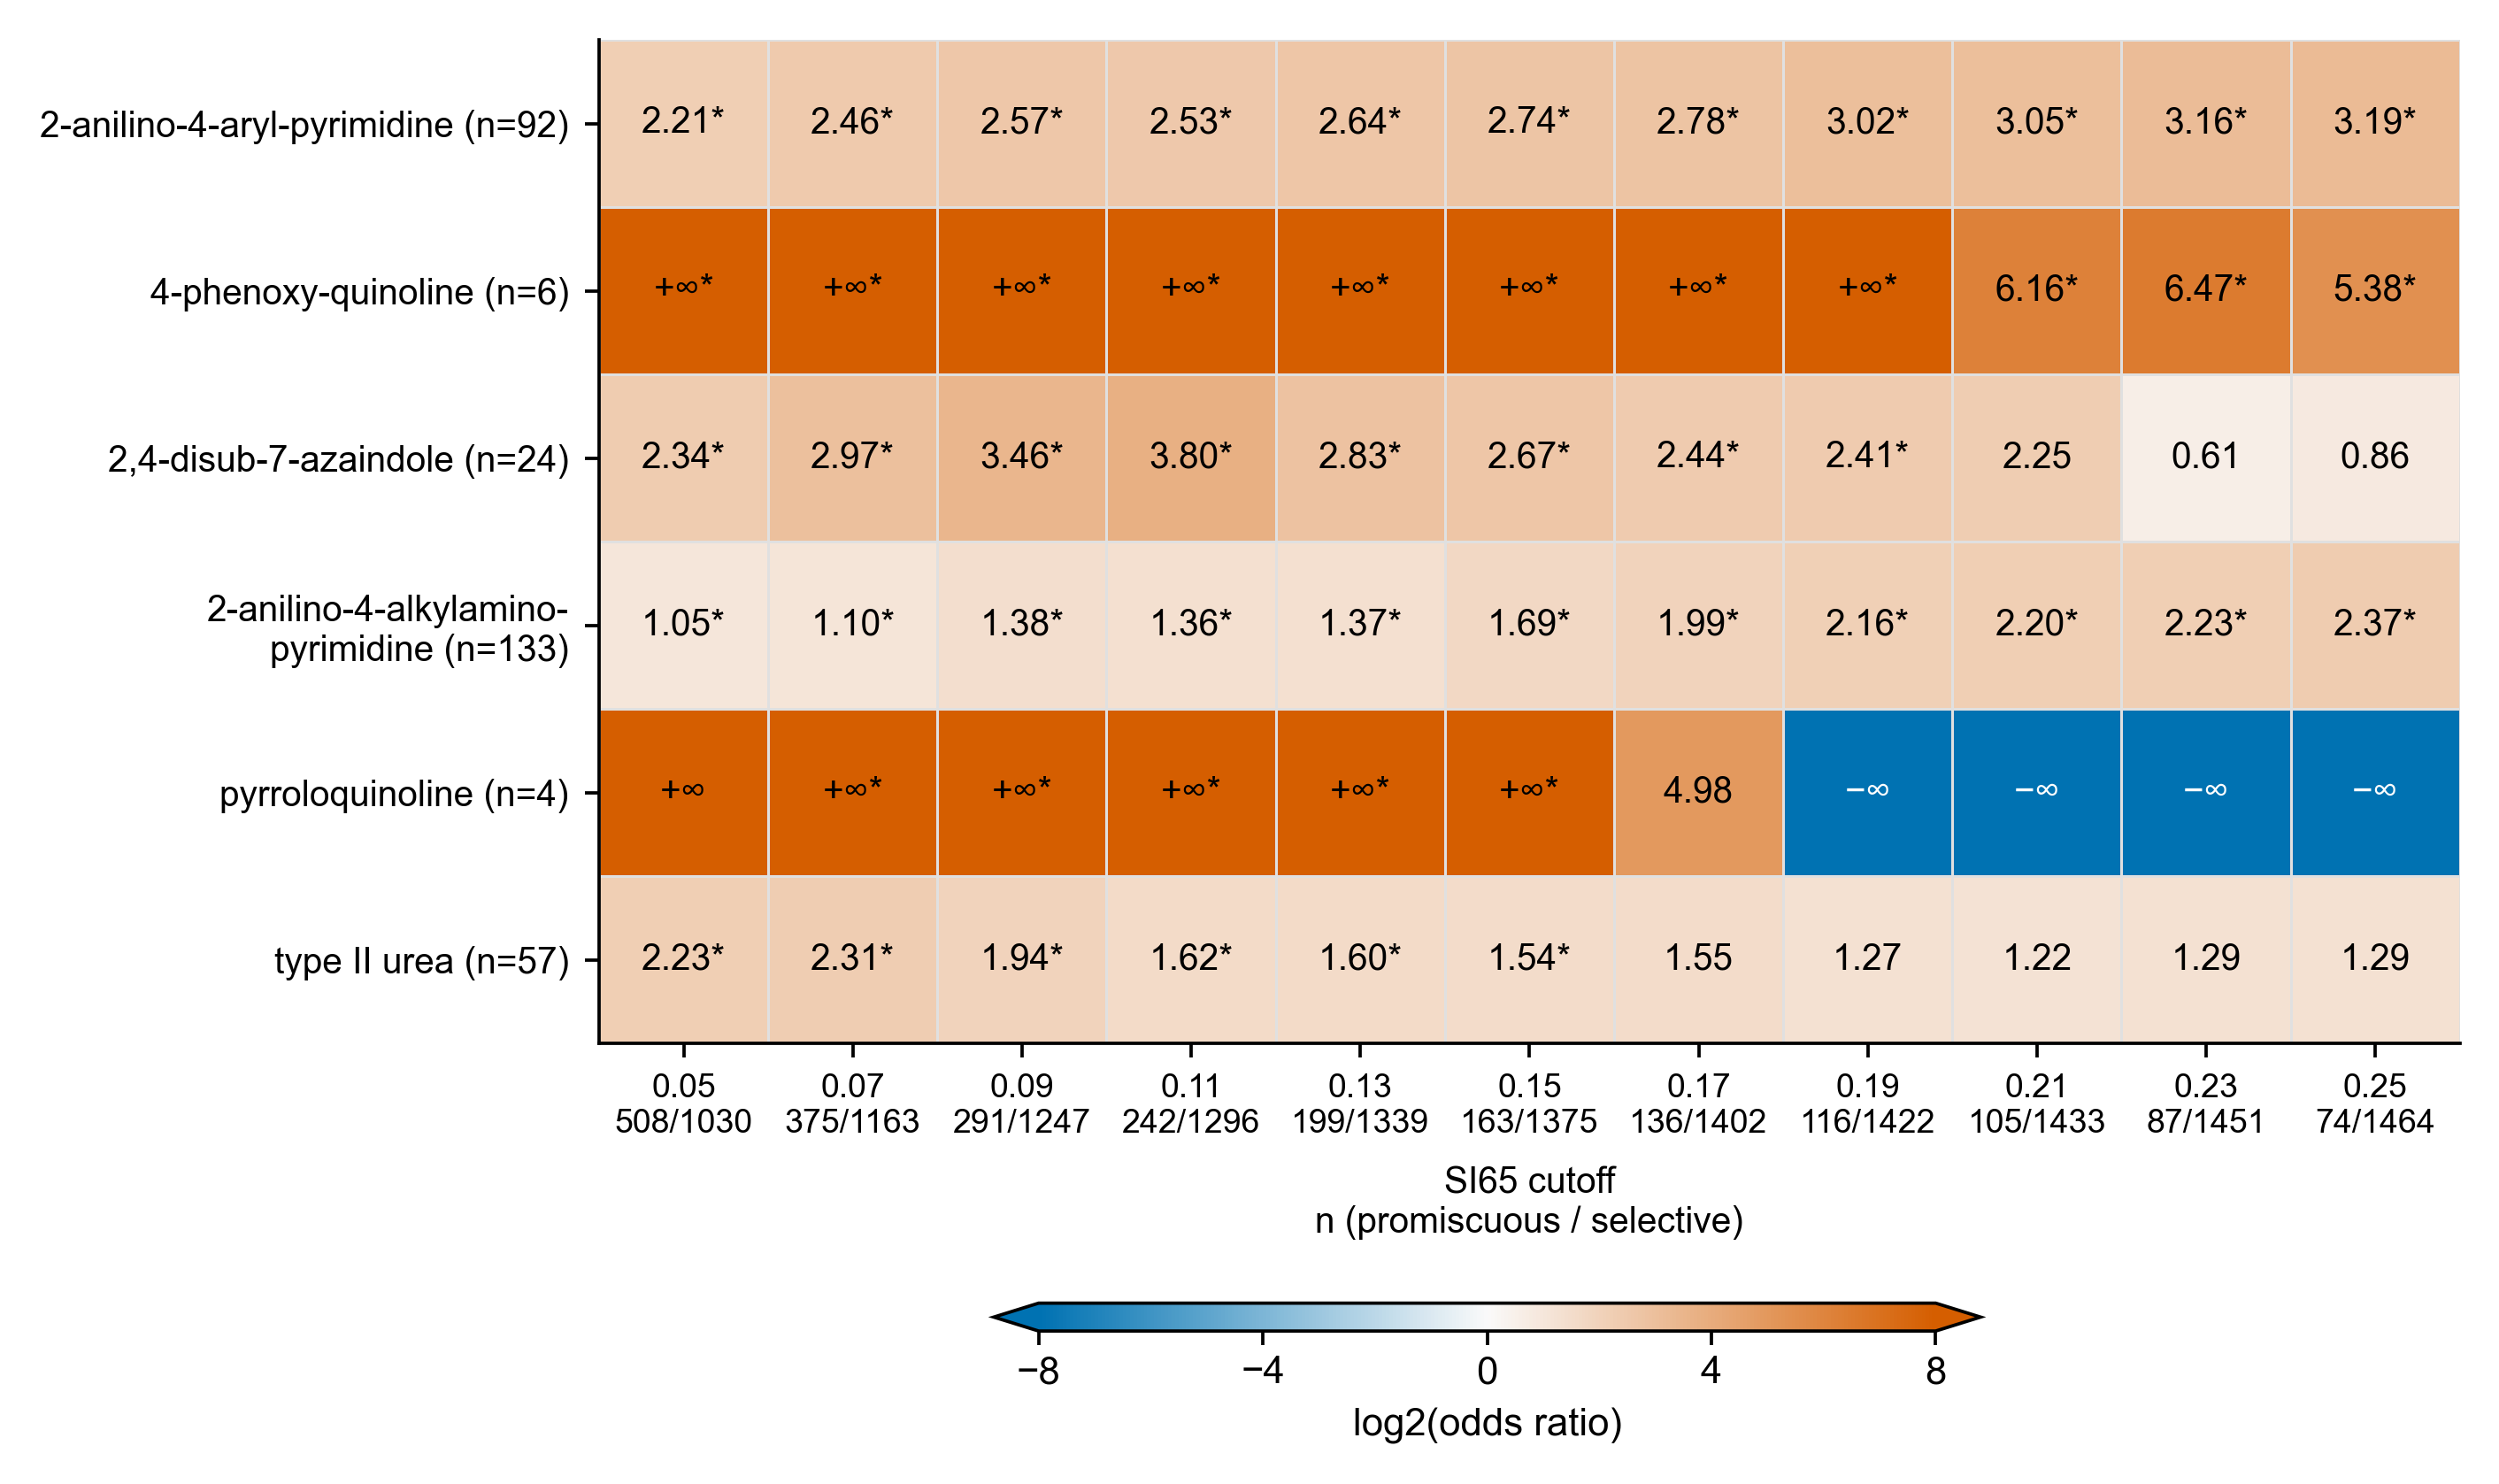

In [36]:
SENSITIVITY_DEFINITIONS = [
    ('SI50 Kneedle', 'SI50', None),
    ('SI65 Kneedle', 'SI65', None),
    ('SI90 Kneedle', 'SI90', None),
    ('SI65 0.100', 'SI65', 0.100),
    ('SI65 0.142', 'SI65', 0.142),
    ('SI65 0.200', 'SI65', 0.200),
]
definition_order = [item[0] for item in SENSITIVITY_DEFINITIONS]
reference_definition = 'SI65 Kneedle'
assert matches.index.equals(kips_df.index)
sensitivity_metrics = pd.DataFrame({
    f'SI{response}': (activity_matrix >= response).sum(axis=1) / len(kinase_cols)
    for response in (50, 65, 90)
}, index=kips_df.index)
np.testing.assert_allclose(sensitivity_metrics['SI65'], kips_df['SI65'])


def sensitivity_knee(values):
    ordered = np.sort(np.asarray(values, dtype=float))
    if not np.isfinite(ordered).all() or len(np.unique(ordered)) < 2:
        raise ValueError('Kneedle requires finite, non-constant SI values.')
    locator = KneeLocator(np.arange(len(ordered)), ordered, curve='convex',
                          direction='increasing', S=SI65_KNEE_SENSITIVITY)
    if locator.knee_y is None:
        raise ValueError('Kneedle did not identify a cutoff; inspect the SI distribution.')
    return float(locator.knee_y)


def sensitivity_enrichment(hit_matrix, labels):
    labels = labels.astype(bool)
    n_prom, n_sel = int(labels.sum()), int((~labels).sum())
    if min(n_prom, n_sel) == 0:
        raise ValueError('Both promiscuity classes are required for enrichment.')
    rows = []
    for name in hit_matrix.columns:
        hits = hit_matrix[name].astype(bool)
        a, b = int((hits & labels).sum()), int((hits & ~labels).sum())
        c, d = n_prom - a, n_sel - b
        odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative='greater')
        with np.errstate(divide='ignore', invalid='ignore'):
            log2_or = float(np.log2(odds_ratio))
        rows.append({
            'Scaffold_Name': name, 'Total_Hits': a + b,
            'Promiscuous_Hits_a': a, 'Selective_Hits_b': b,
            'Promiscuous_NonHits_c': c, 'Selective_NonHits_d': d,
            'Odds_Ratio': odds_ratio, 'P_value_raw': p_value,
            'Log2_Odds_Ratio': log2_or,
        })
    result = pd.DataFrame(rows)
    result['P_value_BH'] = multipletests(result['P_value_raw'], method='fdr_bh')[1]
    return result


threshold_rows, enrichment_frames, sensitivity_labels = [], [], {}
for definition, metric, manual_cutoff in SENSITIVITY_DEFINITIONS:
    threshold = sensitivity_knee(sensitivity_metrics[metric]) if manual_cutoff is None else manual_cutoff
    labels = sensitivity_metrics[metric].ge(threshold)
    sensitivity_labels[definition] = labels
    frame = sensitivity_enrichment(matches, labels)
    frame.insert(0, 'Definition', definition)
    frame['Metric'] = metric
    frame['Threshold'] = threshold
    enrichment_frames.append(frame)
    threshold_rows.append({
        'Definition': definition, 'Metric': metric, 'Threshold': threshold,
        'Threshold_Method': 'Kneedle' if manual_cutoff is None else 'Manual',
        'Response_Threshold': int(metric[2:]), 'Kinases_N': len(kinase_cols),
        'Compounds_N': len(labels), 'Promiscuous_N': int(labels.sum()),
        'Selective_N': int((~labels).sum()),
    })

np.testing.assert_array_equal(sensitivity_labels[reference_definition], kips_df['is_promiscuous'])
smarts_sensitivity_all = pd.concat(enrichment_frames, ignore_index=True)
smarts_lookup = smarts_df.drop_duplicates('Bin names').set_index('Bin names')['SMARTS']
smarts_sensitivity_all['SMARTS'] = smarts_sensitivity_all['Scaffold_Name'].map(smarts_lookup)
thresholds_df = pd.DataFrame(threshold_rows)
enriched_sets = {
    definition: set(frame.loc[frame['P_value_BH'].lt(P_VALUE_THRESHOLD), 'Scaffold_Name'])
    for definition, frame in smarts_sensitivity_all.groupby('Definition', sort=False)
}
baseline_set = enriched_sets[reference_definition]
baseline_labels = sensitivity_labels[reference_definition]
stability_rows = []
for definition in definition_order:
    selected = enriched_sets[definition]
    union = selected | baseline_set
    stability_rows.append({
        'Definition': definition,
        'Label_Agreement': float((sensitivity_labels[definition] == baseline_labels).mean()),
        'Enriched_Set_Jaccard': len(selected & baseline_set) / len(union) if union else np.nan,
        'Reference_Enrichment_Retained': len(selected & baseline_set) / len(baseline_set) if baseline_set else np.nan,
        'Significant_Scaffolds_N': len(selected),
    })
stability_df = pd.DataFrame(stability_rows)
thresholds_df = thresholds_df.merge(stability_df, on='Definition', validate='one_to_one')

smarts_sensitivity_all.to_csv(os.path.join(SUPPORTING_DIR, 'SMARTS_Sensitivity_Long.csv'), index=False)
thresholds_df.to_csv(os.path.join(SUPPORTING_DIR, 'SMARTS_Sensitivity_Thresholds.csv'), index=False)
smarts_sensitivity_wide = smarts_sensitivity_all.pivot(
    index='Scaffold_Name', columns='Definition',
    values=['Log2_Odds_Ratio', 'Odds_Ratio', 'P_value_BH']
)
smarts_sensitivity_wide.columns = [f'{definition}__{value}' for value, definition in smarts_sensitivity_wide.columns]
smarts_sensitivity_wide.to_csv(os.path.join(SUPPORTING_DIR, 'SMARTS_Sensitivity_Wide.csv'))
label_export = kips_df[['Compound ID', 'InChI_Key']].copy()
for definition, labels in sensitivity_labels.items():
    label_export[definition] = labels.astype(int)
label_export.to_csv(os.path.join(SUPPORTING_DIR, 'SMARTS_Sensitivity_Compound_Labels.csv'), index=False)

figure5_rows = sig_prom.sort_values('-log10_P_BH', ascending=True)
scaffold_order = figure5_rows['Scaffold_Name'].tolist()[::-1]
if not scaffold_order:
    raise ValueError('Figure 5 contains no significantly enriched SMARTS patterns.')
baseline_results = smarts_sensitivity_all.loc[
    smarts_sensitivity_all['Definition'].eq(reference_definition)
].set_index('Scaffold_Name')
np.testing.assert_allclose(
    baseline_results.loc[scaffold_order, 'P_value_BH'],
    figure5_rows.set_index('Scaffold_Name').loc[scaffold_order, 'P_value_BH'],
    rtol=1e-10, atol=1e-14,
)

metric_definitions = ['SI50 Kneedle', 'SI65 Kneedle', 'SI90 Kneedle']
metric_effects = smarts_sensitivity_all.pivot(
    index='Scaffold_Name', columns='Definition', values='Log2_Odds_Ratio'
).reindex(index=scaffold_order, columns=metric_definitions)
metric_q = smarts_sensitivity_all.pivot(
    index='Scaffold_Name', columns='Definition', values='P_value_BH'
).reindex(index=scaffold_order, columns=metric_definitions)

si65_cutoffs = np.arange(5, 26, dtype=float) / 100
si65_cutoff_labels = {cutoff: sensitivity_metrics['SI65'].ge(cutoff) for cutoff in si65_cutoffs}
sweep_frames = []
for cutoff in si65_cutoffs:
    labels = si65_cutoff_labels[cutoff]
    frame = sensitivity_enrichment(matches, labels)
    frame.insert(0, 'SI65_Cutoff', cutoff)
    frame['Compounds_N'] = len(labels)
    frame['Promiscuous_N'] = int(labels.sum())
    frame['Selective_N'] = int((~labels).sum())
    frame['SMARTS'] = frame['Scaffold_Name'].map(smarts_lookup)
    frame['Figure5_Enriched'] = frame['Scaffold_Name'].isin(scaffold_order)
    sweep_frames.append(frame)
smarts_cutoff_sweep = pd.concat(sweep_frames, ignore_index=True)
smarts_cutoff_sweep.to_csv(
    os.path.join(SUPPORTING_DIR, 'SMARTS_SI65_Cutoff_Sweep.csv'), index=False)
sweep_effects_all = smarts_cutoff_sweep.pivot(
    index='Scaffold_Name', columns='SI65_Cutoff', values='Log2_Odds_Ratio')
sweep_q_all = smarts_cutoff_sweep.pivot(
    index='Scaffold_Name', columns='SI65_Cutoff', values='P_value_BH')
cutoff_counts = smarts_cutoff_sweep.groupby('SI65_Cutoff')[['Promiscuous_N', 'Selective_N']].first()
main_cutoffs = np.arange(10, 21, 2, dtype=float) / 100
wide_cutoffs = np.arange(5, 26, 2, dtype=float) / 100
# Follow only the initially enriched patterns at every cutoff.
wide_order = scaffold_order
hit_counts = baseline_results['Total_Hits']

displayed_values = np.concatenate([
    metric_effects.to_numpy().ravel(),
    sweep_effects_all.loc[scaffold_order, main_cutoffs].to_numpy().ravel(),
    sweep_effects_all.loc[wide_order, wide_cutoffs].to_numpy().ravel(),
])
finite_values = displayed_values[np.isfinite(displayed_values)]
effect_bound = max(2., float(2 * np.ceil(np.abs(finite_values).max() / 2))) if finite_values.size else 2.
effect_cmap = LinearSegmentedColormap.from_list('smarts_log2_odds', [MAIN_COLORS['blue'], '#fafafa', MAIN_COLORS['vermillion']])
effect_cmap.set_bad('#dedede')


def _draw_smarts_effect_heatmap(ax, values, q_frame, row_names, show_y=True):
    color_values = values.replace({np.inf: effect_bound, -np.inf: -effect_bound})
    mesh = ax.pcolormesh(np.ma.masked_invalid(color_values.to_numpy()), cmap=effect_cmap,
                         vmin=-effect_bound, vmax=effect_bound, edgecolors='#e0e0e0',
                         linewidth=.45, rasterized=False)
    ax.set_ylim(len(row_names), 0)
    ax.set_xlim(0, len(values.columns))
    ax.set_yticks(np.arange(len(row_names)) + .5)
    ax.tick_params(length=2.5, width=.6, pad=3, labelsize=7)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(.6)
    if show_y:
        ax.set_yticklabels([
            textwrap.fill(str(name).replace('\x97', '-'), 29) + f' (n={int(hit_counts[name])})'
            for name in row_names], fontsize=6.5)
    else:
        ax.tick_params(axis='y', left=False, labelleft=False)
    for row in range(len(row_names)):
        for col in range(len(values.columns)):
            value = values.iloc[row, col]
            label = ('NA' if np.isnan(value) else '+∞' if np.isposinf(value)
                     else '−∞' if np.isneginf(value) else f'{value:.2f}')
            if q_frame.iloc[row, col] < P_VALUE_THRESHOLD:
                label += '*'
            rgba = effect_cmap((np.clip(value, -effect_bound, effect_bound) + effect_bound) / (2 * effect_bound))
            # Choose black or white from the actual background luminance.
            rgb = np.array(rgba[:3])
            luminance = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4) @ [.2126, .7152, .0722]
            text_color = 'black' if luminance > .179 else 'white'
            ax.text(col + .5, row + .5, label, ha='center', va='center',
                    fontsize=6.5, color=text_color)
    return mesh


def _smarts_effect_colorbar(fig, mesh, rect):
    cax = fig.add_axes(rect)
    bar = fig.colorbar(mesh, cax=cax, orientation='horizontal', extend='both',
                       ticks=[-effect_bound, -effect_bound / 2, 0, effect_bound / 2, effect_bound])
    bar.set_label('log2(odds ratio)', fontsize=7, labelpad=3)
    bar.ax.tick_params(labelsize=7, length=2.5, width=.6, pad=2)
    bar.outline.set_linewidth(.6)
    bar.solids.set_rasterized(False)
    return bar


# Share physical row spacing and margins with the BRICS figures.
metric_heatmap_row_height = 2.65 * .67 / len(scaffold_order)
metric_bottom_margin = 2.65 * .30
metric_top_margin = 2.65 * .03
# Extra space (inches) between the sweep x-axis label and colorbar in both figures.
sweep_colorbar_gap = .18
sweep_bottom_margin = 3.5 * .23 + sweep_colorbar_gap
sweep_top_margin = 3.5 * .05
sweep_colorbar_bottom = 3.5 * .075
sweep_colorbar_height = 3.5 * .020


with plt.rc_context({'savefig.bbox': None}):
    metric_plot_height = metric_heatmap_row_height * len(scaffold_order)
    metric_height = metric_bottom_margin + metric_plot_height + metric_top_margin
    fig = plt.figure(figsize=(3.54, metric_height))
    ax_metric = fig.add_axes([.43, metric_bottom_margin / metric_height,
                              .55, metric_plot_height / metric_height])
    metric_mesh = _draw_smarts_effect_heatmap(ax_metric, metric_effects, metric_q, scaffold_order)
    metric_counts = thresholds_df.set_index('Definition').loc[metric_definitions]
    ax_metric.set_xticks(np.arange(3) + .5, [
        f"{row['Metric']}\n≥ {row['Threshold']:.3f}\n{int(row['Promiscuous_N'])}/{int(row['Selective_N'])}"
        for _, row in metric_counts.iterrows()], fontsize=6.5)
    ax_metric.get_xticklabels()[1].set_fontweight('bold')
    ax_metric.set_xlabel('Kneedle cutoff\nn (promiscuous / selective)', labelpad=5, fontsize=6.5)
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, f'Supplementary_Figure_3_SMARTS_Threshold_Sensitivity.{ext}'))
    plt.show()

    wide_height = max(3.5, .245 * len(wide_order) + 1.1) + sweep_colorbar_gap
    fig_wide = plt.figure(figsize=(7.08, wide_height))
    ax_wide = fig_wide.add_axes([.32, sweep_bottom_margin / wide_height, .66,
                                (wide_height - sweep_bottom_margin - sweep_top_margin) / wide_height])
    wide_mesh = _draw_smarts_effect_heatmap(ax_wide,
        sweep_effects_all.loc[wide_order, wide_cutoffs],
        sweep_q_all.loc[wide_order, wide_cutoffs], wide_order)
    ax_wide.set_xticks(np.arange(len(wide_cutoffs)) + .5, [
        f"{c:.2f}\n{int(cutoff_counts.loc[c, 'Promiscuous_N'])}/{int(cutoff_counts.loc[c, 'Selective_N'])}"
        for c in wide_cutoffs], fontsize=6)
    ax_wide.set_xlabel('SI65 cutoff\nn (promiscuous / selective)', fontsize=6.5, labelpad=5)
    _smarts_effect_colorbar(fig_wide, wide_mesh,
        [.46, sweep_colorbar_bottom / wide_height, .35, sweep_colorbar_height / wide_height])
    for ext in ('pdf', 'png'):
        fig_wide.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, f'Supplementary_Figure_4_SMARTS_Cutoff_Sensitivity.{ext}'))
    plt.show()


# SMARTS Promiscuity Correlation

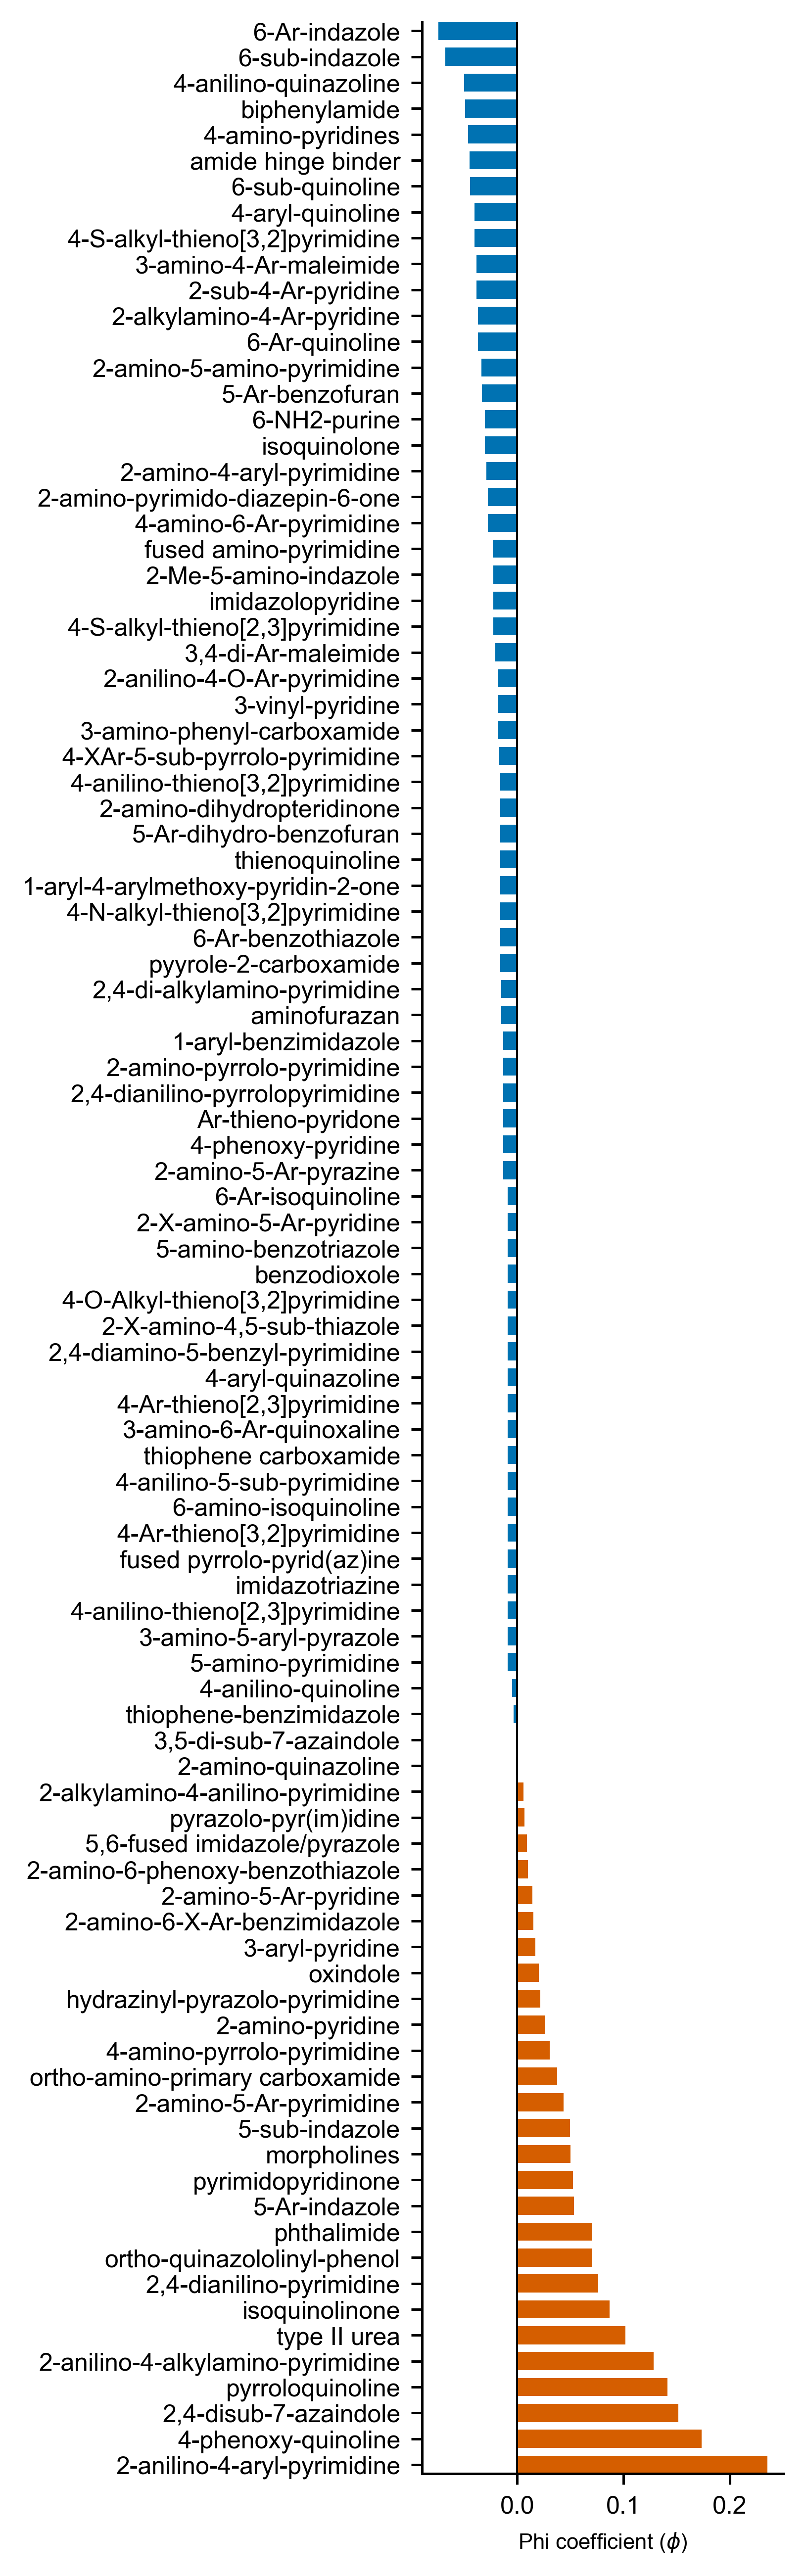

In [37]:
def calculate_phi_association(hits, labels):
    x, y = hits.astype(int), labels.astype(int)
    phi, _ = pearsonr(x, y)
    a = int(((x == 1) & (y == 1)).sum())
    b = int(x.sum()) - a
    c = int(y.sum()) - a
    d = len(x) - a - b - c
    _, p_value = fisher_exact([[a, b], [c, d]], alternative='greater')
    return phi, p_value


results = []
for col in matches.columns:
    x = matches[col].astype(int)
    if x.nunique() < 2:
        continue
    r, p = calculate_phi_association(x, kips_df['is_promiscuous'])
    results.append({'Scaffold': col.replace('\x97', '-').replace('\u2014', '-'),
                    'Total_Occurrences': int(x.sum()),
                    'Promiscuous_Hits': int((x.astype(bool) & kips_df['is_promiscuous']).sum()),
                    'phi': r, 'p_value': p})

corr_df = pd.DataFrame(results).sort_values('phi', ascending=False)
corr_df['p_value_BH'] = multipletests(corr_df['p_value'], method='fdr_bh')[1]
corr_df[['Scaffold', 'phi']].rename(columns={'Scaffold': 'Scaffold Name', 'phi': 'Phi'}).to_csv(
    os.path.join(DATA_TABLES_DIR, 'Supplementary_Data_Table_4_SMARTS_Phi.csv'), index=False, float_format='%.3f')

fig, ax = plt.subplots(figsize=(3.54, len(corr_df) * 0.12))
fig.patch.set_facecolor('white')
colors = [MAIN_COLORS['vermillion'] if r > 0 else MAIN_COLORS['blue'] for r in corr_df['phi']]
ax.barh(corr_df['Scaffold'], corr_df['phi'], color=colors, edgecolor='none', height=0.7)
ax.margins(y=0)
ax.axvline(0, color='black', linewidth=0.6)
ax.set_xlabel('Phi coefficient ($\phi$)', fontsize=7)
ax.tick_params(axis='both', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(pad=0.1)  # minimal padding
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_6_SMARTS_Phi_Correlation.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_6_SMARTS_Phi_Correlation.png'), bbox_inches='tight')
plt.show()

# BRICS Enrichment

In [38]:
fragments = defaultdict(lambda: {
    'promiscuous_hits': 0, 'non_promiscuous_hits': 0,
    'total_occurrences': 0, 'fragment_mol': None
})

brics_compound_fragments = []
for mol, is_prom in tqdm(
    zip(kips_df['mol_std'], kips_df['is_promiscuous']),
    desc="BRICS fragmentation", total=len(kips_df)
):
    frags = list(BRICS.BRICSDecompose(mol, returnMols=True, minFragmentSize=2)) or [mol]
    seen  = set()
    for frag in frags:
        for atom in frag.GetAtoms(): atom.SetAtomMapNum(0)
        smi = Chem.MolToSmiles(frag, isomericSmiles=False, canonical=True)
        if fragments[smi]['fragment_mol'] is None:
            fragments[smi]['fragment_mol'] = frag
        seen.add(smi)
    brics_compound_fragments.append(seen)
    for smi in seen:
        fragments[smi]['total_occurrences'] += 1
        fragments[smi]['promiscuous_hits' if is_prom else 'non_promiscuous_hits'] += 1

print(f"{len(fragments)} unique BRICS fragments")

BRICS fragmentation: 100%|██████████| 1538/1538 [00:10<00:00, 145.45it/s]

1722 unique BRICS fragments


In [39]:
# Fisher's exact test enrichment
rows = []
for smi, d in tqdm(fragments.items(), desc="Enrichment", leave=False):
    n = d['total_occurrences']
    if n == 0 or n == len(kips_df): continue
    a, b = d['promiscuous_hits'], d['non_promiscuous_hits']
    stats = calculate_enrichment_stats(a, b, n_promiscuous - a, n_selective - b)
    rows.append({'Fragment_SMILES': smi, 'Total_Occurrences': n,
                 'Promiscuous_Hits': a, 'Selective_Hits': b,
                 'Fragment': d['fragment_mol'], **stats})

prom_brics_df = pd.DataFrame(rows)
prom_brics_df['P_value_BH'] = multipletests(prom_brics_df['P_value_raw'], alpha=0.05, method='fdr_bh')[1]
prom_brics_df['-log10_P_BH'] = -np.log10(prom_brics_df['P_value_BH'].clip(1e-100))
prom_brics_df.sort_values('P_value_BH', ascending=True, inplace=True)

pd.DataFrame({
    'Fragment SMILES': prom_brics_df['Fragment_SMILES'],
    'Total Occurrences': prom_brics_df['Total_Occurrences'],
    'Promiscuous Hits': prom_brics_df['Promiscuous_Hits'],
    'Selective Hits': prom_brics_df['Selective_Hits'],
    'Odds Ratio': prom_brics_df['Odds_Ratio'].map('{:.2f}'.format),
    'P value (Raw)': prom_brics_df['P_value_raw'].map('{:.2E}'.format),
    'P value (BH-corrected)': prom_brics_df['P_value_BH'].map('{:.2E}'.format),
    'log(P value (BH-corrected))': (prom_brics_df['-log10_P_BH'] + 0.0).map('{:.2f}'.format),
}).to_csv(os.path.join(DATA_TABLES_DIR, 'Supplementary_Data_Table_5_BRICS_Enrichment.csv'), index=False)

n_sig = (prom_brics_df['P_value_BH'] < P_VALUE_THRESHOLD).sum()
print(f"{n_sig} fragments significant after BH correction")

23 fragments significant after BH correction


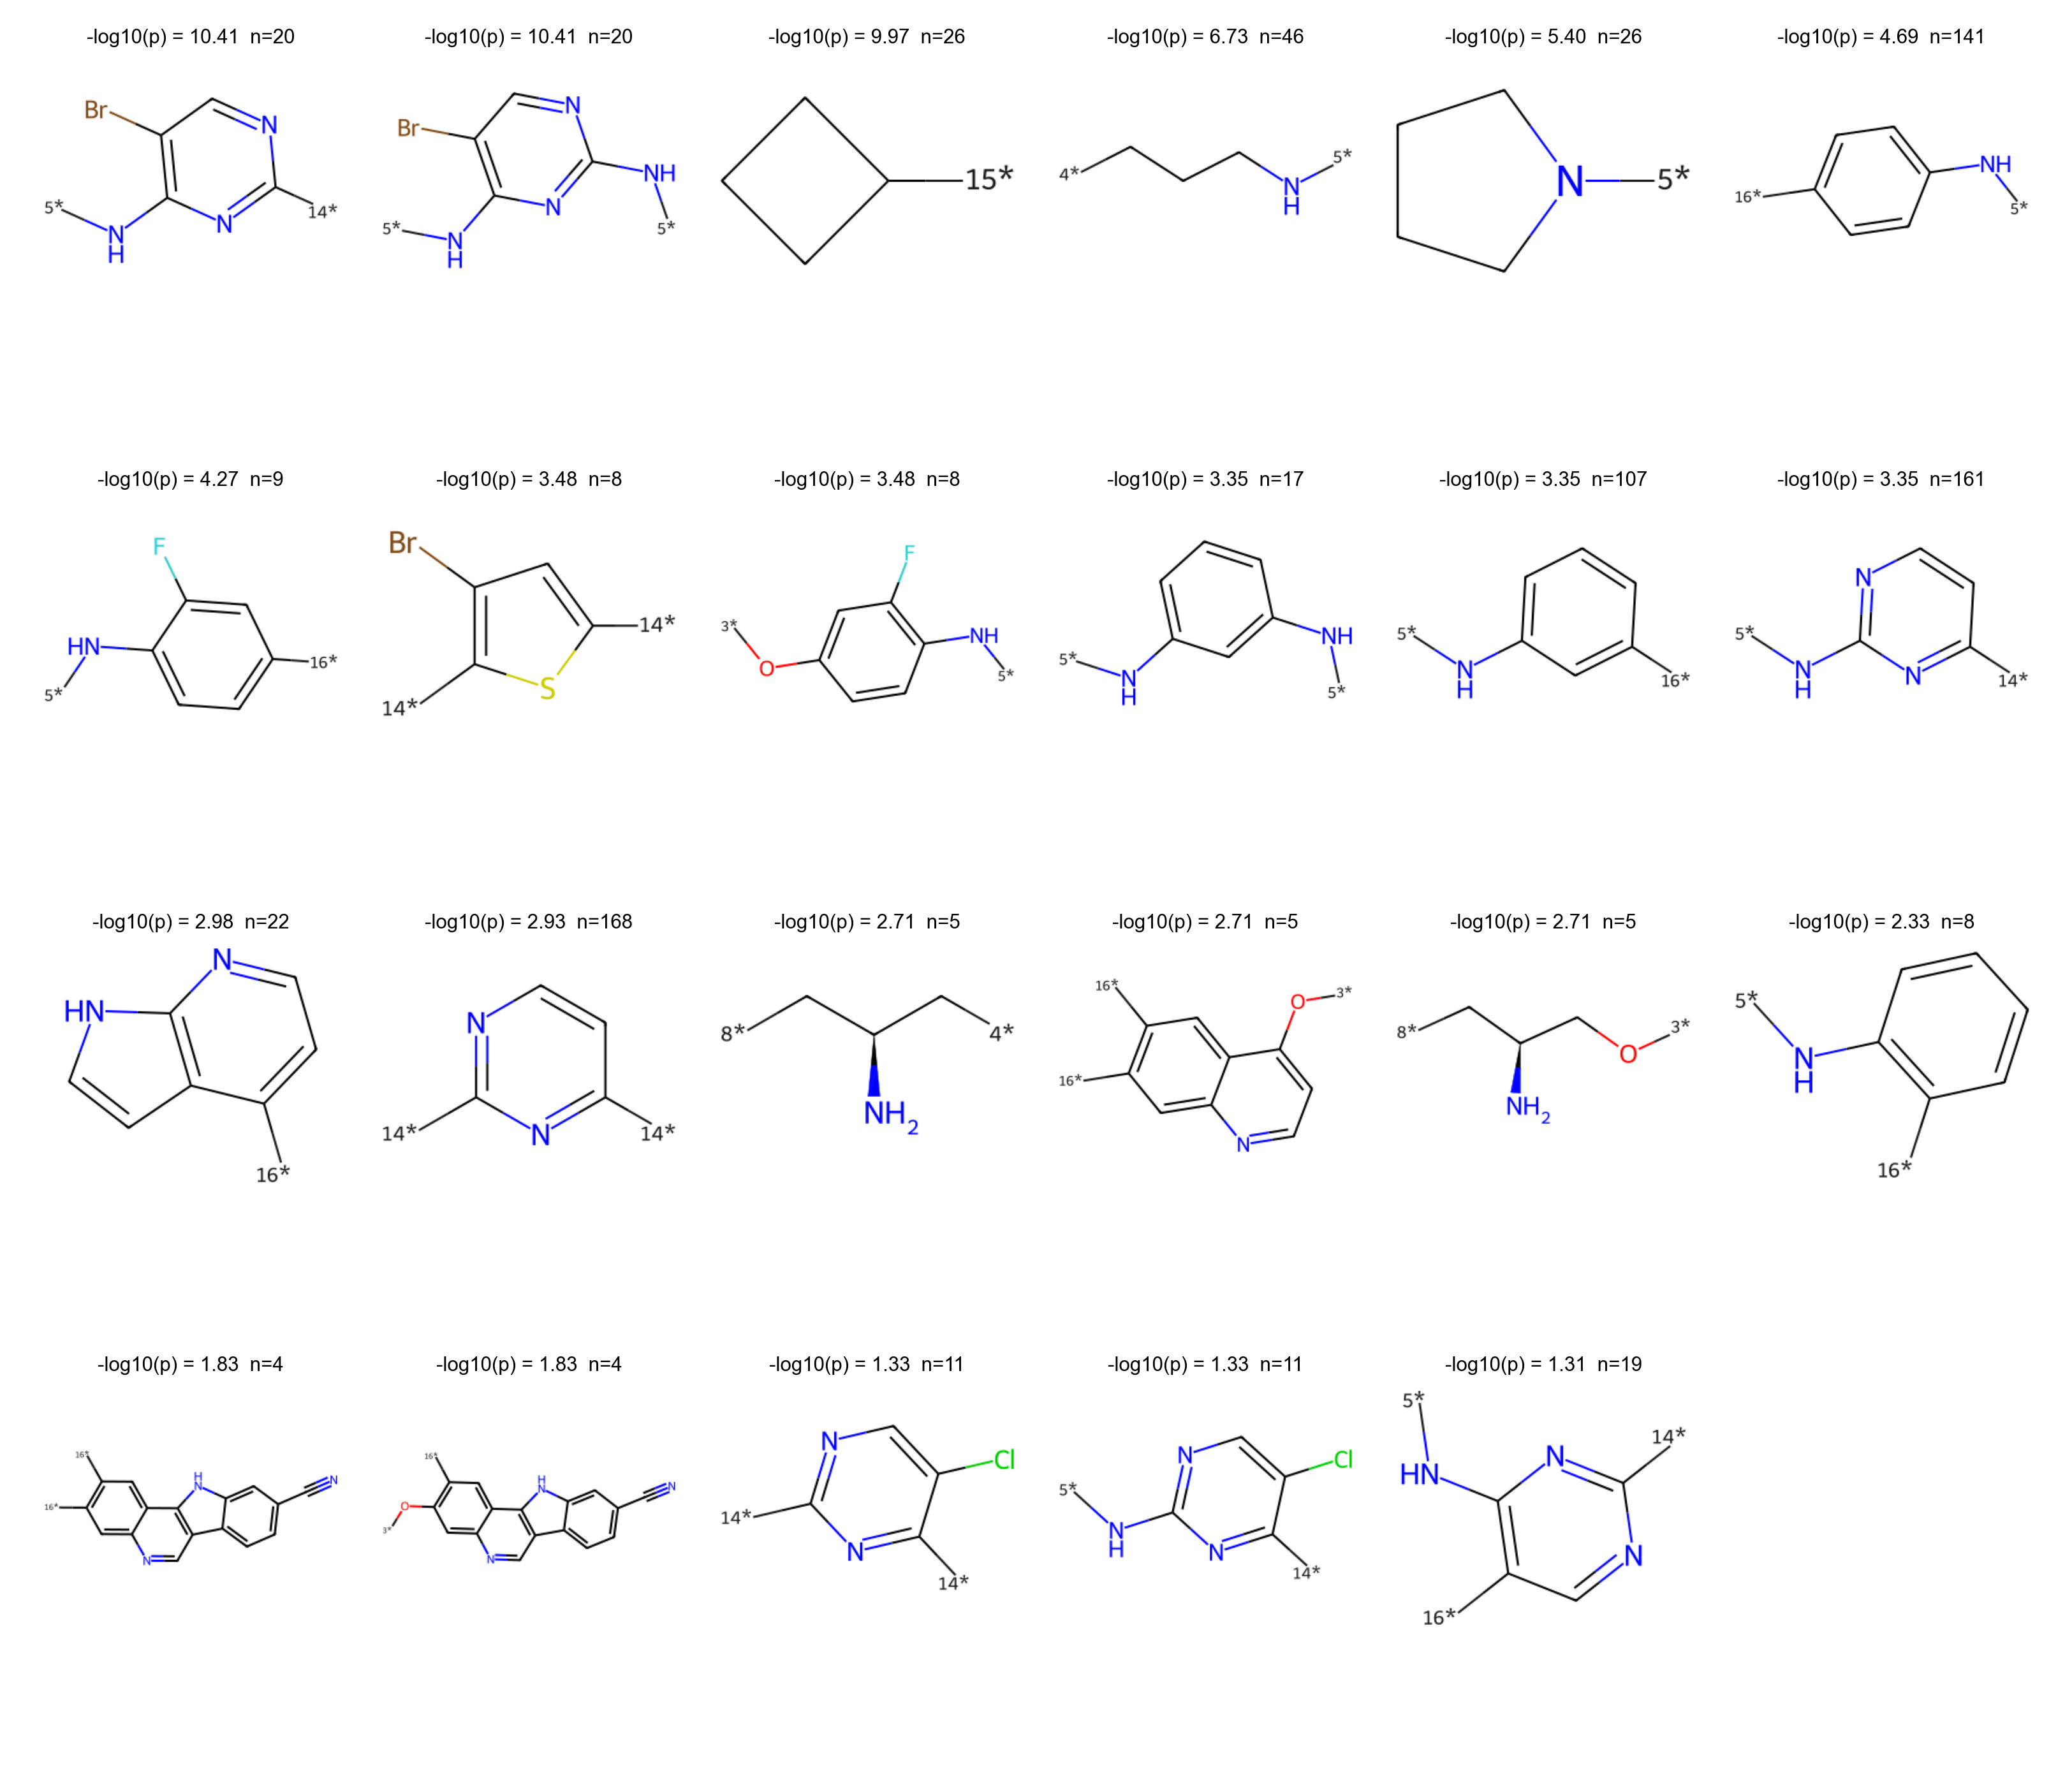

In [40]:
# Visualize enriched fragments
sig   = prom_brics_df[prom_brics_df['P_value_BH'] < P_VALUE_THRESHOLD]
mols  = sig['Fragment'].tolist()
legs  = [f"-log10(p) = {r['-log10_P_BH']:.2f}  n={r['Total_Occurrences']}"
         for _, r in sig.iterrows()]

n_cols = 6
n_rows = max(1, (len(mols) + n_cols - 1) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.08, n_rows * 240 / 150))
fig.patch.set_facecolor('white')
axes = np.array(axes).reshape(n_rows, n_cols)

for i, (mol, leg) in enumerate(zip(mols, legs)):
    ax = axes[i // n_cols, i % n_cols]
    if mol is not None:
        ax.imshow(np.array(Draw.MolToImage(mol, size=(300, 240))))
    ax.axis('off')
    ax.set_title(leg, fontsize=5, pad=2)

for j in range(len(mols), n_rows * n_cols):
    axes[j // n_cols, j % n_cols].axis('off')

plt.tight_layout(pad=0.3, w_pad=0.5, h_pad=0.5)
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_7_BRICS_Enrichment.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_7_BRICS_Enrichment.png'), bbox_inches='tight')
plt.show()

# BRICS Promiscuity Correlation

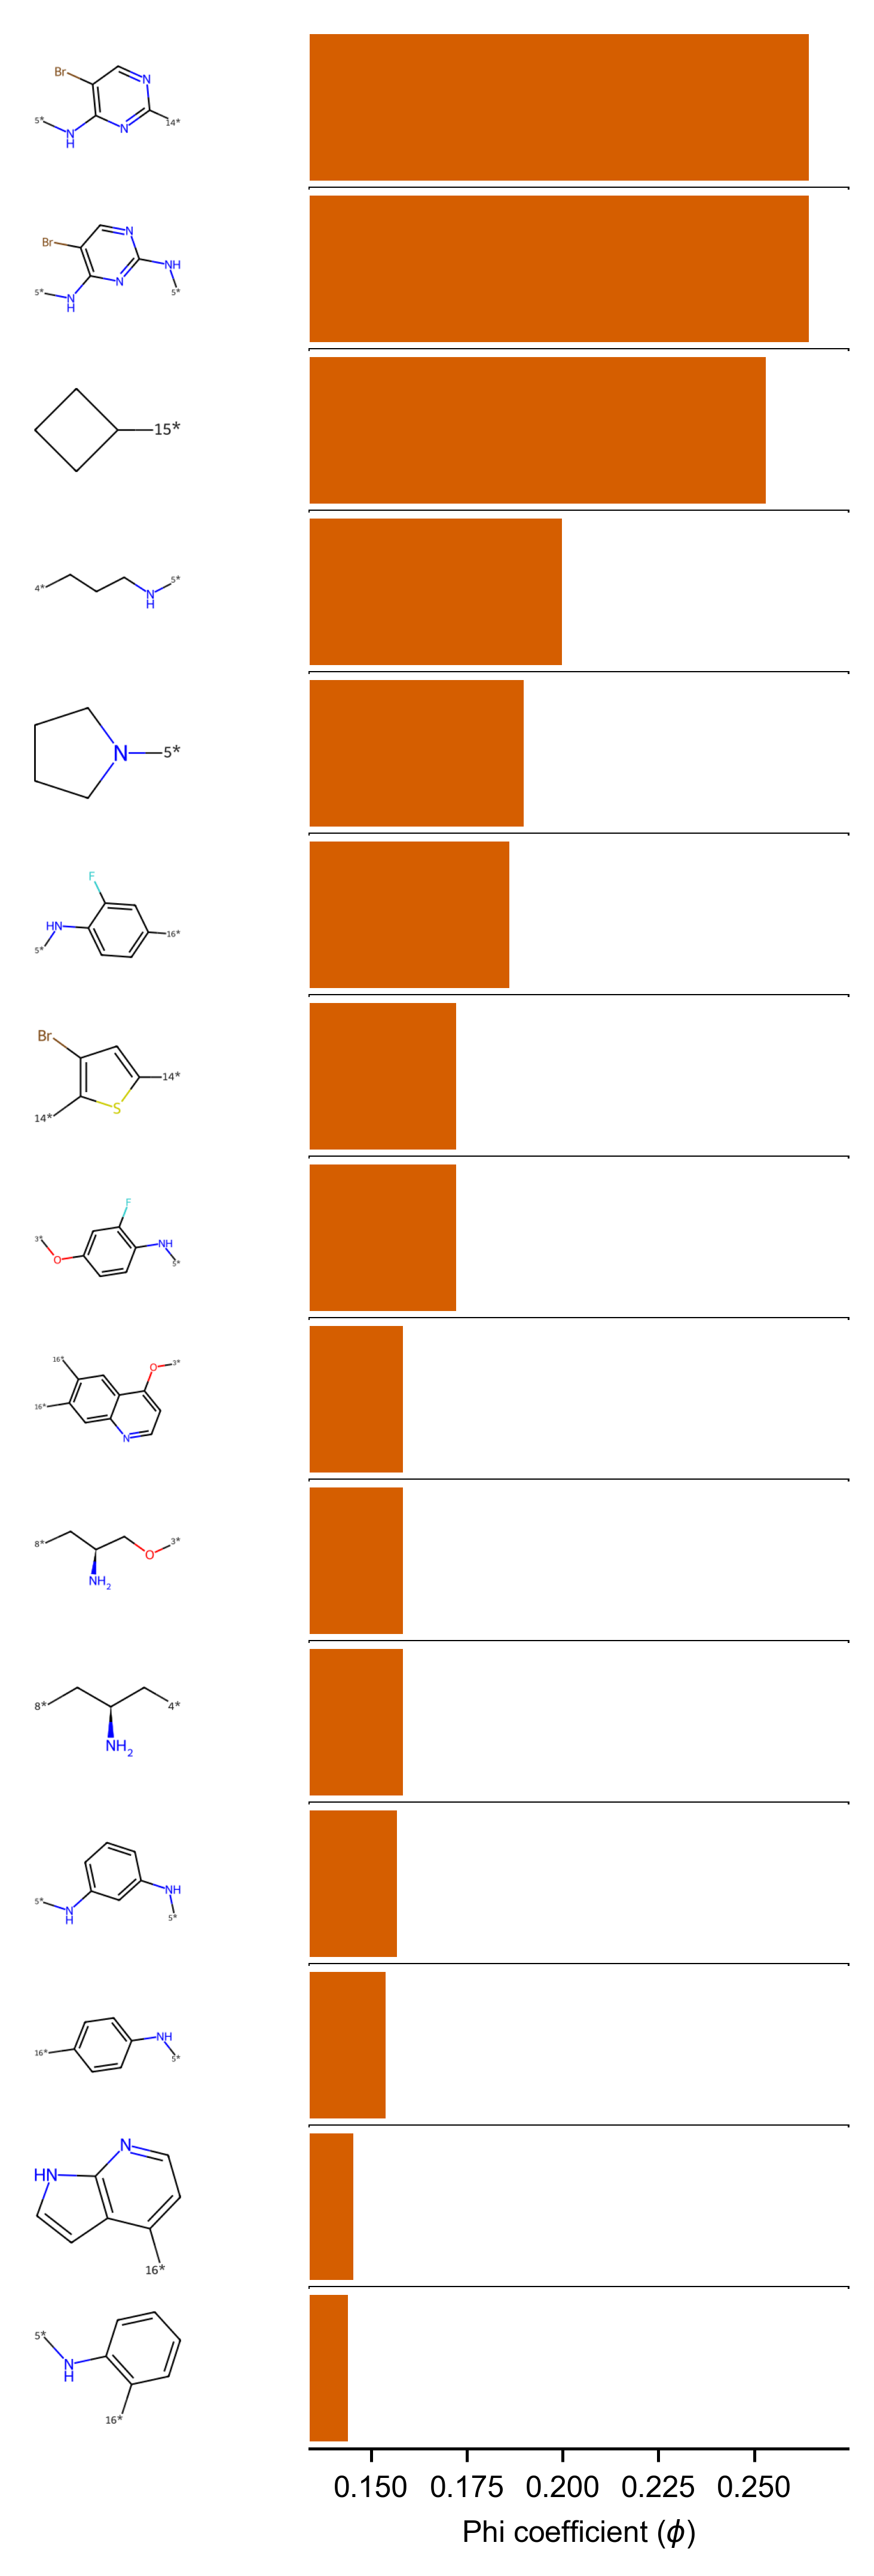

In [41]:
brics_corr_df = prom_brics_df.copy()
brics_phi_stats = [
    calculate_phi_association(
        pd.Series([smi in fragment_set for fragment_set in brics_compound_fragments],
                  index=kips_df.index, dtype=int),
        kips_df['is_promiscuous'],
    )
    for smi in brics_corr_df['Fragment_SMILES']
]
brics_corr_df[['phi', 'P_value_raw']] = pd.DataFrame(
    brics_phi_stats, index=brics_corr_df.index, columns=['phi', 'P_value_raw'])
brics_corr_df['P_value_BH'] = multipletests(brics_corr_df['P_value_raw'], method='fdr_bh')[1]

brics_corr_df[['Fragment_SMILES', 'phi']].rename(columns={'Fragment_SMILES': 'Fragment SMILES', 'phi': 'Phi'}).to_csv(
    os.path.join(DATA_TABLES_DIR, 'Supplementary_Data_Table_6_BRICS_Phi.csv'), index=False, float_format='%.3f')

plot_df = brics_corr_df.sort_values('phi', ascending=False).head(15).reset_index(drop=True)

row_h   = 0.6 
img_w   = 1.5  
bar_w   = 2.0  
fig_h   = len(plot_df) * row_h
fig_w   = img_w + bar_w

fig = plt.figure(figsize=(fig_w, fig_h))
fig.patch.set_facecolor('white')

for i, row in plot_df.iterrows():
    ax_mol = fig.add_axes([0, 1 - (i + 1) / len(plot_df),img_w / fig_w, row_h / fig_h])
    mol = row['Fragment']
    if mol is not None:
        ax_mol.imshow(np.array(Draw.MolToImage(mol, size=(200, 200))))
    ax_mol.axis('off')

    ax_bar = fig.add_axes([img_w / fig_w, 1 - (i + 1) / len(plot_df),bar_w / fig_w, row_h / fig_h])
    color = MAIN_COLORS['vermillion'] if row['phi'] > 0 else MAIN_COLORS['blue']
    ax_bar.barh(0, row['phi'], color=color, height=0.6)
    ax_bar.axvline(0, color='black', linewidth=0.4)
    ax_bar.set_xlim(plot_df['phi'].min() - 0.01, plot_df['phi'].max() + 0.01)
    ax_bar.set_yticks([])
    ax_bar.spines[['top', 'right', 'left']].set_visible(False)
    if i == len(plot_df) - 1:
        ax_bar.set_xlabel('Phi coefficient ($\phi$)', fontsize=8)
        ax_bar.tick_params(axis='x', labelsize=8)
    else:
        ax_bar.tick_params(axis='x', labelbottom=False, length=0)

plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_10_BRICS_Phi_Correlation.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, 'Supplementary_Figure_10_BRICS_Phi_Correlation.png'), bbox_inches='tight')
plt.show()

# BRICS enrichment sensitivity across SI thresholds

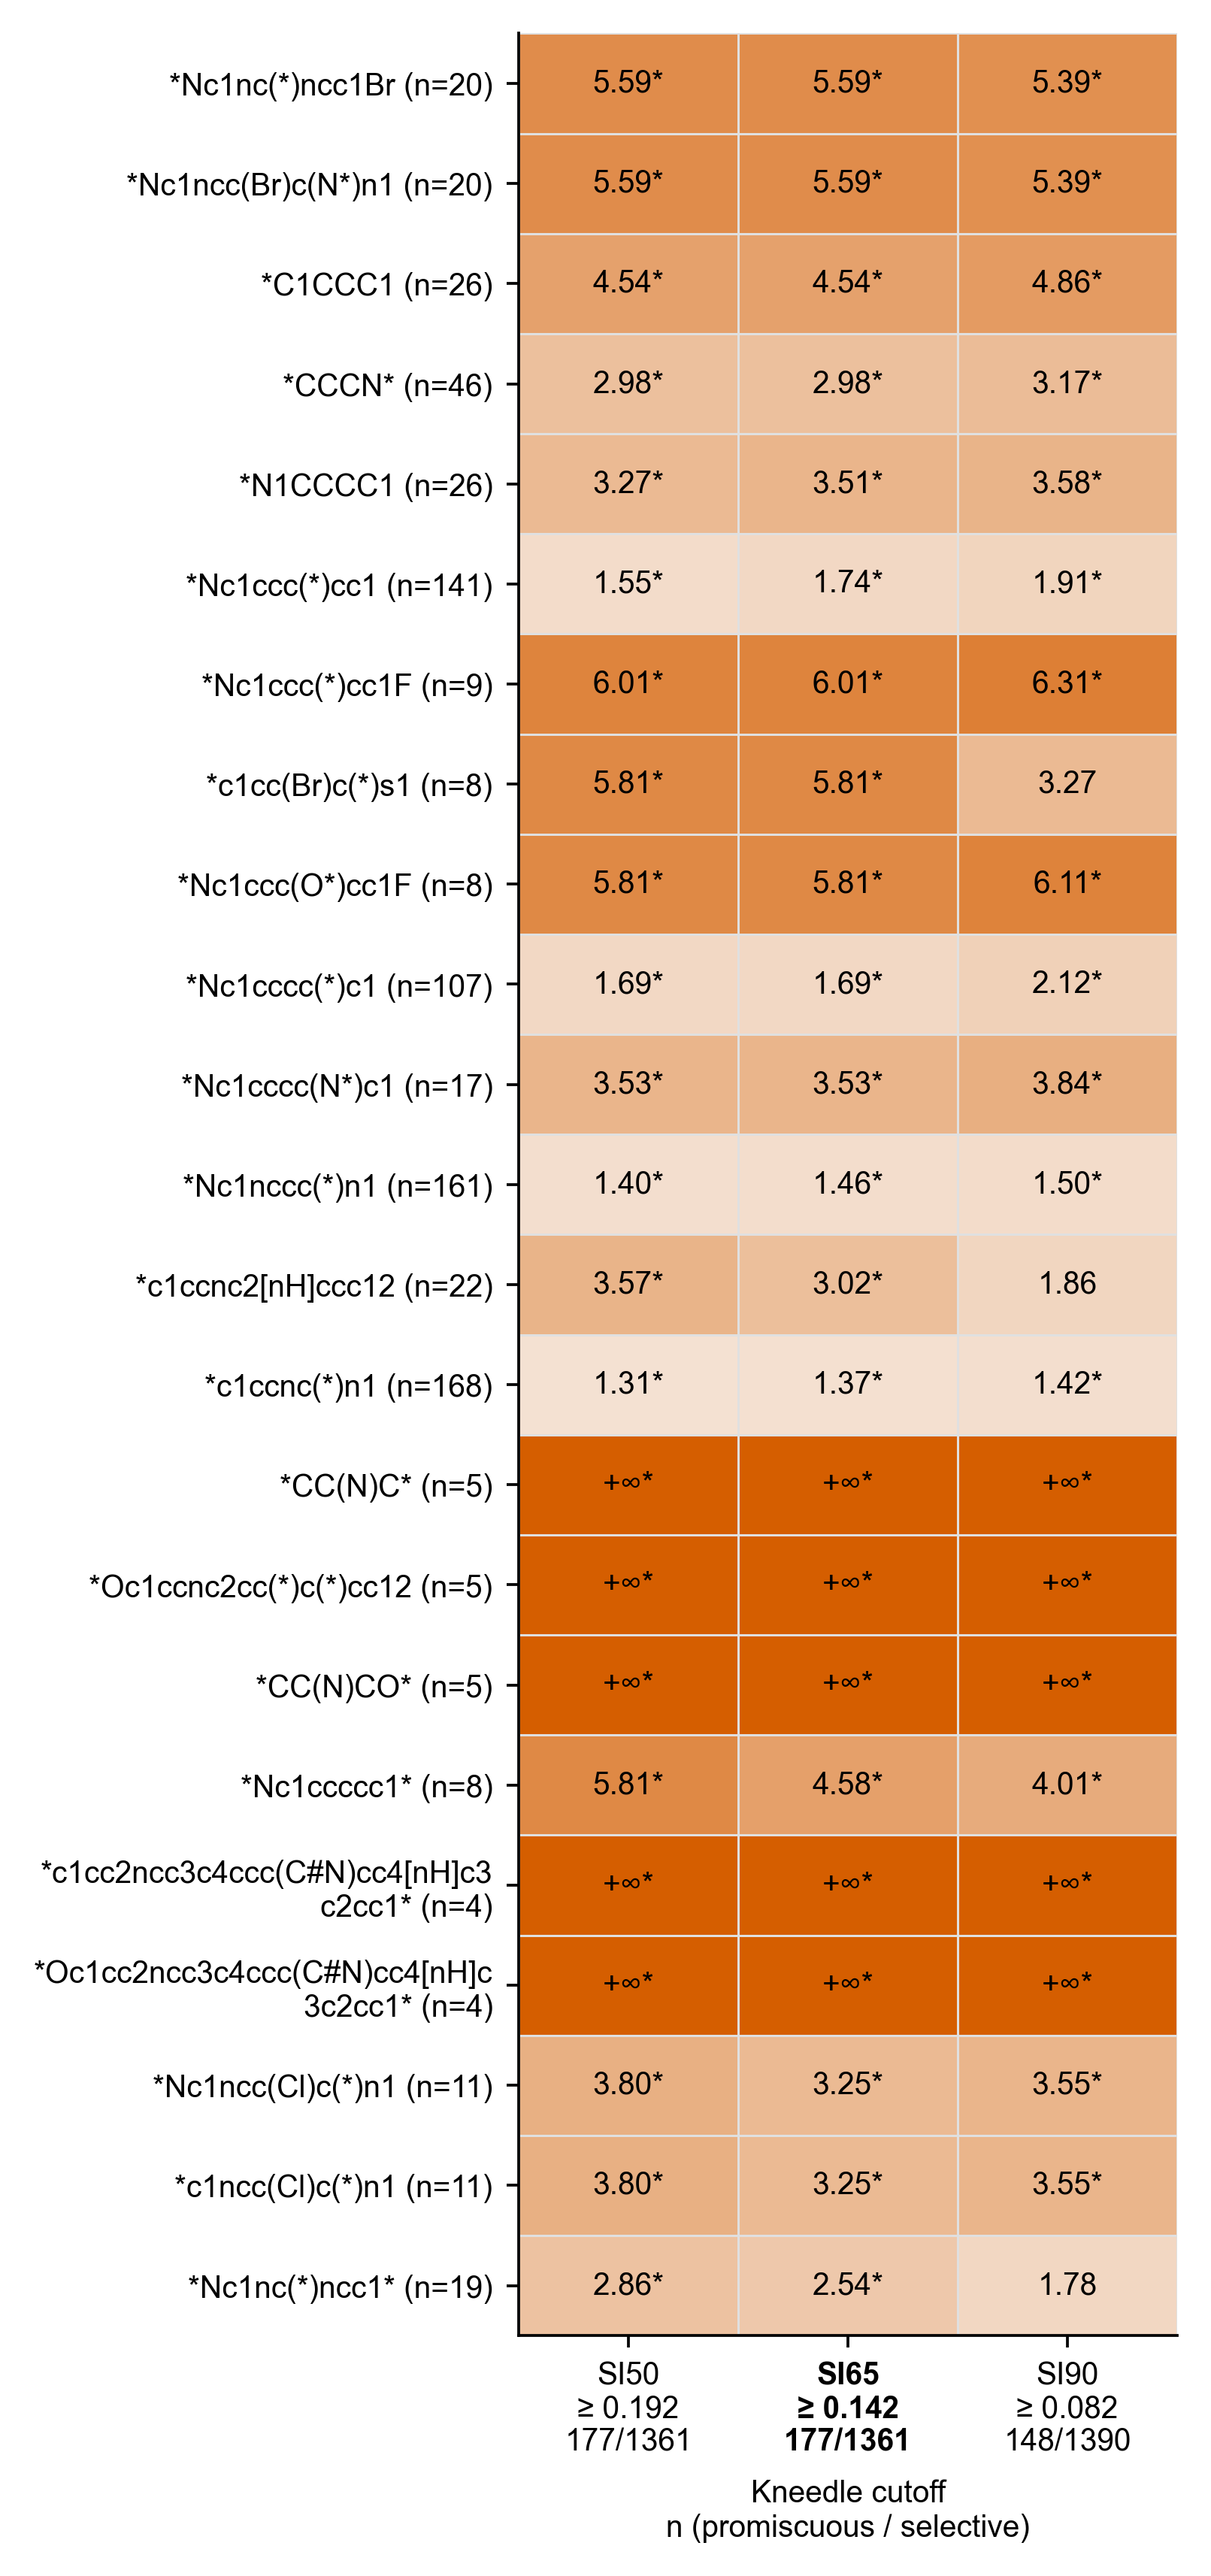

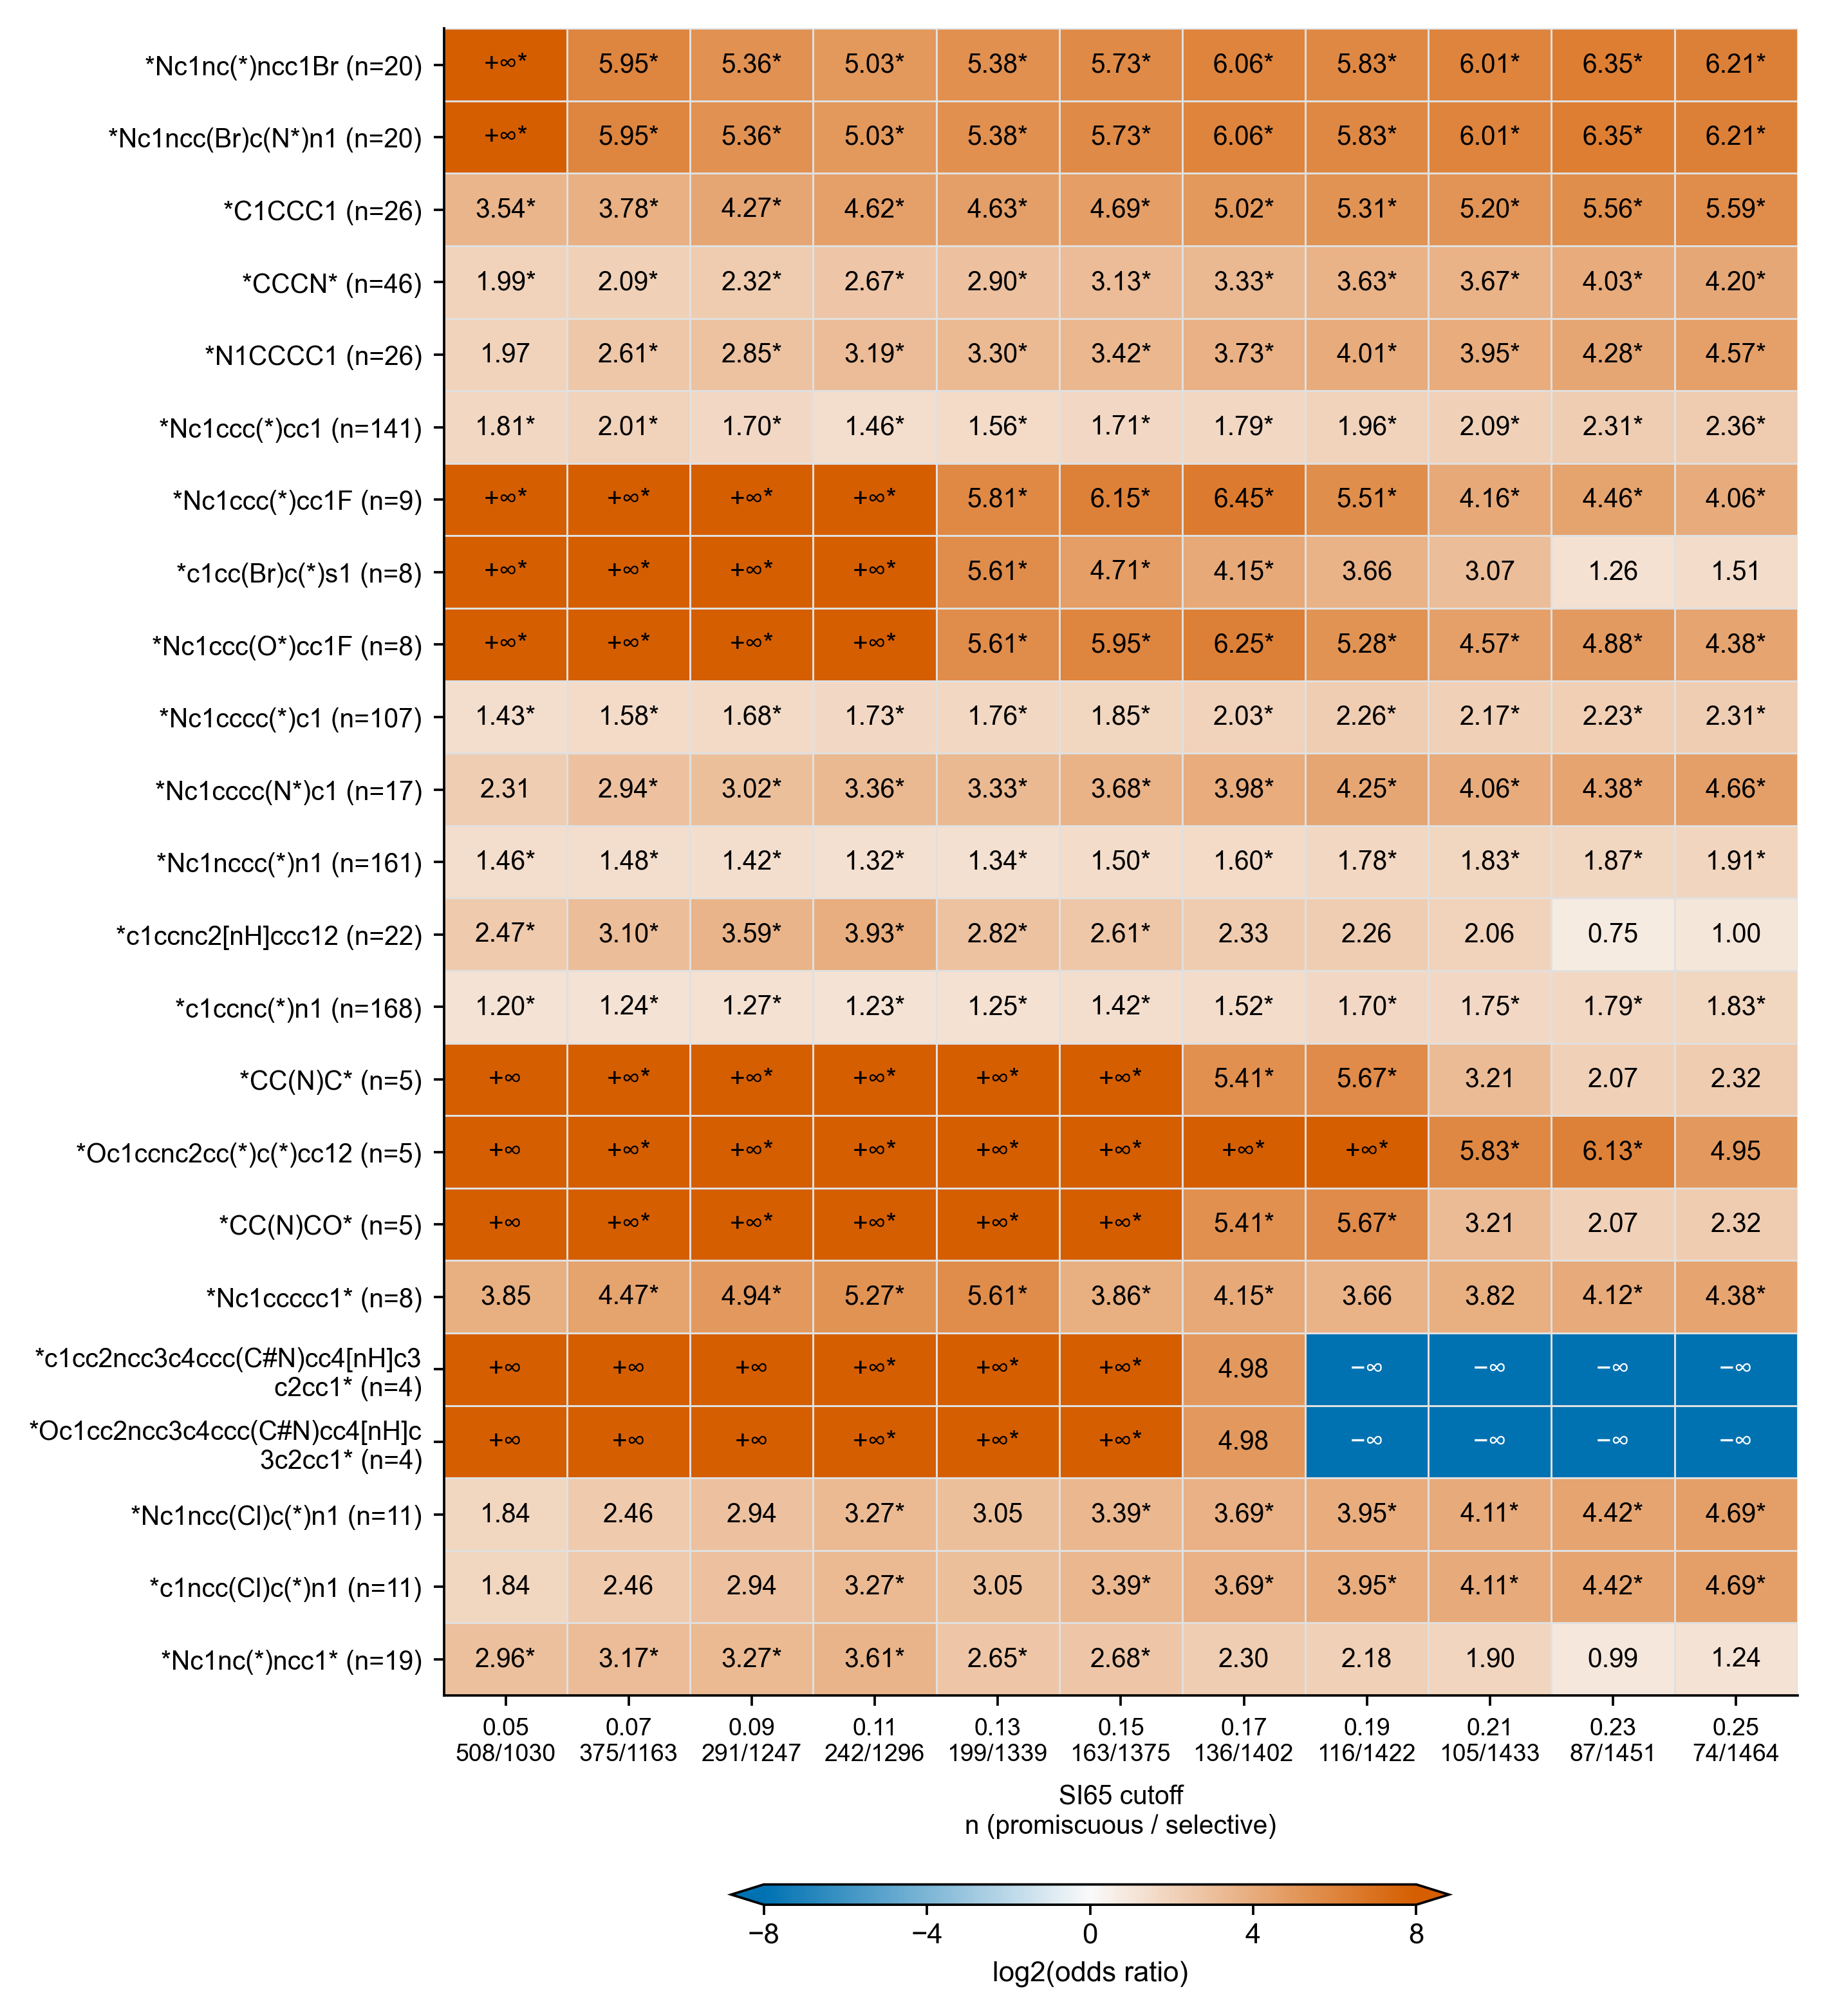

In [42]:
brics_matches = pd.DataFrame({
    smi: [smi in fragment_set for fragment_set in brics_compound_fragments]
    for smi in prom_brics_df['Fragment_SMILES']
}, index=kips_df.index)

def plot_brics_enrichment_sensitivity():
    assert brics_matches.index.equals(kips_df.index)
    brics_thresholds_df = pd.DataFrame(threshold_rows)
    threshold_by_definition = brics_thresholds_df.set_index('Definition')['Threshold']
    enrichment_frames = []
    for definition, metric, _ in SENSITIVITY_DEFINITIONS:
        labels = sensitivity_labels[definition]
        frame = sensitivity_enrichment(brics_matches, labels).rename(
            columns={'Scaffold_Name': 'Fragment_SMILES'})
        frame.insert(0, 'Definition', definition)
        frame['Metric'] = metric
        frame['Threshold'] = threshold_by_definition[definition]
        enrichment_frames.append(frame)

    brics_sensitivity_all = pd.concat(enrichment_frames, ignore_index=True)
    enriched_sets = {
        definition: set(frame.loc[frame['P_value_BH'].lt(P_VALUE_THRESHOLD), 'Fragment_SMILES'])
        for definition, frame in brics_sensitivity_all.groupby('Definition', sort=False)
    }
    baseline_set = enriched_sets[reference_definition]
    baseline_labels = sensitivity_labels[reference_definition]
    stability_rows = []
    for definition in definition_order:
        selected = enriched_sets[definition]
        union = selected | baseline_set
        stability_rows.append({
            'Definition': definition,
            'Label_Agreement': float((sensitivity_labels[definition] == baseline_labels).mean()),
            'Enriched_Set_Jaccard': len(selected & baseline_set) / len(union) if union else np.nan,
            'Reference_Enrichment_Retained': len(selected & baseline_set) / len(baseline_set) if baseline_set else np.nan,
            'Significant_Fragments_N': len(selected),
        })
    stability_df = pd.DataFrame(stability_rows)
    brics_thresholds_df = brics_thresholds_df.merge(stability_df, on='Definition', validate='one_to_one')

    brics_sensitivity_all.to_csv(os.path.join(SUPPORTING_DIR, 'BRICS_Sensitivity_Long.csv'), index=False)
    brics_thresholds_df.to_csv(os.path.join(SUPPORTING_DIR, 'BRICS_Sensitivity_Thresholds.csv'), index=False)
    brics_sensitivity_wide = brics_sensitivity_all.pivot(
        index='Fragment_SMILES', columns='Definition',
        values=['Log2_Odds_Ratio', 'Odds_Ratio', 'P_value_BH']
    )
    brics_sensitivity_wide.columns = [f'{definition}__{value}' for value, definition in brics_sensitivity_wide.columns]
    brics_sensitivity_wide.to_csv(os.path.join(SUPPORTING_DIR, 'BRICS_Sensitivity_Wide.csv'))
    label_export = kips_df[['Compound ID', 'InChI_Key']].copy()
    for definition, labels in sensitivity_labels.items():
        label_export[definition] = labels.astype(int)
    label_export.to_csv(os.path.join(SUPPORTING_DIR, 'BRICS_Sensitivity_Compound_Labels.csv'), index=False)

    enriched_rows = prom_brics_df.loc[prom_brics_df['P_value_BH'].lt(P_VALUE_THRESHOLD)].sort_values('-log10_P_BH', ascending=True)
    fragment_order = enriched_rows['Fragment_SMILES'].tolist()[::-1]
    if not fragment_order:
        raise ValueError('BRICS enrichment figure contains no significantly enriched BRICS fragments.')
    baseline_results = brics_sensitivity_all.loc[
        brics_sensitivity_all['Definition'].eq(reference_definition)
    ].set_index('Fragment_SMILES')
    np.testing.assert_allclose(
        baseline_results.loc[fragment_order, 'P_value_BH'],
        enriched_rows.set_index('Fragment_SMILES').loc[fragment_order, 'P_value_BH'],
        rtol=1e-10, atol=1e-14,
    )

    metric_effects = brics_sensitivity_all.pivot(
        index='Fragment_SMILES', columns='Definition', values='Log2_Odds_Ratio'
    ).reindex(index=fragment_order, columns=metric_definitions)
    metric_q = brics_sensitivity_all.pivot(
        index='Fragment_SMILES', columns='Definition', values='P_value_BH'
    ).reindex(index=fragment_order, columns=metric_definitions)

    sweep_frames = []
    for cutoff in si65_cutoffs:
        labels = si65_cutoff_labels[cutoff]
        frame = sensitivity_enrichment(brics_matches, labels).rename(
            columns={'Scaffold_Name': 'Fragment_SMILES'})
        frame.insert(0, 'SI65_Cutoff', cutoff)
        frame['Compounds_N'] = len(labels)
        frame['Promiscuous_N'] = int(labels.sum())
        frame['Selective_N'] = int((~labels).sum())
        frame['BRICS_Enriched'] = frame['Fragment_SMILES'].isin(fragment_order)
        sweep_frames.append(frame)
    brics_cutoff_sweep = pd.concat(sweep_frames, ignore_index=True)
    brics_cutoff_sweep.to_csv(
        os.path.join(SUPPORTING_DIR, 'BRICS_SI65_Cutoff_Sweep.csv'), index=False)
    sweep_effects_all = brics_cutoff_sweep.pivot(
        index='Fragment_SMILES', columns='SI65_Cutoff', values='Log2_Odds_Ratio')
    sweep_q_all = brics_cutoff_sweep.pivot(
        index='Fragment_SMILES', columns='SI65_Cutoff', values='P_value_BH')
    cutoff_counts = brics_cutoff_sweep.groupby('SI65_Cutoff')[['Promiscuous_N', 'Selective_N']].first()
    # Follow only the initially enriched patterns at every cutoff.
    wide_order = fragment_order
    hit_counts = baseline_results['Total_Hits']

    displayed_values = np.concatenate([
        metric_effects.to_numpy().ravel(),
        sweep_effects_all.loc[fragment_order, main_cutoffs].to_numpy().ravel(),
        sweep_effects_all.loc[wide_order, wide_cutoffs].to_numpy().ravel(),
    ])
    finite_values = displayed_values[np.isfinite(displayed_values)]
    effect_bound = max(2., float(2 * np.ceil(np.abs(finite_values).max() / 2))) if finite_values.size else 2.
    effect_cmap = LinearSegmentedColormap.from_list(
        'brics_log2_odds', [MAIN_COLORS['blue'], '#fafafa', MAIN_COLORS['vermillion']])
    effect_cmap.set_bad('#dedede')


    def _draw_brics_effect_heatmap(ax, values, q_frame, row_names, show_y=True):
        color_values = values.replace({np.inf: effect_bound, -np.inf: -effect_bound})
        mesh = ax.pcolormesh(np.ma.masked_invalid(color_values.to_numpy()), cmap=effect_cmap,
                             vmin=-effect_bound, vmax=effect_bound, edgecolors='#e0e0e0',
                             linewidth=.45, rasterized=False)
        ax.set_ylim(len(row_names), 0)
        ax.set_xlim(0, len(values.columns))
        ax.set_yticks(np.arange(len(row_names)) + .5)
        ax.tick_params(length=2.5, width=.6, pad=3, labelsize=7)
        ax.spines[['top', 'right']].set_visible(False)
        ax.spines[['left', 'bottom']].set_linewidth(.6)
        if show_y:
            ax.set_yticklabels([
                textwrap.fill(str(name).replace('\x97', '-'), 29) + f' (n={int(hit_counts[name])})'
                for name in row_names], fontsize=6.5)
        else:
            ax.tick_params(axis='y', left=False, labelleft=False)
        for row in range(len(row_names)):
            for col in range(len(values.columns)):
                value = values.iloc[row, col]
                label = ('NA' if np.isnan(value) else '+∞' if np.isposinf(value)
                         else '−∞' if np.isneginf(value) else f'{value:.2f}')
                if q_frame.iloc[row, col] < P_VALUE_THRESHOLD:
                    label += '*'
                rgba = effect_cmap((np.clip(value, -effect_bound, effect_bound) + effect_bound) / (2 * effect_bound))
                # Choose black or white from the actual background luminance.
                rgb = np.array(rgba[:3])
                luminance = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4) @ [.2126, .7152, .0722]
                text_color = 'black' if luminance > .179 else 'white'
                ax.text(col + .5, row + .5, label, ha='center', va='center',
                        fontsize=6.5, color=text_color)
        return mesh


    def _brics_effect_colorbar(fig, mesh, rect):
        cax = fig.add_axes(rect)
        bar = fig.colorbar(mesh, cax=cax, orientation='horizontal', extend='both',
                           ticks=[-effect_bound, -effect_bound / 2, 0, effect_bound / 2, effect_bound])
        bar.set_label('log2(odds ratio)', fontsize=7, labelpad=3)
        bar.ax.tick_params(labelsize=7, length=2.5, width=.6, pad=2)
        bar.outline.set_linewidth(.6)
        bar.solids.set_rasterized(False)
        return bar


    with plt.rc_context({'savefig.bbox': None}):
        metric_plot_height = metric_heatmap_row_height * len(fragment_order)
        metric_height = metric_bottom_margin + metric_plot_height + metric_top_margin
        fig = plt.figure(figsize=(3.54, metric_height))
        ax_metric = fig.add_axes([.43, metric_bottom_margin / metric_height,
                                  .55, metric_plot_height / metric_height])
        metric_mesh = _draw_brics_effect_heatmap(ax_metric, metric_effects, metric_q, fragment_order)
        metric_counts = brics_thresholds_df.set_index('Definition').loc[metric_definitions]
        ax_metric.set_xticks(np.arange(3) + .5, [
            f"{row['Metric']}\n≥ {row['Threshold']:.3f}\n{int(row['Promiscuous_N'])}/{int(row['Selective_N'])}"
            for _, row in metric_counts.iterrows()], fontsize=6.5)
        ax_metric.get_xticklabels()[1].set_fontweight('bold')
        ax_metric.set_xlabel('Kneedle cutoff\nn (promiscuous / selective)', labelpad=5, fontsize=6.5)
        for ext in ('pdf', 'png'):
            fig.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, f'Supplementary_Figure_8_BRICS_Threshold_Sensitivity.{ext}'))
        plt.show()

        wide_height = max(3.5, .245 * len(wide_order) + 1.1) + sweep_colorbar_gap
        fig_wide = plt.figure(figsize=(7.08, wide_height))
        ax_wide = fig_wide.add_axes([.32, sweep_bottom_margin / wide_height, .66,
                                    (wide_height - sweep_bottom_margin - sweep_top_margin) / wide_height])
        wide_mesh = _draw_brics_effect_heatmap(ax_wide,
            sweep_effects_all.loc[wide_order, wide_cutoffs],
            sweep_q_all.loc[wide_order, wide_cutoffs], wide_order)
        ax_wide.set_xticks(np.arange(len(wide_cutoffs)) + .5, [
            f"{c:.2f}\n{int(cutoff_counts.loc[c, 'Promiscuous_N'])}/{int(cutoff_counts.loc[c, 'Selective_N'])}"
            for c in wide_cutoffs], fontsize=6)
        ax_wide.set_xlabel('SI65 cutoff\nn (promiscuous / selective)', fontsize=6.5, labelpad=5)
        _brics_effect_colorbar(fig_wide, wide_mesh,
            [.46, sweep_colorbar_bottom / wide_height, .35, sweep_colorbar_height / wide_height])
        for ext in ('pdf', 'png'):
            fig_wide.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, f'Supplementary_Figure_9_BRICS_Cutoff_Sensitivity.{ext}'))
        plt.show()

plot_brics_enrichment_sensitivity()

# Chemical Space UMAP

SMARTS patterns can overlap. Among enriched matches only, assign the query with most heavy atoms, breaking ties by name

UMAP ECFP4 fingerprints: 100%|██████████| 1538/1538 [00:00<00:00, 9570.96it/s]
c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\umap\umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(


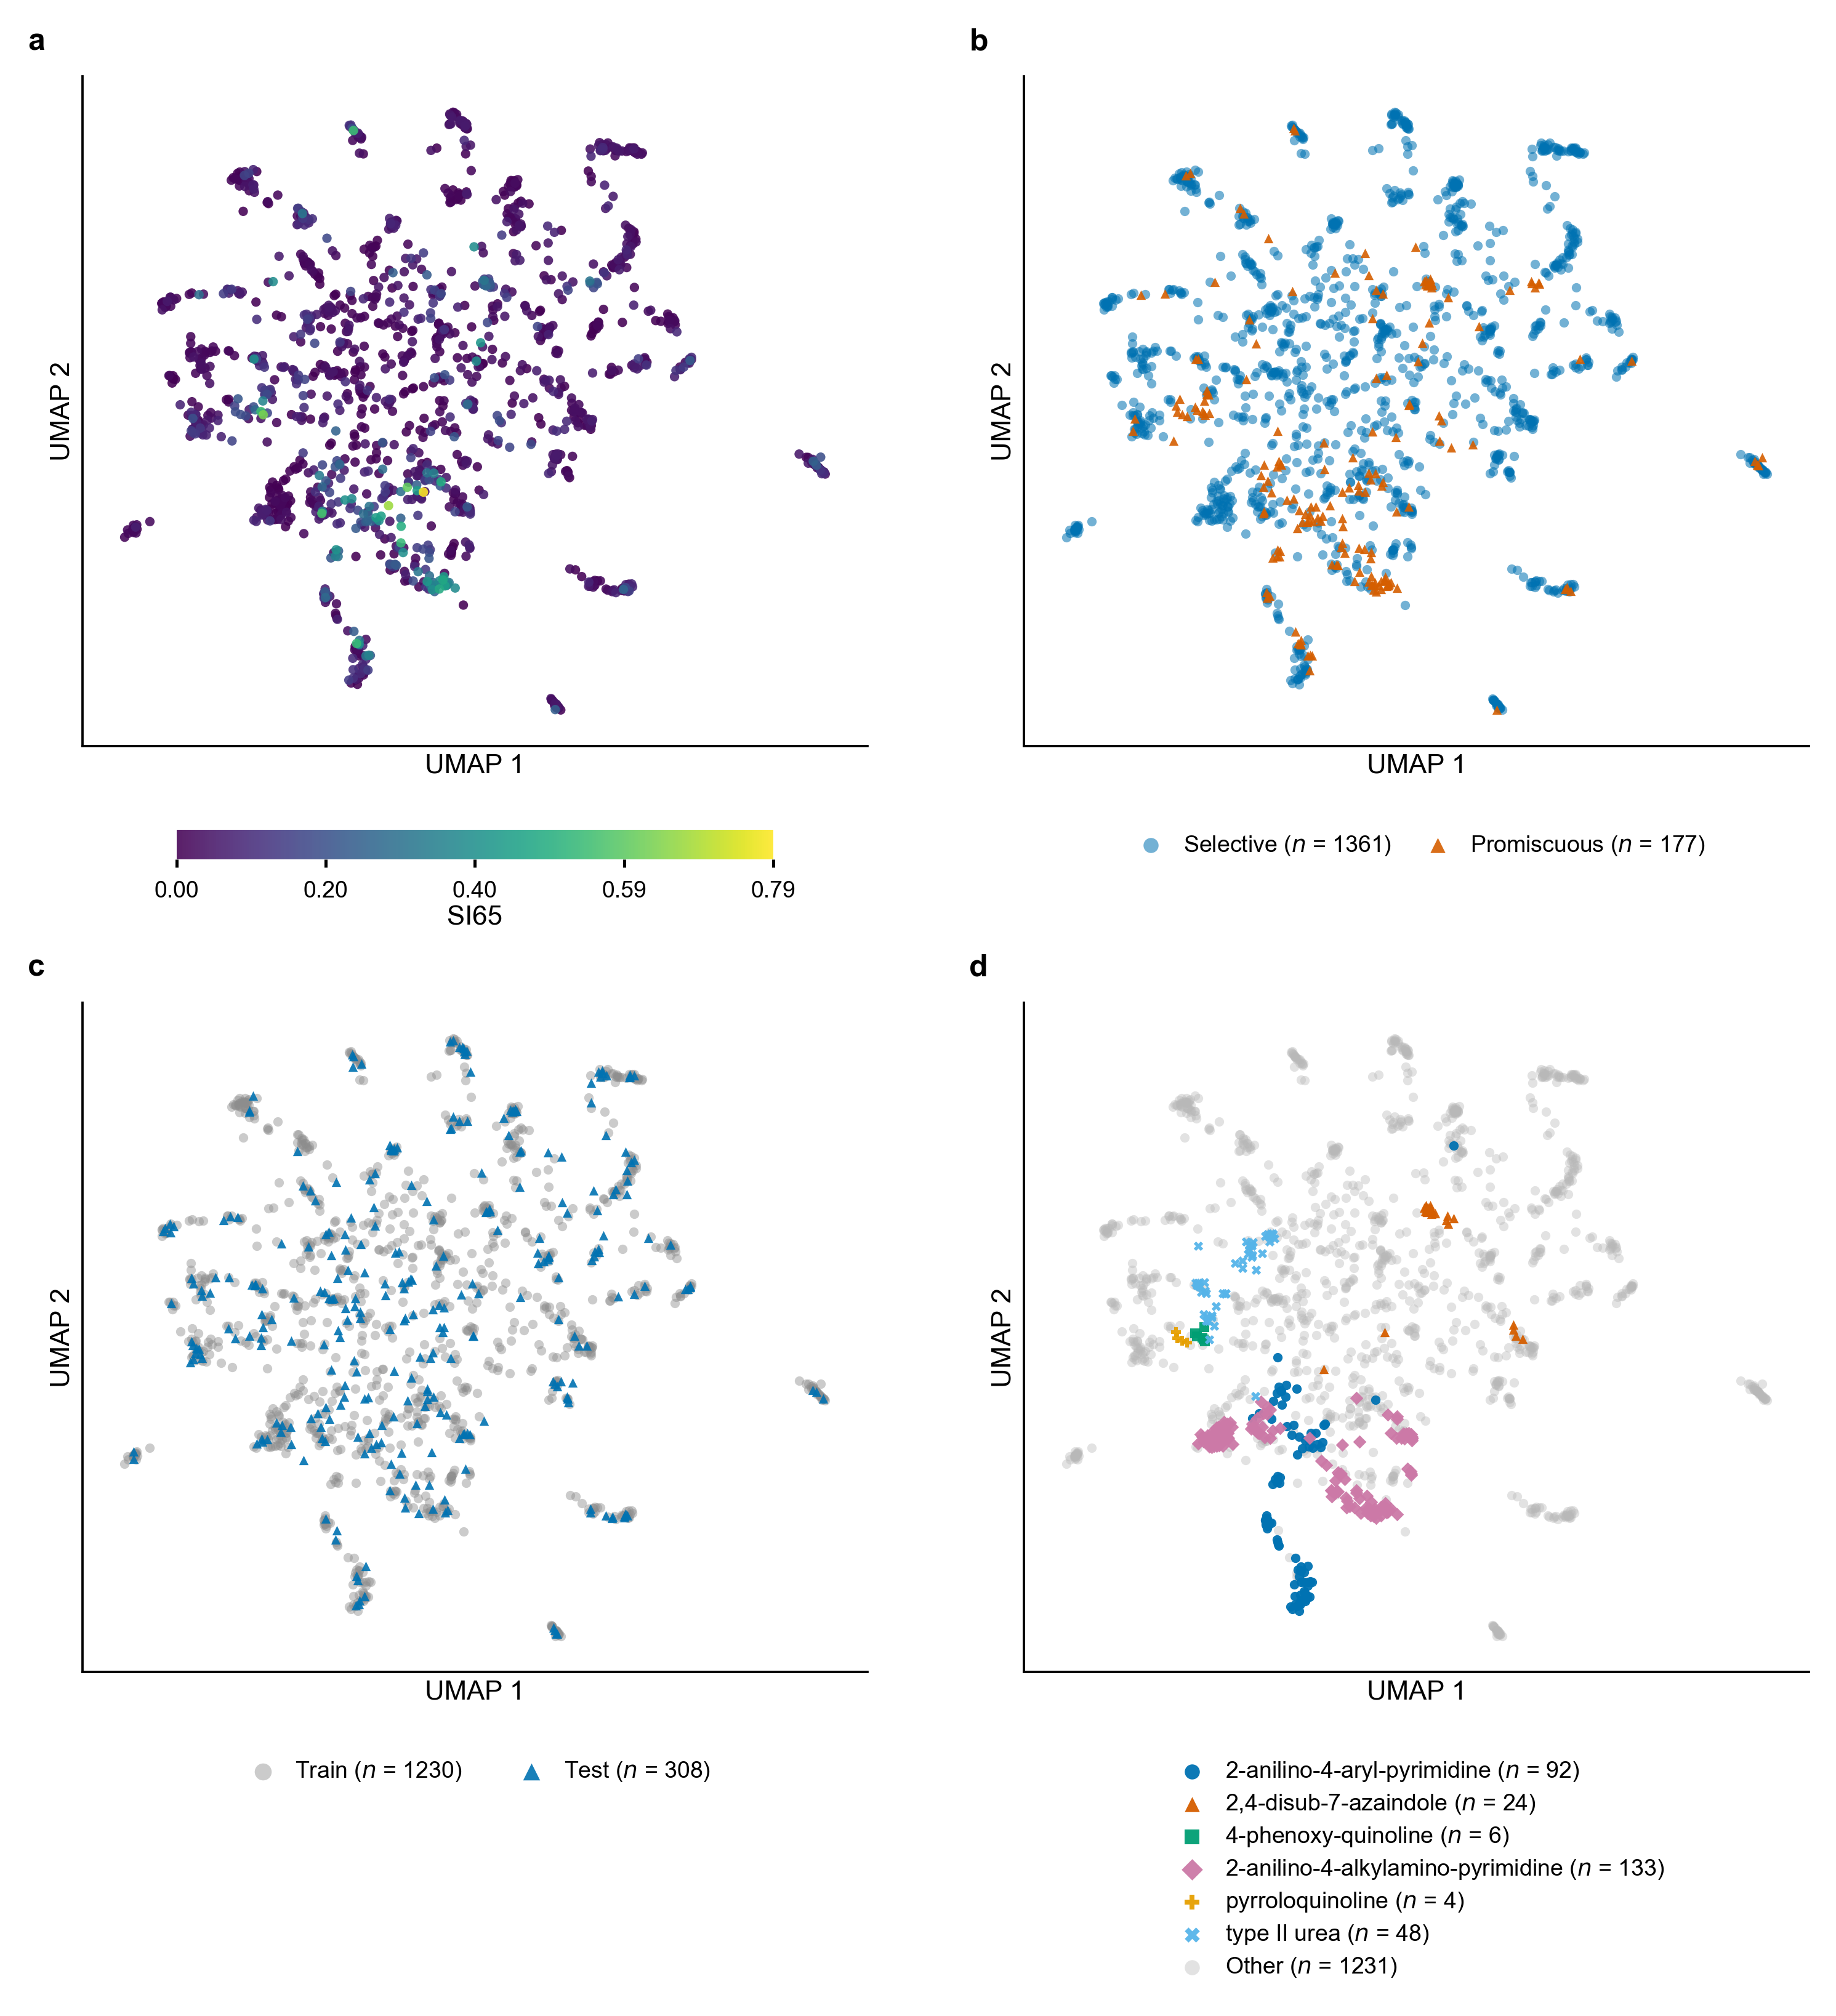

UMAP: 1538 compounds; 308 test compounds.
388 compounds match multiple SMARTS; all memberships exported.
                                   Compounds_N  Promiscuous_N  Median_SI65  Max_SI65  Promiscuous_Fraction  Share_of_All_Promiscuous
SMARTS_group                                                                                                                        
2-anilino-4-aryl-pyrimidine                 92             38     0.105263  0.534211              0.413043                  0.214689
2,4-disub-7-azaindole                       24             12     0.135526  0.310526              0.500000                  0.067797
4-phenoxy-quinoline                          6              6     0.314474  0.634211              1.000000                  0.033898
2-anilino-4-alkylamino-pyrimidine          133             33     0.044737  0.481579              0.248120                  0.186441
pyrroloquinoline                             4              4     0.181579  0.186842             

In [43]:
umap_df = kips_df[['Compound ID', 'InChI_Key', 'SMILES_standardized', 'mol_std', 'SI65', 'is_promiscuous']].copy().reset_index(drop=True)
umap_df['Class'] = umap_df['is_promiscuous'].map({False: 'Selective', True: 'Promiscuous'})

umap_train, umap_test = train_test_split(umap_df, test_size=.2, stratify=umap_df['is_promiscuous'], random_state=RANDOM_SEED)
umap_df['Split'] = 'Train'
umap_df.loc[umap_test.index, 'Split'] = 'Test'
umap_fingerprints = np.zeros((len(umap_df), FP_NBITS), dtype=np.uint8)
for row, mol in enumerate(tqdm(umap_df['mol_std'], desc='UMAP ECFP4 fingerprints')):
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, FP_RADIUS, nBits=FP_NBITS, useChirality=True)
    DataStructs.ConvertToNumpyArray(fp, umap_fingerprints[row])

umap_parameters = dict(n_components=2, n_neighbors=30, min_dist=.15, metric='jaccard', random_state=RANDOM_SEED, transform_seed=RANDOM_SEED, n_jobs=1)

dataset_umap = umap.UMAP(**umap_parameters)
dataset_embedding = dataset_umap.fit_transform(umap_fingerprints.astype(bool))
umap_df[['UMAP1', 'UMAP2']] = dataset_embedding

if not matches.index.equals(kips_df.index):
    raise ValueError('SMARTS rows are not aligned with the curated compounds.')
scaffold_priority = sorted(smarts_patterns, key=lambda name: (-smarts_patterns[name].GetNumHeavyAtoms(), name))
enriched_scaffolds = prom_df.loc[prom_df['P_value_BH'].lt(P_VALUE_THRESHOLD)].sort_values(
    ['P_value_BH', 'Scaffold_Name'])['Scaffold_Name'].tolist()
unknown_scaffolds = set(enriched_scaffolds) - set(smarts_patterns)
if unknown_scaffolds:
    raise ValueError(f'Enriched SMARTS missing from the matching dictionary: {unknown_scaffolds}')
enriched_set = set(enriched_scaffolds)
all_memberships = [[name for name in scaffold_priority if row[name]]
                   for _, row in matches.iterrows()]
enriched_memberships = [[name for name in names if name in enriched_set] for names in all_memberships]
umap_df['SMARTS_matches'] = ['; '.join(names) for names in all_memberships]
umap_df['SMARTS_match_count'] = [len(names) for names in all_memberships]
umap_df['Enriched_SMARTS_matches'] = ['; '.join(names) for names in enriched_memberships]
umap_df['Enriched_SMARTS_match_count'] = [len(names) for names in enriched_memberships]
umap_df['Primary_SMARTS'] = [names[0] if names else 'Other' for names in enriched_memberships]
umap_df['SMARTS_group'] = umap_df['Primary_SMARTS']
scaffold_summary = umap_df.groupby('SMARTS_group').agg(
    Compounds_N=('Compound ID', 'size'), Promiscuous_N=('is_promiscuous', 'sum'),
    Median_SI65=('SI65', 'median'), Max_SI65=('SI65', 'max'),
).reindex(enriched_scaffolds + ['Other'])
scaffold_summary['Promiscuous_Fraction'] = scaffold_summary['Promiscuous_N'] / scaffold_summary['Compounds_N']
scaffold_summary['Share_of_All_Promiscuous'] = scaffold_summary['Promiscuous_N'] / umap_df['is_promiscuous'].sum()

umap_df.drop(columns='mol_std').to_csv(os.path.join(SUPPORTING_DIR, 'UMAP_Coordinates.csv'), index=False)
scaffold_summary.to_csv(os.path.join(SUPPORTING_DIR, 'UMAP_Scaffold_Composition.csv'))
Path(SUPPORTING_DIR, 'UMAP_Parameters.json').write_text(json.dumps({
    **umap_parameters, 'fingerprint': 'Morgan/ECFP', 'radius': FP_RADIUS,
    'n_bits': FP_NBITS, 'use_chirality': True, 'test_size': .2,
    'compounds_n': len(umap_df), 'SI65_class_cutoff': float(elbow_si65_threshold),
    'scaffold_assignment': 'Primary SI65 BH-enriched matches only; most query heavy atoms, then name; remainder Other',
    'displayed_enriched_smarts': enriched_scaffolds,
    'split_source': 'Reproduces notebook 05 on the same ordered curated input',
}, indent=2), encoding='utf-8')

fig = plt.figure(figsize=(7.08, 7.35))
embedding_span = np.ptp(dataset_embedding, axis=0)
panel_width = .40
panel_height = panel_width * 7.08 / 7.35 * embedding_span[1] / embedding_span[0]
axes = np.array([fig.add_axes([left, top - panel_height, panel_width, panel_height])
                 for top in (.97, .515) for left in (.07, .55)])
base_points = dict(s=6, linewidths=0, rasterized=True)
# Draw larger SI values last to avoid concealment
continuous_order = umap_df.sort_values('SI65', kind='stable')
si65_vmax = float(umap_df['SI65'].max())
scatter = axes[0].scatter(continuous_order['UMAP1'], continuous_order['UMAP2'],
                           c=continuous_order['SI65'], cmap='viridis', vmin=0, vmax=si65_vmax,
                           alpha=.88, **base_points)
color_ax = axes[0].inset_axes([.12, -.17, .76, .045])
cbar = fig.colorbar(scatter, cax=color_ax, orientation='horizontal', ticks=np.linspace(0, si65_vmax, 5), format='%.2f')
cbar.set_label('SI65', labelpad=1)
cbar.ax.tick_params(labelsize=6, length=2)
cbar.outline.set_visible(False)

for name, color, marker in [('Selective', MAIN_COLORS['blue'], 'o'),
                             ('Promiscuous', MAIN_COLORS['vermillion'], '^')]:
    part = umap_df[umap_df['Class'].eq(name)]
    axes[1].scatter(part['UMAP1'], part['UMAP2'], color=color, marker=marker,
                    alpha=.55 if name == 'Selective' else .9,
                    label=f'{name} ($n$ = {len(part)})', **base_points)
axes[1].legend(loc='upper center', bbox_to_anchor=(.5, -.10), frameon=False,
               ncol=2, fontsize=6, markerscale=1.6, handletextpad=.4, columnspacing=1.)
for name, color, marker in [('Train', '#8d8d8d', 'o'), ('Test', MAIN_COLORS['blue'], '^')]:
    part = umap_df[umap_df['Split'].eq(name)]
    axes[2].scatter(part['UMAP1'], part['UMAP2'], color=color, marker=marker,
                    alpha=.45 if name == 'Train' else .9,
                    label=f'{name} ($n$ = {len(part)})', **base_points)
axes[2].legend(loc='upper center', bbox_to_anchor=(.5, -.10), frameon=False,
               ncol=2, fontsize=6, markerscale=1.8, handletextpad=.4)

scaffold_colors = [MAIN_COLORS[key] for key in ['blue', 'vermillion', 'bluishgreen', 'reddishpurple', 'orange', 'skyblue']]
scaffold_shapes = ['o', '^', 's', 'D', 'P', 'X']
scaffold_palette = {name: scaffold_colors[i % len(scaffold_colors)] for i, name in enumerate(enriched_scaffolds)}
scaffold_markers = {name: scaffold_shapes[i % len(scaffold_shapes)] for i, name in enumerate(enriched_scaffolds)}
scaffold_palette['Other'], scaffold_markers['Other'] = '#b8b8b8', 'o'
scaffold_handles = {}
for name in ['Other'] + enriched_scaffolds:
    part = umap_df[umap_df['SMARTS_group'].eq(name)]
    points = axes[3].scatter(part['UMAP1'], part['UMAP2'], color=scaffold_palette[name],
                             marker=scaffold_markers[name], alpha=.4 if name == 'Other' else .95,
                             label=f'{name} ($n$ = {len(part)})', **base_points)
    scaffold_handles[name] = points
scaffold_legend = axes[3].legend(
    handles=[scaffold_handles[name] for name in enriched_scaffolds + ['Other']],
    loc='upper center', bbox_to_anchor=(.5, -.10), bbox_transform=axes[3].transAxes,
    frameon=False,
    ncol=1, fontsize=6, markerscale=1.6, handletextpad=.45,
    labelspacing=.4)

mins, maxs = dataset_embedding.min(axis=0), dataset_embedding.max(axis=0)
padding = (maxs - mins) * .06
for ax, letter in zip(axes, 'abcd'):
    ax.set_xlim(mins[0] - padding[0], maxs[0] + padding[0])
    ax.set_ylim(mins[1] - padding[1], maxs[1] + padding[1])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('UMAP 1', labelpad=2)
    ax.set_ylabel('UMAP 2', labelpad=2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['bottom', 'left']].set_linewidth(.6)
    ax.text(-.07, 1.04, letter, transform=ax.transAxes, fontweight='bold', fontsize=8)
fig.canvas.draw()
legend_box = scaffold_legend.get_window_extent(fig.canvas.get_renderer())
panel_d_box = axes[3].get_window_extent()
assert (legend_box.x0 >= panel_d_box.x0 and legend_box.x1 <= panel_d_box.x1
        and legend_box.y1 < panel_d_box.y0 and legend_box.y0 >= fig.bbox.y0)
assert not legend_box.overlaps(axes[2].get_legend().get_window_extent(fig.canvas.get_renderer()))
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(SUPPLEMENTARY_FIGURES_DIR, f'Supplementary_Figure_11_UMAP.{ext}'))
plt.show()
print(f'UMAP: {len(umap_df)} compounds; {umap_df["Split"].eq("Test").sum()} test compounds.')
print(f'{umap_df["SMARTS_match_count"].gt(1).sum()} compounds match multiple SMARTS; all memberships exported.')
print(scaffold_summary.to_string())

# Export KIPS training and test datasets


In [44]:
for split_name, split_df in [('Train', umap_train), ('Test', umap_test)]:
    kips_df.loc[split_df.index, kips_export_cols].rename(
        columns={'SMILES_standardized': 'SMILES'}
    ).to_csv(os.path.join(KIPS_DIR, f'KIPS_{split_name}.csv'), index=False)